# Sakila from Cloud SQL into Snowflake, then OLTP → OLAP

One notebook with everything built for migration, model, questions, dashboard and reflection. AI verification (the Claude checks, the decisions and the prompt log) is its own file, `docs/ai_verification.md`.

| Section | Contents | Where |
|---|---|---|
| Migrate Sakila into Snowflake | migration code and commands · row-count table, source vs Snowflake · note on the data types | *Migration* below |
| OLTP → OLAP | the dimensional model in `SAKILA.DW`: DDL with grain COMMENTs, two Type 2 dimensions, loads as MERGE, the normalized copy kept | *Dimensional model* below |
| Show it works, find where it doesn't | three business questions on both models · the history exercised · one question the model answers badly | *Business questions* below |
| A Streamlit app on the star | `app/streamlit_app.py` · two screenshots (unfiltered, filtered) · the Check expander proving every number against the normalized copy | *Dashboard* below |
| Claude explains; Snowflake decides | the checks, my decisions, the prompt log | its own file, `docs/ai_verification.md` (not in this notebook) |
| Reflection | why this grain · what broke · what would break first at scale | *Reflection* below |

**State at the time this notebook was run:** `SAKILA.OLTP` has the 16 base tables, 22 foreign keys and 47,268 rows of the source, identical in every table; `SAKILA.DW` has 5 dimensions and 2 facts that reconcile to it (57 checks, all OK). The cells that say *live* query Snowflake through the Snowflake CLI connection `claude` (SELECT only) when the notebook runs; the cells that say *saved log* replay the output of scripts that change data inside a transaction and **roll back**, so the notebook itself never writes.

**Two caveats up front.** (1) The "source" counts of Migration come from `sakila-data.sql`, the file that was imported into Cloud SQL. They agree with the counts recorded from the live Cloud SQL instance in the Cloud SQL project (film 1,000 · actor 200 · customer 599 · rental 16,044 · payment 16,044 · SUM(amount) 67,406.56), but I did not query the live instance (it needs the MySQL root password); `sql/00_source_counts_mysql.sql` runs the same counts there. (2) The Sakila sample data has no history of its own, so the Type 2 dimensions start with one version per row; Dimensional model and Business questions prove they work by changing the source inside a transaction that is rolled back.

In [1]:
import json, os, re, shutil, subprocess
import pandas as pd

pd.set_option("display.width", 220, "display.max_colwidth", 90, "display.max_rows", 200)
SNOW = shutil.which("snow") or os.path.expanduser("~/.local/bin/snow")


def snow(sql, db="SAKILA", schema="OLTP"):
    """Run ONE SELECT through the Snowflake CLI connection `claude` and return a DataFrame."""
    out = subprocess.run([SNOW, "sql", "-c", "claude", "--database", db, "--schema", schema, "--format", "json", "-q", sql],
                         capture_output=True, text=True)
    if out.returncode:
        raise RuntimeError(out.stdout + out.stderr)
    df = pd.DataFrame(json.loads(out.stdout))
    df.columns = [c.lower() for c in df.columns]
    return df


def statements(path):
    """The statements of a .sql file: comment lines dropped, split on ';' (none of the files has a ';' inside a string)."""
    text = "\n".join(l for l in open(path, encoding="utf-8").read().splitlines() if not l.lstrip().startswith("--"))
    return [s.strip() for s in text.split(";") if s.strip()]


def run_selects(path, keep=lambda s: s.upper().startswith(("SELECT", "WITH"))):
    """Run the read-only statements of a file live; return their DataFrames."""
    return [snow(s) for s in statements(path) if keep(s)]


def log_tables(path, keep=lambda block: True):
    """Print the result tables of a saved `snow sql -f` log (not the echoed SQL, not the 'status' tables)."""
    blocks, cur = [], []
    for line in open(path, encoding="utf-8").read().splitlines():
        if line.startswith(("+", "|")):
            cur.append(line)
        elif cur:
            blocks.append(cur)
            cur = []
    if cur:
        blocks.append(cur)
    for b in blocks:
        text = "\n".join(b)
        if "| status" in text or "Statement executed" in text:
            continue
        if keep(text):
            print(text, "\n")

---
# Migration — Migrate Sakila from Cloud SQL (MySQL 8.0) into Snowflake
## Migration code and commands

**Method:** parse the dump → 16 CSVs → upload to an internal Snowflake stage → `COPY INTO` → reconcile. The CSVs are written by code, not by hand.

```bash
# 1. Source → CSV (reads the dump that was imported into Cloud SQL; writes data/csv/*.csv, source_counts.csv, source_control_totals.csv)
python3 -I src/export_sakila_csv.py | tee evidence/export_log.txt

# 2. Snowsight, as SYSADMIN: run sql/01_oltp_ddl.sql  (database, schema, 16 tables, file format, stage)

# 3. Upload the 16 CSVs to the stage
snow stage copy "data/csv/*.csv" @SAKILA.OLTP.SAKILA_STAGE -c claude --role SYSADMIN --overwrite

# 4. Load and reconcile: sql/02_oltp_load_reconcile.sql  (16 COPY INTO, then counts, control totals, key and foreign-key checks)
snow sql -c claude -f sql/02_oltp_load_reconcile.sql | tee evidence/load_log.txt

# 5. (optional) confirm the source numbers on the live Cloud SQL instance — asks for the root password, nothing is stored
cd <cloud-sql-project-folder> && source env.sh && gcloud sql connect "$INSTANCE" --user=root --quiet < sql/00_source_counts_mysql.sql
```

Problems met on the way, and what was changed (both are fixed in the files below):
1. `sql/01` failed with *"Default value data type does not match data type for column LAST_UPDATE"*: `CURRENT_TIMESTAMP()` returns a `TIMESTAMP_LTZ` and `SYSDATE()` a `TIMESTAMP_NTZ(9)`; neither is accepted as the default of a `TIMESTAMP_NTZ(0)` column. Tested on temporary tables; `CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0)` works and is now used for all 15 defaults.
2. The foreign-key check in `sql/02` compared `store.manager_staff_id` with a column `store` does not have (my typo). Fixed and re-run; the first failed run is visible in `evidence/load_log.txt`.

### 1A. `src/export_sakila_csv.py` — Cloud SQL dump → CSVs, source counts, control totals

```python
#!/usr/bin/env python3
"""Sakila (MySQL 8.0 / Cloud SQL) -> CSV files ready for Snowflake COPY INTO.

Reads the SAME file that was imported into Cloud SQL (sakila-db/sakila-data.sql, Sakila v1.5), parses every
INSERT, and writes one CSV per base table plus the source row counts and control totals.
Nothing here talks to a database; it only reads the dump and writes files.

Usage:  python3 -I src/export_sakila_csv.py [path/to/sakila-data.sql] [output_dir]
Defaults: the Cloud SQL project folder/sakila-db/sakila-data.sql  and  data/csv

CSV conventions (must match the file format in sql/01_oltp_ddl.sql):
  - UTF-8, comma delimited, one header row, fields quoted with " only when needed
  - SQL NULL is written as \\N (bare); an empty string is an empty field
  - BOOLEAN/TINYINT(1) as 1/0 · BLOB as upper-case hex (no 0x) · GEOMETRY as WKT 'POINT(x y)' (SRID 0, planar)
  - ENUM and SET are written as the same text MySQL shows (SET = comma-separated)
"""
import csv
import hashlib
import math
import os
import re
import struct
import sys
from decimal import Decimal

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
DUMP = sys.argv[1] if len(sys.argv) > 1 else os.path.join(ROOT, "sakila-db", "sakila-data.sql")
OUT = sys.argv[2] if len(sys.argv) > 2 else os.path.join(ROOT, "data", "csv")

# Column order of each base table, exactly as in sakila-schema.sql. Kind: s = pass through, bool, blob, geo.
SPEC = {
    "actor": ["actor_id", "first_name", "last_name", "last_update"],
    "address": ["address_id", "address", "address2", "district", "city_id", "postal_code", "phone", "location:geo", "last_update"],
    "category": ["category_id", "name", "last_update"],
    "city": ["city_id", "city", "country_id", "last_update"],
    "country": ["country_id", "country", "last_update"],
    "customer": ["customer_id", "store_id", "first_name", "last_name", "email", "address_id", "active:bool", "create_date", "last_update"],
    "film": ["film_id", "title", "description", "release_year", "language_id", "original_language_id", "rental_duration",
             "rental_rate", "length", "replacement_cost", "rating", "special_features", "last_update"],
    "film_actor": ["actor_id", "film_id", "last_update"],
    "film_category": ["film_id", "category_id", "last_update"],
    "inventory": ["inventory_id", "film_id", "store_id", "last_update"],
    "language": ["language_id", "name", "last_update"],
    "payment": ["payment_id", "customer_id", "staff_id", "rental_id", "amount", "payment_date", "last_update"],
    "rental": ["rental_id", "rental_date", "inventory_id", "customer_id", "return_date", "staff_id", "last_update"],
    "staff": ["staff_id", "first_name", "last_name", "address_id", "picture:blob", "email", "store_id", "active:bool",
              "username", "password", "last_update"],
    "store": ["store_id", "manager_staff_id", "address_id", "last_update"],
}
# film_text has no INSERTs in the dump: MySQL fills it from film through the ins_film trigger (film_id, title, description).
FILM_TEXT_COLS = ["film_id", "title", "description"]

ESC = {"0": "\x00", "'": "'", '"': '"', "b": "\b", "n": "\n", "r": "\r", "t": "\t", "Z": "\x1a", "\\": "\\"}
NUM = re.compile(r"-?\d+(?:\.\d+)?(?:[eE][-+]?\d+)?")
HEX = re.compile(r"0[xX]([0-9A-Fa-f]*)")
SKIP = re.compile(r"(?:\s+|/\*!\d+\s*|\*/)+")  # whitespace and MySQL conditional-comment markers /*!50705 ... */


class Hex(str):
    """A hex literal (0x...): bytes of a BLOB or of a GEOMETRY value."""


def parse_inserts(text):
    """Yield (table, [row tuples]) for every INSERT INTO <t> VALUES (...),(...); statement."""
    for m in re.finditer(r"INSERT INTO `?(\w+)`? VALUES\s*", text):
        table, i, rows = m.group(1), m.end(), []
        n = len(text)
        while True:
            i = SKIP.match(text, i).end() if SKIP.match(text, i) else i
            assert text[i] == "(", f"{table}: expected ( at {i}: {text[i:i+40]!r}"
            i += 1
            row = []
            while True:
                i = SKIP.match(text, i).end() if SKIP.match(text, i) else i
                c = text[i]
                if c == "'":
                    i += 1
                    buf = []
                    while True:
                        c = text[i]
                        if c == "\\":
                            buf.append(ESC.get(text[i + 1], "\\" + text[i + 1]))
                            i += 2
                        elif c == "'":
                            if text[i + 1:i + 2] == "'":
                                buf.append("'")
                                i += 2
                            else:
                                i += 1
                                break
                        else:
                            buf.append(c)
                            i += 1
                    row.append("".join(buf))
                elif text.startswith("NULL", i):
                    row.append(None)
                    i += 4
                elif HEX.match(text, i):
                    h = HEX.match(text, i)
                    row.append(Hex(h.group(1).upper()))
                    i = h.end()
                else:
                    num = NUM.match(text, i)
                    assert num, f"{table}: cannot parse value at {i}: {text[i:i+40]!r}"
                    row.append(num.group(0))
                    i = num.end()
                i = SKIP.match(text, i).end() if SKIP.match(text, i) else i
                c = text[i]
                if c == ",":
                    i += 1
                    # a comma that closes a conditional comment, e.g. /*!50705 0x...,*/ , is followed by a value
                    continue
                if c == ")":
                    i += 1
                    break
                raise AssertionError(f"{table}: unexpected {c!r} at {i}: {text[i-40:i+40]!r}")
            rows.append(tuple(row))
            i = SKIP.match(text, i).end() if SKIP.match(text, i) else i
            if text[i] == ",":
                i += 1
                continue
            assert text[i] == ";", f"{table}: expected ; or , at {i}: {text[i:i+40]!r}"
            break
        yield table, rows


def point_xy(hexstr):
    """MySQL internal geometry = 4-byte SRID + WKB. Return (x, y); fail loudly on anything but a 2D POINT with SRID 0."""
    b = bytes.fromhex(hexstr)
    assert len(b) == 25 and b[4] == 1, "location is not a little-endian 2D POINT"
    srid, wkb_type = struct.unpack("<I", b[:4])[0], struct.unpack("<I", b[5:9])[0]
    x, y = struct.unpack("<dd", b[9:25])
    assert srid == 0 and wkb_type == 1 and math.isfinite(x) and math.isfinite(y), "location is not a finite POINT, SRID 0"
    return x, y


def point_wkt(hexstr):
    x, y = point_xy(hexstr)
    return f"POINT({x!r} {y!r})"  # repr() keeps every digit of the double


def convert(value, kind):
    if value is None:
        return "\\N"
    if kind == "geo":
        assert isinstance(value, Hex), "location should be a hex literal"
        return point_wkt(value)
    if kind == "blob":
        assert isinstance(value, Hex), "picture should be a hex literal"
        return str(value)
    if kind == "bool":
        assert value in ("0", "1"), f"unexpected boolean value {value!r}"
    return value


def main():
    with open(DUMP, encoding="utf-8") as f:
        text = f.read()
    tables = {}
    for t, rows in parse_inserts(text):
        tables.setdefault(t, []).extend(rows)  # payment and rental are split over two INSERT statements

    unknown = set(tables) - set(SPEC)
    missing = set(SPEC) - set(tables)
    assert not unknown and not missing, f"tables in dump but not in SPEC: {unknown}; in SPEC but not in dump: {missing}"

    os.makedirs(OUT, exist_ok=True)
    counts = {}
    for t, cols in SPEC.items():
        names = [c.split(":")[0] for c in cols]
        kinds = [c.split(":")[1] if ":" in c else "s" for c in cols]
        rows = tables[t]
        assert all(len(r) == len(cols) for r in rows), f"{t}: a row does not have {len(cols)} fields"
        with open(os.path.join(OUT, f"{t}.csv"), "w", encoding="utf-8", newline="") as f:
            w = csv.writer(f, lineterminator="\n")
            w.writerow(names)
            for r in rows:
                w.writerow([convert(v, k) for v, k in zip(r, kinds)])
        counts[t] = len(rows)

    # film_text: what the ins_film trigger produced in MySQL — one row per film (film_id, title, description)
    ft = [(r[0], r[1], r[2]) for r in tables["film"]]
    with open(os.path.join(OUT, "film_text.csv"), "w", encoding="utf-8", newline="") as f:
        w = csv.writer(f, lineterminator="\n")
        w.writerow(FILM_TEXT_COLS)
        for r in ft:
            w.writerow([convert(v, "s") for v in r])
    counts["film_text"] = len(ft)

    # ---- control totals: a number per check that the Snowflake side must reproduce (see sql/01_oltp_ddl.sql) ----
    ix = {t: {c.split(":")[0]: i for i, c in enumerate(cols)} for t, cols in SPEC.items()}

    def col(t, c):
        return [r[ix[t][c]] for r in tables[t]]

    def dsum(t, c):
        return sum(Decimal(v) for v in col(t, c) if v is not None)

    ctl = [
        ("payment", "SUM(amount)", f"{dsum('payment', 'amount'):.2f}"),
        ("payment", "COUNT(*) WHERE rental_id IS NULL", sum(v is None for v in col("payment", "rental_id"))),
        ("rental", "COUNT(*) WHERE return_date IS NULL", sum(v is None for v in col("rental", "return_date"))),
        ("rental", "MAX(rental_id)", max(int(v) for v in col("rental", "rental_id"))),
        ("film", "SUM(length)", sum(int(v) for v in col("film", "length") if v is not None)),
        ("film", "SUM(rental_rate)", f"{dsum('film', 'rental_rate'):.2f}"),
        ("film", "SUM(replacement_cost)", f"{dsum('film', 'replacement_cost'):.2f}"),
        ("film", "COUNT(*) WHERE special_features IS NOT NULL", sum(v is not None for v in col("film", "special_features"))),
        ("film", "COUNT(*) WHERE rating = 'PG-13'", sum(v == "PG-13" for v in col("film", "rating"))),
        ("customer", "COUNT(*) WHERE active", sum(v == "1" for v in col("customer", "active"))),
        ("staff", "LENGTH(picture) WHERE staff_id = 1", len(bytes.fromhex(
            next(r[ix["staff"]["picture"]] for r in tables["staff"] if r[0] == "1")))),
        ("city", "SUM(LENGTH(city))", sum(len(v) for v in col("city", "city"))),
        ("staff", "MD5(HEX_ENCODE(picture)) WHERE staff_id = 1", hashlib.md5(
            next(r[ix["staff"]["picture"]] for r in tables["staff"] if r[0] == "1").encode()).hexdigest()),
        ("address", "COUNT(*) WHERE address2 IS NULL", sum(v is None for v in col("address", "address2"))),
        ("address", "COUNT(*) WHERE address2 = ''", sum(v == "" for v in col("address", "address2"))),
        ("address", "COUNT(*) WHERE location IS NOT NULL", sum(v is not None for v in col("address", "location"))),
        ("address", "COUNT(*) WHERE location is outside lon/lat range", sum(
            not (-180 <= x <= 180 and -90 <= y <= 90) for x, y in (point_xy(v) for v in col("address", "location")))),
    ]

    with open(os.path.join(OUT, "..", "source_counts.csv"), "w", encoding="utf-8", newline="") as f:
        w = csv.writer(f, lineterminator="\n")
        w.writerow(["table", "source_rows"])
        for t in sorted(counts):
            w.writerow([t, counts[t]])
    with open(os.path.join(OUT, "..", "source_control_totals.csv"), "w", encoding="utf-8", newline="") as f:
        w = csv.writer(f, lineterminator="\n")
        w.writerow(["table", "check", "source_value"])
        w.writerows(ctl)

    print(f"dump: {os.path.basename(DUMP)}   output: {os.path.relpath(OUT)}")
    print(f"{'table':<14}{'rows':>8}")
    for t in sorted(counts):
        print(f"{t:<14}{counts[t]:>8}")
    print(f"{'TOTAL':<14}{sum(counts.values()):>8}   ({len(counts)} base tables)")
    print("\ncontrol totals")
    for t, c, v in ctl:
        print(f"  {t:<9}{c:<56}{v}")


if __name__ == "__main__":
    main()
```

### 1B. `sql/01_oltp_ddl.sql` — DDL for `SAKILA.OLTP`, file format, stage

```sql
-- 01 Sakila (MySQL 8.0 on Cloud SQL) into Snowflake, schema SAKILA.OLTP: DDL, file format, stage.
-- Run the whole worksheet in Snowsight (Run All) as YOU (SYSADMIN), not as the agent. Then upload the CSVs (docs/migration.md, step 3)
-- and run sql/02_oltp_load_reconcile.sql. Same 16 base tables and the same relationships as sakila-schema.sql; the 7 views, 6 routines and
-- 5 triggers of the source are not migrated (the analytics only need the tables).
-- Type choices are explained in docs/migration.md; the short version is in the column COMMENTs below.

USE ROLE SYSADMIN;
CREATE WAREHOUSE IF NOT EXISTS CLASS_WH WAREHOUSE_SIZE = 'XSMALL' AUTO_SUSPEND = 60 AUTO_RESUME = TRUE INITIALLY_SUSPENDED = TRUE;
USE WAREHOUSE CLASS_WH;
CREATE DATABASE IF NOT EXISTS SAKILA;
CREATE SCHEMA IF NOT EXISTS SAKILA.OLTP;
USE SCHEMA SAKILA.OLTP;

-- DDL, in dependency order. Snowflake records PRIMARY KEY / UNIQUE / FOREIGN KEY but does NOT enforce them (NOT NULL is enforced).
-- Dropped on purpose: AUTO_INCREMENT (ids are loaded as they are), secondary indexes, FULLTEXT/SPATIAL keys, ON UPDATE CURRENT_TIMESTAMP,
-- ON DELETE / ON UPDATE actions, UNSIGNED (every Snowflake integer type is NUMBER(38,0)).

CREATE OR REPLACE TABLE country (
  country_id SMALLINT NOT NULL,
  country VARCHAR(50) NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (country_id)
);
CREATE OR REPLACE TABLE city (
  city_id SMALLINT NOT NULL,
  city VARCHAR(50) NOT NULL,
  country_id SMALLINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (city_id),
  FOREIGN KEY (country_id) REFERENCES country(country_id)
);
CREATE OR REPLACE TABLE address (
  address_id SMALLINT NOT NULL,
  address VARCHAR(50) NOT NULL,
  address2 VARCHAR(50),
  district VARCHAR(20) NOT NULL,
  city_id SMALLINT NOT NULL,
  postal_code VARCHAR(10),
  phone VARCHAR(20) NOT NULL,
  location GEOMETRY NOT NULL COMMENT 'MySQL GEOMETRY, SRID 0 (planar). GEOMETRY not GEOGRAPHY: 6 source points lie outside lon/lat range',
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (address_id),
  FOREIGN KEY (city_id) REFERENCES city(city_id)
);
CREATE OR REPLACE TABLE category (
  category_id TINYINT NOT NULL,
  name VARCHAR(25) NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (category_id)
);
CREATE OR REPLACE TABLE language (
  language_id TINYINT NOT NULL,
  name CHAR(20) NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (language_id)
);
CREATE OR REPLACE TABLE actor (
  actor_id SMALLINT NOT NULL,
  first_name VARCHAR(45) NOT NULL,
  last_name VARCHAR(45) NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (actor_id)
);
-- staff and store point at each other (staff.store_id <-> store.manager_staff_id): staff first, its store FK added after store exists.
CREATE OR REPLACE TABLE staff (
  staff_id TINYINT NOT NULL,
  first_name VARCHAR(45) NOT NULL,
  last_name VARCHAR(45) NOT NULL,
  address_id SMALLINT NOT NULL,
  picture BINARY COMMENT 'MySQL BLOB; loaded from hex',
  email VARCHAR(50),
  store_id TINYINT NOT NULL,
  active BOOLEAN NOT NULL DEFAULT TRUE COMMENT 'MySQL BOOLEAN = TINYINT(1); 1/0 become TRUE/FALSE',
  username VARCHAR(16) NOT NULL,
  password VARCHAR(40),
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (staff_id),
  FOREIGN KEY (address_id) REFERENCES address(address_id)
);
CREATE OR REPLACE TABLE store (
  store_id TINYINT NOT NULL,
  manager_staff_id TINYINT NOT NULL,
  address_id SMALLINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (store_id),
  UNIQUE (manager_staff_id),
  FOREIGN KEY (manager_staff_id) REFERENCES staff(staff_id),
  FOREIGN KEY (address_id) REFERENCES address(address_id)
);
ALTER TABLE staff ADD FOREIGN KEY (store_id) REFERENCES store(store_id);

CREATE OR REPLACE TABLE customer (
  customer_id SMALLINT NOT NULL,
  store_id TINYINT NOT NULL,
  first_name VARCHAR(45) NOT NULL,
  last_name VARCHAR(45) NOT NULL,
  email VARCHAR(50),
  address_id SMALLINT NOT NULL,
  active BOOLEAN NOT NULL DEFAULT TRUE COMMENT 'MySQL BOOLEAN = TINYINT(1); 1/0 become TRUE/FALSE',
  create_date TIMESTAMP_NTZ(0) NOT NULL COMMENT 'MySQL DATETIME: no time zone, kept as the same wall-clock value',
  last_update TIMESTAMP_NTZ(0) DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (customer_id),
  FOREIGN KEY (address_id) REFERENCES address(address_id),
  FOREIGN KEY (store_id) REFERENCES store(store_id)
);
CREATE OR REPLACE TABLE film (
  film_id SMALLINT NOT NULL,
  title VARCHAR(128) NOT NULL,
  description VARCHAR,
  release_year SMALLINT COMMENT 'MySQL YEAR: no YEAR type in Snowflake, kept as a 4-digit number',
  language_id TINYINT NOT NULL,
  original_language_id TINYINT,
  rental_duration TINYINT NOT NULL DEFAULT 3,
  rental_rate NUMBER(4,2) NOT NULL DEFAULT 4.99,
  length SMALLINT,
  replacement_cost NUMBER(5,2) NOT NULL DEFAULT 19.99,
  rating VARCHAR(5) DEFAULT 'G' COMMENT 'MySQL ENUM(G,PG,PG-13,R,NC-17): text label, validity no longer enforced',
  special_features VARCHAR(54) COMMENT 'MySQL SET(Trailers,Commentaries,Deleted Scenes,Behind the Scenes): the same comma-separated text',
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (film_id),
  FOREIGN KEY (language_id) REFERENCES language(language_id),
  FOREIGN KEY (original_language_id) REFERENCES language(language_id)
);
CREATE OR REPLACE TABLE film_actor (
  actor_id SMALLINT NOT NULL,
  film_id SMALLINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (actor_id, film_id),
  FOREIGN KEY (actor_id) REFERENCES actor(actor_id),
  FOREIGN KEY (film_id) REFERENCES film(film_id)
);
CREATE OR REPLACE TABLE film_category (
  film_id SMALLINT NOT NULL,
  category_id TINYINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (film_id, category_id),
  FOREIGN KEY (film_id) REFERENCES film(film_id),
  FOREIGN KEY (category_id) REFERENCES category(category_id)
);
-- film_text had no INSERTs in the dump: MySQL filled it from film through the ins_film trigger. Snowflake has no triggers, so it is loaded as a copy.
CREATE OR REPLACE TABLE film_text (
  film_id SMALLINT NOT NULL,
  title VARCHAR(255) NOT NULL,
  description VARCHAR,
  PRIMARY KEY (film_id)
);
CREATE OR REPLACE TABLE inventory (
  inventory_id INTEGER NOT NULL,
  film_id SMALLINT NOT NULL,
  store_id TINYINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (inventory_id),
  FOREIGN KEY (store_id) REFERENCES store(store_id),
  FOREIGN KEY (film_id) REFERENCES film(film_id)
);
CREATE OR REPLACE TABLE rental (
  rental_id INTEGER NOT NULL,
  rental_date TIMESTAMP_NTZ(0) NOT NULL COMMENT 'MySQL DATETIME: no time zone, kept as the same wall-clock value',
  inventory_id INTEGER NOT NULL,
  customer_id SMALLINT NOT NULL,
  return_date TIMESTAMP_NTZ(0) COMMENT 'MySQL DATETIME: no time zone, kept as the same wall-clock value',
  staff_id TINYINT NOT NULL,
  last_update TIMESTAMP_NTZ(0) NOT NULL DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (rental_id),
  UNIQUE (rental_date, inventory_id, customer_id),
  FOREIGN KEY (staff_id) REFERENCES staff(staff_id),
  FOREIGN KEY (inventory_id) REFERENCES inventory(inventory_id),
  FOREIGN KEY (customer_id) REFERENCES customer(customer_id)
);
CREATE OR REPLACE TABLE payment (
  payment_id SMALLINT NOT NULL,
  customer_id SMALLINT NOT NULL,
  staff_id TINYINT NOT NULL,
  rental_id INTEGER,
  amount NUMBER(5,2) NOT NULL,
  payment_date TIMESTAMP_NTZ(0) NOT NULL COMMENT 'MySQL DATETIME: no time zone, kept as the same wall-clock value',
  last_update TIMESTAMP_NTZ(0) DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0),
  PRIMARY KEY (payment_id),
  FOREIGN KEY (rental_id) REFERENCES rental(rental_id),
  FOREIGN KEY (customer_id) REFERENCES customer(customer_id),
  FOREIGN KEY (staff_id) REFERENCES staff(staff_id)
);

-- File format and stage for the CSVs written by src/export_sakila_csv.py:
-- NULL is the bare marker \N, an empty field is an empty string, BLOBs arrive as hex, timestamps as 'YYYY-MM-DD HH:MM:SS'.
CREATE OR REPLACE FILE FORMAT sakila_csv
  TYPE = CSV FIELD_DELIMITER = ',' SKIP_HEADER = 1 FIELD_OPTIONALLY_ENCLOSED_BY = '"' ENCODING = 'UTF8'
  NULL_IF = ('\\N') EMPTY_FIELD_AS_NULL = FALSE ESCAPE_UNENCLOSED_FIELD = NONE
  BINARY_FORMAT = HEX TIMESTAMP_FORMAT = 'YYYY-MM-DD HH24:MI:SS';
CREATE STAGE IF NOT EXISTS sakila_stage FILE_FORMAT = sakila_csv COMMENT = 'Sakila CSVs from export_sakila_csv.py';

-- ===== Checks — before the upload =====
SELECT COUNT(*) AS base_tables FROM SAKILA.INFORMATION_SCHEMA.TABLES WHERE table_schema = 'OLTP' AND table_type = 'BASE TABLE';   -- 16
SHOW IMPORTED KEYS IN SCHEMA SAKILA.OLTP;                                                                                          -- 22 foreign keys (the source has 22)
SELECT COUNT(*) AS fk_count FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()));                                                                -- 22
```

### 1C. `sql/02_oltp_load_reconcile.sql` — `COPY INTO` and reconciliation checks

```sql
-- 02 Sakila into Snowflake: COPY INTO the 16 tables, then reconcile against the source.
-- Run after sql/01_oltp_ddl.sql AND after the 16 CSVs are in @SAKILA.OLTP.SAKILA_STAGE (docs/migration.md, step 3).
-- Run as YOU (SYSADMIN). Every COPY aborts on the first bad row (ON_ERROR = ABORT_STATEMENT): a load either completes or says why not.
-- Do not run the COPY block twice on the same tables: Snowflake does not enforce keys, so a second load of different file names would duplicate rows.
-- To start over, re-run 04 (CREATE OR REPLACE) and then this file.
-- Source numbers below come from data/source_counts.csv and data/source_control_totals.csv (written by export_sakila_csv.py).

USE ROLE SYSADMIN;
USE WAREHOUSE CLASS_WH;
USE SCHEMA SAKILA.OLTP;

LIST @sakila_stage;   -- 16 files: <table>.csv or <table>.csv.gz

-- Load. PATTERN is anchored so that actor.csv does not also match film_actor.csv.
COPY INTO country       FROM @sakila_stage PATTERN = '(.*/)?country[.]csv([.]gz)?'       FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO city          FROM @sakila_stage PATTERN = '(.*/)?city[.]csv([.]gz)?'          FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
-- address: the WKT text in column 8 is turned into a GEOMETRY while loading
COPY INTO address FROM (SELECT $1, $2, $3, $4, $5, $6, $7, TO_GEOMETRY($8), $9 FROM @sakila_stage)
                                       PATTERN = '(.*/)?address[.]csv([.]gz)?'                                 FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO category      FROM @sakila_stage PATTERN = '(.*/)?category[.]csv([.]gz)?'      FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO language      FROM @sakila_stage PATTERN = '(.*/)?language[.]csv([.]gz)?'      FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO actor         FROM @sakila_stage PATTERN = '(.*/)?actor[.]csv([.]gz)?'         FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO staff         FROM @sakila_stage PATTERN = '(.*/)?staff[.]csv([.]gz)?'         FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO store         FROM @sakila_stage PATTERN = '(.*/)?store[.]csv([.]gz)?'         FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO customer      FROM @sakila_stage PATTERN = '(.*/)?customer[.]csv([.]gz)?'      FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO film          FROM @sakila_stage PATTERN = '(.*/)?film[.]csv([.]gz)?'          FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO film_actor    FROM @sakila_stage PATTERN = '(.*/)?film_actor[.]csv([.]gz)?'    FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO film_category FROM @sakila_stage PATTERN = '(.*/)?film_category[.]csv([.]gz)?' FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO film_text     FROM @sakila_stage PATTERN = '(.*/)?film_text[.]csv([.]gz)?'     FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO inventory     FROM @sakila_stage PATTERN = '(.*/)?inventory[.]csv([.]gz)?'     FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO rental        FROM @sakila_stage PATTERN = '(.*/)?rental[.]csv([.]gz)?'        FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;
COPY INTO payment       FROM @sakila_stage PATTERN = '(.*/)?payment[.]csv([.]gz)?'       FILE_FORMAT = (FORMAT_NAME = sakila_csv) ON_ERROR = ABORT_STATEMENT;

-- ===== Checks — every result must say MATCH / 0 =====
-- 1. Row counts, table by table: 16 tables, 47,268 rows in total
SELECT tbl, source_rows, snowflake_rows, IFF(source_rows = snowflake_rows, 'MATCH', 'DIFF') AS result FROM (
  SELECT 'actor' AS tbl,         200 AS source_rows,   (SELECT COUNT(*) FROM actor) AS snowflake_rows UNION ALL
  SELECT 'address',              603,                  (SELECT COUNT(*) FROM address) UNION ALL
  SELECT 'category',             16,                   (SELECT COUNT(*) FROM category) UNION ALL
  SELECT 'city',                 600,                  (SELECT COUNT(*) FROM city) UNION ALL
  SELECT 'country',              109,                  (SELECT COUNT(*) FROM country) UNION ALL
  SELECT 'customer',             599,                  (SELECT COUNT(*) FROM customer) UNION ALL
  SELECT 'film',                 1000,                 (SELECT COUNT(*) FROM film) UNION ALL
  SELECT 'film_actor',           5462,                 (SELECT COUNT(*) FROM film_actor) UNION ALL
  SELECT 'film_category',        1000,                 (SELECT COUNT(*) FROM film_category) UNION ALL
  SELECT 'film_text',            1000,                 (SELECT COUNT(*) FROM film_text) UNION ALL
  SELECT 'inventory',            4581,                 (SELECT COUNT(*) FROM inventory) UNION ALL
  SELECT 'language',             6,                    (SELECT COUNT(*) FROM language) UNION ALL
  SELECT 'payment',              16044,                (SELECT COUNT(*) FROM payment) UNION ALL
  SELECT 'rental',               16044,                (SELECT COUNT(*) FROM rental) UNION ALL
  SELECT 'staff',                2,                    (SELECT COUNT(*) FROM staff) UNION ALL
  SELECT 'store',                2,                    (SELECT COUNT(*) FROM store)
) ORDER BY tbl;

-- 2. Control totals: numbers that would change if a value, a NULL, a boolean, a BLOB or a point were damaged on the way
SELECT check_name, source_value, snowflake_value, IFF(source_value = snowflake_value, 'MATCH', 'DIFF') AS result FROM (
  SELECT 'payment SUM(amount)' AS check_name,                 67406.56 AS source_value,  (SELECT SUM(amount) FROM payment) AS snowflake_value UNION ALL
  SELECT 'payment rental_id IS NULL',                         0,                         (SELECT COUNT_IF(rental_id IS NULL) FROM payment) UNION ALL
  SELECT 'rental return_date IS NULL',                        183,                       (SELECT COUNT_IF(return_date IS NULL) FROM rental) UNION ALL
  SELECT 'rental MAX(rental_id)',                             16049,                     (SELECT MAX(rental_id) FROM rental) UNION ALL
  SELECT 'film SUM(length)',                                  115272,                    (SELECT SUM(length) FROM film) UNION ALL
  SELECT 'film SUM(rental_rate)',                             2980.00,                   (SELECT SUM(rental_rate) FROM film) UNION ALL
  SELECT 'film SUM(replacement_cost)',                        19984.00,                  (SELECT SUM(replacement_cost) FROM film) UNION ALL
  SELECT 'film special_features IS NOT NULL',                 1000,                      (SELECT COUNT_IF(special_features IS NOT NULL) FROM film) UNION ALL
  SELECT 'film rating = PG-13',                               223,                       (SELECT COUNT_IF(rating = 'PG-13') FROM film) UNION ALL
  SELECT 'customer active (BOOLEAN TRUE)',                    584,                       (SELECT COUNT_IF(active) FROM customer) UNION ALL
  SELECT 'staff 1 LENGTH(picture) bytes',                     36365,                     (SELECT LENGTH(picture) FROM staff WHERE staff_id = 1) UNION ALL
  SELECT 'city SUM(LENGTH(city)) characters',                 5090,                      (SELECT SUM(LENGTH(city)) FROM city) UNION ALL
  SELECT 'address address2 IS NULL',                          4,                         (SELECT COUNT_IF(address2 IS NULL) FROM address) UNION ALL
  SELECT 'address address2 = empty string',                   599,                       (SELECT COUNT_IF(address2 = '') FROM address) UNION ALL
  SELECT 'address location IS NOT NULL',                      603,                       (SELECT COUNT_IF(location IS NOT NULL) FROM address) UNION ALL
  SELECT 'address location outside lon/lat range',            6,                         (SELECT COUNT_IF(ST_X(location) NOT BETWEEN -180 AND 180 OR ST_Y(location) NOT BETWEEN -90 AND 90) FROM address)
);

-- 2b. The BLOB, byte for byte: MD5 of the picture as hex text must equal the one computed from the source dump
SELECT 'staff 1 MD5(HEX_ENCODE(picture))' AS check_name, '1f9645743e1ddae309c4bb38ebd6ba9c' AS source_value,
       MD5(HEX_ENCODE(picture)) AS snowflake_value, IFF(source_value = snowflake_value, 'MATCH', 'DIFF') AS result
FROM staff WHERE staff_id = 1;

-- 3. Keys are not enforced, so prove them: rows minus distinct keys must be 0 in every table
SELECT 'actor' AS tbl, COUNT(*) - COUNT(DISTINCT actor_id) AS duplicate_keys FROM actor UNION ALL
SELECT 'address', COUNT(*) - COUNT(DISTINCT address_id) FROM address UNION ALL
SELECT 'category', COUNT(*) - COUNT(DISTINCT category_id) FROM category UNION ALL
SELECT 'city', COUNT(*) - COUNT(DISTINCT city_id) FROM city UNION ALL
SELECT 'country', COUNT(*) - COUNT(DISTINCT country_id) FROM country UNION ALL
SELECT 'customer', COUNT(*) - COUNT(DISTINCT customer_id) FROM customer UNION ALL
SELECT 'film', COUNT(*) - COUNT(DISTINCT film_id) FROM film UNION ALL
SELECT 'film_actor', COUNT(*) - COUNT(DISTINCT actor_id, film_id) FROM film_actor UNION ALL
SELECT 'film_category', COUNT(*) - COUNT(DISTINCT film_id, category_id) FROM film_category UNION ALL
SELECT 'film_text', COUNT(*) - COUNT(DISTINCT film_id) FROM film_text UNION ALL
SELECT 'inventory', COUNT(*) - COUNT(DISTINCT inventory_id) FROM inventory UNION ALL
SELECT 'language', COUNT(*) - COUNT(DISTINCT language_id) FROM language UNION ALL
SELECT 'payment', COUNT(*) - COUNT(DISTINCT payment_id) FROM payment UNION ALL
SELECT 'rental', COUNT(*) - COUNT(DISTINCT rental_id) FROM rental UNION ALL
SELECT 'staff', COUNT(*) - COUNT(DISTINCT staff_id) FROM staff UNION ALL
SELECT 'store', COUNT(*) - COUNT(DISTINCT store_id) FROM store;

-- 4. Relationships: all 22 foreign keys, orphans (child rows with no parent) must be 0 in every line
SELECT 'address.city_id -> city' AS fk, COUNT(*) AS orphans FROM address c WHERE NOT EXISTS (SELECT 1 FROM city p WHERE p.city_id = c.city_id) UNION ALL
SELECT 'city.country_id -> country', COUNT(*) FROM city c WHERE NOT EXISTS (SELECT 1 FROM country p WHERE p.country_id = c.country_id) UNION ALL
SELECT 'customer.address_id -> address', COUNT(*) FROM customer c WHERE NOT EXISTS (SELECT 1 FROM address p WHERE p.address_id = c.address_id) UNION ALL
SELECT 'customer.store_id -> store', COUNT(*) FROM customer c WHERE NOT EXISTS (SELECT 1 FROM store p WHERE p.store_id = c.store_id) UNION ALL
SELECT 'film.language_id -> language', COUNT(*) FROM film c WHERE NOT EXISTS (SELECT 1 FROM language p WHERE p.language_id = c.language_id) UNION ALL
SELECT 'film.original_language_id -> language', COUNT(*) FROM film c WHERE c.original_language_id IS NOT NULL AND NOT EXISTS (SELECT 1 FROM language p WHERE p.language_id = c.original_language_id) UNION ALL
SELECT 'film_actor.actor_id -> actor', COUNT(*) FROM film_actor c WHERE NOT EXISTS (SELECT 1 FROM actor p WHERE p.actor_id = c.actor_id) UNION ALL
SELECT 'film_actor.film_id -> film', COUNT(*) FROM film_actor c WHERE NOT EXISTS (SELECT 1 FROM film p WHERE p.film_id = c.film_id) UNION ALL
SELECT 'film_category.film_id -> film', COUNT(*) FROM film_category c WHERE NOT EXISTS (SELECT 1 FROM film p WHERE p.film_id = c.film_id) UNION ALL
SELECT 'film_category.category_id -> category', COUNT(*) FROM film_category c WHERE NOT EXISTS (SELECT 1 FROM category p WHERE p.category_id = c.category_id) UNION ALL
SELECT 'inventory.film_id -> film', COUNT(*) FROM inventory c WHERE NOT EXISTS (SELECT 1 FROM film p WHERE p.film_id = c.film_id) UNION ALL
SELECT 'inventory.store_id -> store', COUNT(*) FROM inventory c WHERE NOT EXISTS (SELECT 1 FROM store p WHERE p.store_id = c.store_id) UNION ALL
SELECT 'payment.customer_id -> customer', COUNT(*) FROM payment c WHERE NOT EXISTS (SELECT 1 FROM customer p WHERE p.customer_id = c.customer_id) UNION ALL
SELECT 'payment.staff_id -> staff', COUNT(*) FROM payment c WHERE NOT EXISTS (SELECT 1 FROM staff p WHERE p.staff_id = c.staff_id) UNION ALL
SELECT 'payment.rental_id -> rental', COUNT(*) FROM payment c WHERE c.rental_id IS NOT NULL AND NOT EXISTS (SELECT 1 FROM rental p WHERE p.rental_id = c.rental_id) UNION ALL
SELECT 'rental.customer_id -> customer', COUNT(*) FROM rental c WHERE NOT EXISTS (SELECT 1 FROM customer p WHERE p.customer_id = c.customer_id) UNION ALL
SELECT 'rental.inventory_id -> inventory', COUNT(*) FROM rental c WHERE NOT EXISTS (SELECT 1 FROM inventory p WHERE p.inventory_id = c.inventory_id) UNION ALL
SELECT 'rental.staff_id -> staff', COUNT(*) FROM rental c WHERE NOT EXISTS (SELECT 1 FROM staff p WHERE p.staff_id = c.staff_id) UNION ALL
SELECT 'staff.address_id -> address', COUNT(*) FROM staff c WHERE NOT EXISTS (SELECT 1 FROM address p WHERE p.address_id = c.address_id) UNION ALL
SELECT 'staff.store_id -> store', COUNT(*) FROM staff c WHERE NOT EXISTS (SELECT 1 FROM store p WHERE p.store_id = c.store_id) UNION ALL
SELECT 'store.address_id -> address', COUNT(*) FROM store c WHERE NOT EXISTS (SELECT 1 FROM address p WHERE p.address_id = c.address_id) UNION ALL
SELECT 'store.manager_staff_id -> staff', COUNT(*) FROM store c WHERE NOT EXISTS (SELECT 1 FROM staff p WHERE p.staff_id = c.manager_staff_id);

-- 5. The type conversions at work (see docs/migration.md)
SELECT rating, COUNT(*) AS films FROM film GROUP BY rating ORDER BY rating;                                  -- G 178 · NC-17 210 · PG 194 · PG-13 223 · R 195
SELECT f.value::STRING AS special_feature, COUNT(*) AS films FROM film, LATERAL SPLIT_TO_TABLE(special_features, ',') f
GROUP BY 1 ORDER BY 1;                                                                                       -- Behind the Scenes 538 · Commentaries 539 · Deleted Scenes 503 · Trailers 535
SELECT address_id, ST_ASTEXT(location) AS location_wkt FROM address WHERE address_id IN (1, 63);              -- POINT(-112.8185647 49.6999986) · POINT(766456911 13.5639657)
```

### 1D. `sql/00_source_counts_mysql.sql` — the same counts on the live Cloud SQL (MySQL)

```sql
-- the SOURCE side of the reconciliation: run this on Cloud SQL (MySQL 8.0), read-only SELECTs.
-- From Cloud Shell, in the Cloud SQL project folder (it asks for the root password; do not put it in a file):
--   source env.sh && gcloud sql connect "$INSTANCE" --user=root --quiet < sql/00_source_counts_mysql.sql
-- Expected: the numbers in data/source_counts.csv and data/source_control_totals.csv (computed from the dump that was imported).
USE sakila;

-- 1. Row counts, table by table (16 base tables, 47,268 rows)
SELECT 'actor' AS tbl, COUNT(*) AS source_rows FROM actor UNION ALL
SELECT 'address', COUNT(*) FROM address UNION ALL
SELECT 'category', COUNT(*) FROM category UNION ALL
SELECT 'city', COUNT(*) FROM city UNION ALL
SELECT 'country', COUNT(*) FROM country UNION ALL
SELECT 'customer', COUNT(*) FROM customer UNION ALL
SELECT 'film', COUNT(*) FROM film UNION ALL
SELECT 'film_actor', COUNT(*) FROM film_actor UNION ALL
SELECT 'film_category', COUNT(*) FROM film_category UNION ALL
SELECT 'film_text', COUNT(*) FROM film_text UNION ALL
SELECT 'inventory', COUNT(*) FROM inventory UNION ALL
SELECT 'language', COUNT(*) FROM language UNION ALL
SELECT 'payment', COUNT(*) FROM payment UNION ALL
SELECT 'rental', COUNT(*) FROM rental UNION ALL
SELECT 'staff', COUNT(*) FROM staff UNION ALL
SELECT 'store', COUNT(*) FROM store;

SELECT COUNT(*) AS base_tables FROM information_schema.tables WHERE table_schema = 'sakila' AND table_type = 'BASE TABLE';          -- 16
SELECT COUNT(*) AS foreign_keys FROM information_schema.referential_constraints WHERE constraint_schema = 'sakila';                  -- 22

-- 2. Control totals (same checks, same order as sql/02_oltp_load_reconcile.sql)
SELECT 'payment SUM(amount)' AS check_name, CAST(SUM(amount) AS CHAR) AS source_value FROM payment UNION ALL
SELECT 'payment rental_id IS NULL', CAST(SUM(rental_id IS NULL) AS CHAR) FROM payment UNION ALL
SELECT 'rental return_date IS NULL', CAST(SUM(return_date IS NULL) AS CHAR) FROM rental UNION ALL
SELECT 'rental MAX(rental_id)', CAST(MAX(rental_id) AS CHAR) FROM rental UNION ALL
SELECT 'film SUM(length)', CAST(SUM(length) AS CHAR) FROM film UNION ALL
SELECT 'film SUM(rental_rate)', CAST(SUM(rental_rate) AS CHAR) FROM film UNION ALL
SELECT 'film SUM(replacement_cost)', CAST(SUM(replacement_cost) AS CHAR) FROM film UNION ALL
SELECT 'film special_features IS NOT NULL', CAST(SUM(special_features IS NOT NULL) AS CHAR) FROM film UNION ALL
SELECT 'film rating = PG-13', CAST(SUM(rating = 'PG-13') AS CHAR) FROM film UNION ALL
SELECT 'customer active (TINYINT(1) = 1)', CAST(SUM(active = 1) AS CHAR) FROM customer UNION ALL
SELECT 'staff 1 LENGTH(picture) bytes', CAST(LENGTH(picture) AS CHAR) FROM staff WHERE staff_id = 1 UNION ALL
SELECT 'city SUM(LENGTH(city)) characters', CAST(SUM(CHAR_LENGTH(city)) AS CHAR) FROM city UNION ALL
SELECT 'staff 1 MD5(HEX(picture))', MD5(HEX(picture)) FROM staff WHERE staff_id = 1 UNION ALL
SELECT 'address address2 IS NULL', CAST(SUM(address2 IS NULL) AS CHAR) FROM address UNION ALL
SELECT 'address address2 = empty string', CAST(SUM(address2 = '') AS CHAR) FROM address UNION ALL
SELECT 'address location IS NOT NULL', CAST(SUM(location IS NOT NULL) AS CHAR) FROM address UNION ALL
SELECT 'address location outside lon/lat range', CAST(SUM(ST_X(location) NOT BETWEEN -180 AND 180 OR ST_Y(location) NOT BETWEEN -90 AND 90) AS CHAR) FROM address;
```

---
## Row counts, table by table: source vs Snowflake  *(live)*

The next cell reads the source counts written by `export_sakila_csv.py` (`data/source_counts.csv`) and runs `SELECT COUNT(*)` on every table in Snowflake **now**. The result column is computed, not typed.

In [2]:
src = pd.read_csv("data/source_counts.csv").rename(columns={"table": "tbl"})
union = " UNION ALL ".join(f"SELECT '{t}' AS tbl, COUNT(*) AS snowflake_rows FROM SAKILA.OLTP.{t}" for t in src.tbl)
sf = snow(union)
sf["snowflake_rows"] = sf.snowflake_rows.astype(int)
rc = src.merge(sf, on="tbl", how="outer").sort_values("tbl").reset_index(drop=True)
rc["result"] = (rc.source_rows == rc.snowflake_rows).map({True: "MATCH", False: "DIFF"})
total = pd.DataFrame([{"tbl": f"TOTAL ({len(rc)} tables)", "source_rows": rc.source_rows.sum(),
                       "snowflake_rows": rc.snowflake_rows.sum(),
                       "result": "MATCH" if (rc.result == "MATCH").all() else "DIFF"}])
table = pd.concat([rc, total], ignore_index=True).rename(columns={"tbl": "table"})
display(table.style.hide(axis="index").format({"source_rows": "{:,}", "snowflake_rows": "{:,}"}))
assert (rc.result == "MATCH").all() and len(rc) == 16, "row counts differ"
print("All 16 tables: Snowflake rows = source rows")

table,source_rows,snowflake_rows,result
actor,200,200,MATCH
address,603,603,MATCH
category,16,16,MATCH
city,600,600,MATCH
country,109,109,MATCH
customer,599,599,MATCH
film,"1,000","1,000",MATCH
film_actor,"5,462","5,462",MATCH
film_category,"1,000","1,000",MATCH
film_text,"1,000","1,000",MATCH


All 16 tables: Snowflake rows = source rows


Counts alone can hide a damaged value, so the notebook also checks **16 control totals** (sums, NULL counts, a boolean count, the BLOB, accented text, planar points), **duplicate keys** (Snowflake does not enforce `PRIMARY KEY`) and **all 22 foreign keys** (not enforced either). The SQL is taken from `sql/02_oltp_load_reconcile.sql`, section by section.

In [3]:
sql05 = open("sql/02_oltp_load_reconcile.sql", encoding="utf-8").read()


def section(start, end):
    """The query text of one numbered section of sql/02_oltp_load_reconcile.sql, without its trailing semicolon."""
    body = sql05.split(start)[1].split(end)[0]
    body = body.split("\n", 1)[1]  # the rest of the section's own header comment line
    body = "\n".join(l for l in body.splitlines() if not l.startswith("--"))
    return body.strip().rstrip(";")


controls = snow(section("-- 2. Control totals", "-- 2b."))
controls[["source_value", "snowflake_value"]] = controls[["source_value", "snowflake_value"]].astype(float)
display(controls.style.hide(axis="index"))
assert (controls.result == "MATCH").all() and len(controls) == 16
print(f"{len(controls)} control totals: all MATCH")

check_name,source_value,snowflake_value,result
payment SUM(amount),67406.560000,67406.560000,MATCH
payment rental_id IS NULL,0.000000,0.000000,MATCH
rental return_date IS NULL,183.000000,183.000000,MATCH
rental MAX(rental_id),16049.000000,16049.000000,MATCH
film SUM(length),115272.000000,115272.000000,MATCH
film SUM(rental_rate),2980.000000,2980.000000,MATCH
film SUM(replacement_cost),19984.000000,19984.000000,MATCH
film special_features IS NOT NULL,1000.000000,1000.000000,MATCH
film rating = PG-13,223.000000,223.000000,MATCH
customer active (BOOLEAN TRUE),584.000000,584.000000,MATCH


16 control totals: all MATCH


In [4]:
md5 = snow(section("-- 2b.", "-- 3."))
display(md5.style.hide(axis="index"))
assert (md5.result == "MATCH").all()

dups = snow(section("-- 3. Keys are not enforced", "-- 4."))
dups["duplicate_keys"] = dups.duplicate_keys.astype(int)
assert len(dups) == 16 and dups.duplicate_keys.sum() == 0
print(f"Duplicate keys: {dups.duplicate_keys.sum()} across {len(dups)} tables")

fks = snow(section("-- 4. Relationships", "-- 5."))
fks["orphans"] = fks.orphans.astype(int)
assert len(fks) == 22 and fks.orphans.sum() == 0
print(f"Foreign keys checked: {len(fks)}; orphan rows: {fks.orphans.sum()}")
display(fks.style.hide(axis="index"))

check_name,source_value,snowflake_value,result
staff 1 MD5(HEX_ENCODE(picture)),1f9645743e1ddae309c4bb38ebd6ba9c,1f9645743e1ddae309c4bb38ebd6ba9c,MATCH


Duplicate keys: 0 across 16 tables


Foreign keys checked: 22; orphan rows: 0


fk,orphans
address.city_id -> city,0
city.country_id -> country,0
customer.address_id -> address,0
customer.store_id -> store,0
film.language_id -> language,0
film.original_language_id -> language,0
film_actor.actor_id -> actor,0
film_actor.film_id -> film,0
film_category.film_id -> film,0
film_category.category_id -> category,0


**Two facts about the source that explain numbers above** (nothing was changed to force a match):
- `rental` has 16,044 rows but `MAX(rental_id)` is 16,049: five ids are simply absent in this Sakila release. Older published figures quoted 16,049 payments / 67,416.51 from an older release (five NULL-`rental_id` payments worth 9.95, MySQL bug #107158); this data has 16,044 payments totalling 67,406.56.
- `film_text` has no INSERTs in the dump: MySQL fills it from `film` through the `ins_film` trigger. Snowflake has no triggers, so it is loaded as a copy of `film (film_id, title, description)`: 1,000 rows.

---
## What the migration did to the data types

Snowflake has no `UNSIGNED`, `ENUM`, `SET`, `YEAR` or `TINYINT(1)`, no triggers, and no `ON UPDATE CURRENT_TIMESTAMP`. The first cell shows what each of the awkward MySQL types became in Snowflake **right now** *(live)*; the table after it says what was chosen and why.

In [5]:
wanted = [("CUSTOMER", "CREATE_DATE"), ("RENTAL", "RENTAL_DATE"), ("RENTAL", "RETURN_DATE"), ("PAYMENT", "PAYMENT_DATE"),
          ("CUSTOMER", "ACTIVE"), ("STAFF", "ACTIVE"), ("FILM", "RATING"), ("FILM", "SPECIAL_FEATURES"),
          ("FILM", "RELEASE_YEAR"), ("STAFF", "PICTURE"), ("ADDRESS", "LOCATION")]
mysql_type = {"CREATE_DATE": "DATETIME", "RENTAL_DATE": "DATETIME", "RETURN_DATE": "DATETIME", "PAYMENT_DATE": "DATETIME",
              "ACTIVE": "BOOLEAN (= TINYINT(1))", "RATING": "ENUM('G','PG','PG-13','R','NC-17')",
              "SPECIAL_FEATURES": "SET('Trailers','Commentaries','Deleted Scenes','Behind the Scenes')",
              "RELEASE_YEAR": "YEAR", "PICTURE": "BLOB", "LOCATION": "GEOMETRY (SRID 0)"}
cols = snow("SELECT table_name, column_name, data_type, character_maximum_length AS len, numeric_precision AS prec, is_nullable "
            "FROM SAKILA.INFORMATION_SCHEMA.COLUMNS WHERE table_schema = 'OLTP'")
cols = cols[cols.apply(lambda r: (r.table_name, r.column_name) in wanted, axis=1)].copy()
cols["mysql_type"] = cols.column_name.map(mysql_type)
cols["order"] = cols.apply(lambda r: wanted.index((r.table_name, r.column_name)), axis=1)
display(cols.sort_values("order")[["table_name", "column_name", "mysql_type", "data_type", "len", "prec", "is_nullable"]]
        .rename(columns={"data_type": "snowflake_type"}).style.hide(axis="index"))

table_name,column_name,mysql_type,snowflake_type,len,prec,is_nullable
CUSTOMER,CREATE_DATE,DATETIME,TIMESTAMP_NTZ,nan,nan,NO
RENTAL,RENTAL_DATE,DATETIME,TIMESTAMP_NTZ,nan,nan,NO
RENTAL,RETURN_DATE,DATETIME,TIMESTAMP_NTZ,nan,nan,YES
PAYMENT,PAYMENT_DATE,DATETIME,TIMESTAMP_NTZ,nan,nan,NO
CUSTOMER,ACTIVE,BOOLEAN (= TINYINT(1)),BOOLEAN,nan,nan,NO
STAFF,ACTIVE,BOOLEAN (= TINYINT(1)),BOOLEAN,nan,nan,NO
FILM,RATING,"ENUM('G','PG','PG-13','R','NC-17')",TEXT,5.000000,nan,YES
FILM,SPECIAL_FEATURES,"SET('Trailers','Commentaries','Deleted Scenes','Behind the Scenes')",TEXT,54.000000,nan,YES
FILM,RELEASE_YEAR,YEAR,NUMBER,nan,38.000000,YES
STAFF,PICTURE,BLOB,BINARY,nan,nan,YES


In [6]:
# The conversions at work: one real value of each (live)
display(snow("""SELECT c.customer_id, c.create_date, c.active, f.film_id, f.rating, f.special_features, f.release_year
               FROM SAKILA.OLTP.customer c JOIN SAKILA.OLTP.film f ON f.film_id = c.customer_id WHERE c.customer_id IN (1, 2)"""))
display(snow("SELECT staff_id, LENGTH(picture) AS picture_bytes, LEFT(HEX_ENCODE(picture), 16) AS first_bytes_png_header FROM SAKILA.OLTP.staff ORDER BY 1"))
display(snow("SELECT rating, COUNT(*) AS films FROM SAKILA.OLTP.film GROUP BY rating ORDER BY rating"))
display(snow("""SELECT f.value::STRING AS special_feature, COUNT(*) AS films
                FROM SAKILA.OLTP.film, LATERAL SPLIT_TO_TABLE(special_features, ',') f GROUP BY 1 ORDER BY 1"""))

,customer_id,create_date,active,film_id,rating,special_features,release_year
0,1,2006-02-14T22:04:36,True,1,PG,"Deleted Scenes,Behind the Scenes",2006
1,2,2006-02-14T22:04:36,True,2,G,"Trailers,Deleted Scenes",2006


,staff_id,picture_bytes,first_bytes_png_header
0,1,36365.0,89504E470D0A1A0A
1,2,NaN,NaN


,rating,films
0,G,178
1,NC-17,210
2,PG,194
3,PG-13,223
4,R,195


,special_feature,films
0,Behind the Scenes,538
1,Commentaries,539
2,Deleted Scenes,503
3,Trailers,535


### What was chosen, and why

Snowflake has no UNSIGNED, ENUM, SET, YEAR or TINYINT(1), no triggers, and no `ON UPDATE CURRENT_TIMESTAMP`. Each choice below keeps the value and says what was lost.

| MySQL | Snowflake | Why, and what changed |
|---|---|---|
| `DATETIME` (create_date, rental_date, return_date, payment_date) | `TIMESTAMP_NTZ(0)` | DATETIME has no time zone, and NTZ is the type with none. The dump holds plain literals like `2005-05-25 11:30:37`, and NTZ stores exactly those. `TIMESTAMP_LTZ`/`TZ` would attach the session's time zone and could shift values. Scale 0 matches DATETIME's default. |
| `TIMESTAMP` (every `last_update`) | `TIMESTAMP_NTZ(0)` with `DEFAULT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0)` (a bare `CURRENT_TIMESTAMP()` is a TIMESTAMP_LTZ and Snowflake rejects it as the default of an NTZ column) | Same reason: the exported literals are kept as they are. **Lost:** `ON UPDATE CURRENT_TIMESTAMP`, so `last_update` no longer maintains itself when a row is updated. |
| `BOOLEAN` = `TINYINT(1)` (customer.active, staff.active) | `BOOLEAN` | In MySQL this is just a 0/1 number that could hold 7 as well. The export asserts only 0 and 1 occur, and Snowflake turns them into TRUE/FALSE, which a boolean should hold and which rejects anything else. Count of active customers is 584 on both sides. **Cost:** `SUM(active)` no longer works; use `COUNT_IF(active)` or `active::INT`. The other TINYINT columns are ids and stay numbers. |
| `ENUM('G','PG','PG-13','R','NC-17')` (film.rating) | `VARCHAR(5)` | No ENUM type and no CHECK constraint in Snowflake, so the label is kept and the allowed list is not enforced. **Behaviour change:** MySQL sorts an ENUM by its position (G, PG, PG-13, R, NC-17); a VARCHAR sorts alphabetically (G, NC-17, PG, PG-13, R). Counts per rating: G 178 · PG 194 · PG-13 223 · R 195 · NC-17 210. |
| `SET(...)` (film.special_features) | `VARCHAR(54)`, comma-separated | Kept as the exact text MySQL shows, e.g. `Trailers,Deleted Scenes`; that is lossless, and 54 is the length of all four values joined. Alternatives: an `ARRAY` (harder to compare with the source), or a bridge table `film_special_feature` (the properly normalized form, but it adds a table the source does not have). Query it with `SPLIT_TO_TABLE(special_features, ',')` or `ARRAY_CONTAINS('Trailers'::VARIANT, SPLIT(special_features, ','))`. **Lost:** membership validation. 15 distinct combinations occur. |
| `YEAR` (film.release_year) | `SMALLINT` | There is no YEAR type. `DATE` would invent a month and day; `VARCHAR(4)` would lose arithmetic. All 1,000 films are 2006. **Lost:** MySQL's 1901–2155 range check. |
| `BLOB` (staff.picture) | `BINARY` | Holds the same bytes (up to 8 MB; the one picture is 36,365 bytes, the other staff row is NULL). A CSV cannot carry raw bytes, so the file holds hex and the file format sets `BINARY_FORMAT = HEX`. Checked by byte length and by an MD5 of the hex text, not just "it loaded". |

Types not on the required list but needed for the same tables:

| MySQL | Snowflake | Why, and what changed |
|---|---|---|
| `GEOMETRY SRID 0` (address.location) | `GEOMETRY` | **Not `GEOGRAPHY`, on evidence:** 6 of the 603 source points have impossible coordinates (address 63 has longitude 766,456,911). MySQL accepts them because SRID 0 is planar; `GEOGRAPHY` would reject them. `GEOMETRY` keeps all 603 exactly. The export decodes MySQL's binary into WKT `POINT(x y)` and refuses anything that is not a finite point. The 6 are checked, not cleaned. |
| `SMALLINT/TINYINT/MEDIUMINT UNSIGNED`, `INT` | `SMALLINT`, `TINYINT`, `INTEGER` | Every Snowflake integer is `NUMBER(38,0)`, so the names are only for reading and the UNSIGNED limit is gone. `AUTO_INCREMENT` is dropped too: ids load as they are, so a later insert must supply its own id. |
| `DECIMAL(4,2)`, `(5,2)` | `NUMBER(4,2)`, `NUMBER(5,2)` | Exact, same precision and scale. Totals match to the cent. |
| `VARCHAR`, `CHAR(20)`, `TEXT` | `VARCHAR(n)`, `CHAR(20)`, `VARCHAR` | Same text, UTF-8 both sides (the accents in `city` are checked by character count). `staff.password`'s case-sensitive collation matches Snowflake's default. |
| NULL vs `''` | `\N` marker vs empty field | The source keeps both: `address2` is NULL in 4 rows and `''` in 599. The file format has `EMPTY_FIELD_AS_NULL = FALSE` and `NULL_IF = ('\\N')`, and the checks count both. |

Not migrated, because only the tables were in scope: 7 views, 6 stored routines, 5 triggers, secondary indexes, the FULLTEXT index on `film_text`, and the referential actions (`ON DELETE`/`ON UPDATE`). Foreign keys are recorded in Snowflake but not enforced, which is why `sql/02` proves them with orphan counts.

Screenshot of Instance Deleted for 1.2 d) 
_(Screenshot omitted from the public repo: it shows account and login details.)_

---
# Dimensional model — Convert it from OLTP to OLAP: the star schema in `SAKILA.DW`

The design, the grain of each fact, why those two dimensions are Type 2, the MERGE pattern, the review by the `grain-reviewer` subagent and the limits, in one place (`docs/dimensional_model.md`):

Built with DDL and DML inside Snowflake from the normalized copy `SAKILA.OLTP`, which is left exactly as it was (it is only read; the scripts that change it, `sql/07` and section 3.2 of `sql/08`, roll back).

| Design goal | Where it is met |
|---|---|
| A fact table at a grain you can defend, written into the DDL as a COMMENT | `FACT_RENTAL` and `FACT_PAYMENT`; the `GRAIN:` comment on each table in `sql/04_dw_ddl.sql` |
| At least two Type 2 SCDs, with a reason | `DIM_CUSTOMER` (address history) and `DIM_FILM` (rental rate) |
| Loads written as MERGE, so a re-run does not duplicate | all seven loads in `sql/05_dw_load_merge.sql`; re-run proof below |
| The normalized copy stays in place | `SAKILA.OLTP` untouched; `sql/06` checks the star against it |

## The model
```
                      DIM_DATE (Type 0)  ◄── role-played twice by FACT_RENTAL (rental date, return date)
                           ▲
  DIM_CUSTOMER (Type 2) ◄──┼──► DIM_FILM (Type 2)
                           │
   FACT_RENTAL ────────────┤        FACT_PAYMENT
   (grain: one rental)     │        (grain: one payment)
                           ▼
        DIM_STORE (Type 1)   DIM_STAFF (Type 1)           ← both facts share all five dimensions
```
| Table | Rows | Type | Grain |
|---|---:|---|---|
| `DIM_DATE` | 9,497 | 0 | one calendar day, 2005-01-01 .. 2030-12-31, plus member -1 "no date yet" |
| `DIM_STORE` | 2 | 1 | one store |
| `DIM_STAFF` | 2 | 1 | one staff member (password and picture are not copied) |
| `DIM_CUSTOMER` | 599 | **2** | one **version** of a customer |
| `DIM_FILM` | 1,000 | **2** | one **version** of a film |
| `FACT_RENTAL` | 16,044 | | one rental: one copy rented by one customer on one date, handled by one staff member |
| `FACT_PAYMENT` | 16,044 | | one payment: one amount paid by one customer to one staff member on one date, against one rental |

## Why these grains, and why two facts
I profiled the source before choosing (`SAKILA.OLTP`):
- Rentals and payments match one to one by count (16,044 each; every rental has exactly one payment), but in **8,078 payments** the staff member who took the payment is not the one who handled the rental (the customer is always the same: 0 payments differ in customer). A payment is its own event, so it is its own fact, with its own date, its own amount and its own staff key, rather than a column on the rental.
- In **7,317 payments** the amount differs from the film's rental rate, so `amount` has to live on the payment and cannot be derived from the film.
- A rental is not finished when it starts: the copy comes back later. `FACT_RENTAL` is inserted at rental time and the same MERGE fills in `return_date_key`, `return_ts` and `days_out` afterwards. The grain does not change, only those columns do (shown in the demo).
- Additivity: `amount`, `rental_count` (always 1) and `days_out` are additive across every dimension. `days_out` is NULL for rentals not yet returned, so an average is `SUM(days_out)/COUNT(days_out)`, never divided by `SUM(rental_count)`.
- The two facts are not joined on `rental_id` (it is 1:1 here, checked, but nothing enforces it). Each fact is aggregated on its own and combined on the shared dimensions.

## The two Type 2 dimensions, and why those two
- **`DIM_CUSTOMER`**: customers move, change store and are deactivated. A rental or payment must be reported against the customer *as they were that day* (revenue by country, by store). Every attribute is tracked (address, city, country, store, active, name, e-mail, phone), so any change makes a new version.
- **`DIM_FILM`**: films are re-priced (`rental_rate`, `replacement_cost`) and change `rental_duration` or `rating`. A rental must be analysed at the terms in force that day ("revenue against list price at the time"). The source keeps only today's price, which is exactly why the history must be built here.
- **Staff and store are Type 1 on purpose**: two rows each. A reassignment or a new manager overwrites; the facts still keep *which* staff member handled each rental or took each payment. What is lost, and said so in the DDL: which store a staff member worked at before, and who managed a store before.

Mechanics: each version has `valid_from` (inclusive), `valid_to` (exclusive, 9999-12-31 while current) and `is_current`. The first version of every row starts at **1900-01-01**, because its true start is unknown, so it covers all history. A fact picks the version with `valid_from <= event time < valid_to`. Customer is resolved at the event time of the fact (rental time for a rental, payment time for a payment); film is resolved at the **rental** time in both facts, so a rental and its payment always share one film version.

## The MERGE pattern (`sql/05_dw_load_merge.sql`)
- **Type 0 / Type 1** (`DIM_DATE`, `DIM_STORE`, `DIM_STAFF`): `MERGE ... WHEN MATCHED AND hash differs THEN UPDATE ... WHEN NOT MATCHED THEN INSERT`. A change is detected by `MD5(TO_JSON(ARRAY_CONSTRUCT(...)))` of the attributes, which tells NULL from an empty string (checked in `sql/06`).
- **Type 2** (`DIM_CUSTOMER`, `DIM_FILM`), one MERGE each: every source row is staged once keyed to its natural key (to close the current version if its hash changed) and a second time with a NULL key when it changed (a NULL key can never match, so it is inserted as the new version).
- **Facts**: MERGE on the source number (`rental_id`, `payment_id`). Dimension keys come from LEFT JOINs, so a failed lookup gives a NULL and the MERGE stops with an error instead of silently dropping the row. An existing row keeps its keys; only the return columns (rental) or a corrected amount (payment) can change.

## Evidence
| What | Result | Where |
|---|---|---|
| Re-run does not duplicate | Same file run again: **0 rows inserted, 0 updated in all seven MERGEs** (also after the calendar was extended and after the review fixes) | `evidence/dw_load_log_run1.txt` (first load: 731, 2, 2, 599, 1,000, 16,044, 16,044) · `run2` and `run4` (all zeros) · `run3` (calendar extended: 8,766 days inserted, the rest 0) |
| Star agrees with the normalized copy | **57 checks, all OK**: row counts, `SUM(amount)` = 67,406.56 = OLTP, `SUM(days_out)` = 79,705, revenue and rental counts by 7 groupings (category, store, country, staff, month, customer) with 0 mismatching groups | `sql/06_dw_checks.sql`, `evidence/dw_checks_log.txt` |
| Relationships | 11 foreign keys from facts to dimensions, 0 orphans; grain: 0 duplicate keys; joining the two facts on `rental_id` keeps 16,044 rows | same |
| Type 2 integrity (not enforced by Snowflake, so asserted) | one current version per key, no overlapping intervals, no gaps, first version from 1900-01-01, `is_current` agrees with `valid_to`, every fact points at a version valid at its event time: all 0 violations | same |
| Type 2 really works | See the demo | `sql/07_scd2_demo.sql`, `evidence/scd2_demo_log.txt` |

**The demo** changes the source inside one transaction, reloads with the same `sql/05`, queries, and rolls back (`DIM_CUSTOMER` 599, `DIM_FILM` 1,000, facts 16,044, OLTP film 1 rate 0.99 and the original e-mail all restored afterwards):
- Customer 1 moves from Sasebo, **Japan** to A Coruña, **Spain**: two versions, the old one closed at the reload time and the new one open from it.
- Film 1 is re-priced 0.99 → 5.99: two versions.
- Staff 1's e-mail changes: still **one** row, overwritten (Type 1, for contrast).
- Customer 1's 32 earlier payments (118.68) stay under the Japan version; the new payment (5.99) lands on the Spain version. "As it was" shows Japan 32 + Spain 1; "as it is now" would show Spain 33 (124.67). That difference is the point of Type 2.
- Film 1: 23 earlier rentals at list price 0.99, the new rental at 5.99.
- When the copy is returned 3 days later, the existing `FACT_RENTAL` row is **updated** (`days_out` = 3), not duplicated: 16,045 rows, not 16,046.

## Review by the `grain-reviewer` subagent, and what was done
It read only the DDL. Applied: (1) `film_key` was resolved at the payment time in one fact and the rental time in the other, which would diverge once a film has two versions; both now use the rental time; (2) the `days_out` column comment wrongly called an additive duration non-additive; (3) the `DIM_STAFF` comment wrongly said no history is lost; (4) Type 2 integrity and the rental-to-payment 1:1 are now asserted in `sql/06` instead of assumed. It also asked to check things the load already did right, and `sql/06` now proves them: the hash handles NULLs, `original_language` uses a LEFT JOIN, every film has exactly one category.

## Limits, stated plainly
- A new version starts at the **load time**, not at the real-world change date (the source records no effective date). A rental that falls between a real move and the next load is attached to the old version. Loading often, or replaying with a chosen `etl_as_of`, narrows this.
- A row deleted from the source is not closed in the dimension (no deletes in Sakila); closing a customer who disappears from the source would need a soft-delete flag.
- The history in a Type 2 dimension cannot be rebuilt from `OLTP`, so `sql/04` uses `CREATE ... IF NOT EXISTS` and never `CREATE OR REPLACE`; to start over, drop `SAKILA.DW` deliberately.
- Snowflake does not enforce primary, unique or foreign keys; every one of them is checked in `sql/06`.
- `AUTOINCREMENT` surrogate keys are unique, but not gap-free and not in time order (the demo's new versions got 3401 and 6201 after 599 and 1,000). Order versions by `valid_from`, never by key.
- The source has no history of its own: right now every dimension row has exactly one version, and the demo is what shows that multiple versions work.

## Run order
`sql/04_dw_ddl.sql` → `sql/05_dw_load_merge.sql` → `sql/06_dw_checks.sql` → `sql/07_scd2_demo.sql` (optional; rolls back). All as SYSADMIN.

### 2.1 What is in `SAKILA.DW` right now, and the grain written into the DDL  *(live)*

In [7]:
tables = snow("""SELECT table_name, row_count, comment FROM SAKILA.INFORMATION_SCHEMA.TABLES
                 WHERE table_schema = 'DW' ORDER BY IFF(table_name LIKE 'FACT%', 1, 0), table_name""")
tables["row_count"] = tables.row_count.astype(int)
display(tables.style.hide(axis="index").format({"row_count": "{:,}"}).set_properties(subset=["comment"], **{"text-align": "left", "white-space": "normal"}))
assert len(tables) == 7 and tables[tables.table_name.str.startswith("FACT")].comment.str.contains("GRAIN").all()

table_name,row_count,comment
DIM_CUSTOMER,599,"Type 2 SCD. Grain: one row per version of a customer (customer_id + validity interval). Tracked: every attribute, address included"
DIM_DATE,"9,497",Type 0 (never changes). Grain: one row per calendar day
DIM_FILM,"1,000",Type 2 SCD. Grain: one row per version of a film (film_id + validity interval). description is not copied
DIM_STAFF,2,Type 1 (overwrite). Grain: one row per staff member
DIM_STORE,2,Type 1 (overwrite). Grain: one row per store
FACT_PAYMENT,"16,044","GRAIN: one row per payment (payment_id) = one amount paid by one customer to one staff member on one date, against one rental"
FACT_RENTAL,"16,044","GRAIN: one row per rental (rental_id) = one copy (inventory_id) rented by one customer on one date, handled by one staff member"


### 2A. `sql/04_dw_ddl.sql` — the tables, with the grain of each fact as a COMMENT

```sql
-- 04 Sakila OLTP → OLAP: the dimensional model in schema SAKILA.DW (DDL).
-- Two facts, five dimensions, two of them Type 2 (DIM_CUSTOMER, DIM_FILM). The loads are in 05_dw_load_merge.sql, all MERGE.
-- Run as SYSADMIN. SAKILA.OLTP is only read, never changed.
--
-- IMPORTANT: every CREATE here is IF NOT EXISTS, on purpose. A Type 2 dimension holds history that SAKILA.OLTP no longer has
-- (OLTP keeps only the current row), so CREATE OR REPLACE would destroy something no load can rebuild. To start over, drop the schema
-- deliberately:  DROP SCHEMA SAKILA.DW;  and run 07 then 08 again.
USE ROLE SYSADMIN;
USE WAREHOUSE CLASS_WH;
CREATE SCHEMA IF NOT EXISTS SAKILA.DW;
USE SCHEMA SAKILA.DW;

-- ===== Dimensions =====

-- Date: one row per calendar day, 2005-01-01 .. 2030-12-31 (9,496 days; the data runs 2005-05-24 .. 2006-02-14) plus the member -1.
-- Role-playing: FACT_RENTAL uses it twice (rental date, return date). Member -1 = "no date yet" (a rental not returned).
CREATE TABLE IF NOT EXISTS DIM_DATE (
  date_key NUMBER(8,0) NOT NULL COMMENT 'yyyymmdd; -1 = no date (rental not yet returned)',
  full_date DATE,
  year SMALLINT, quarter TINYINT, month TINYINT, month_name VARCHAR(3), day_of_month TINYINT,
  day_of_week TINYINT COMMENT 'ISO: 1 = Monday .. 7 = Sunday', day_name VARCHAR(3), is_weekend BOOLEAN,
  PRIMARY KEY (date_key)
) COMMENT = 'Type 0 (never changes). Grain: one row per calendar day';

-- Store: Type 1 — two stores; an address correction should simply overwrite. A change of manager overwrites too (who managed the store
-- earlier is not kept).
CREATE TABLE IF NOT EXISTS DIM_STORE (
  store_key NUMBER(38,0) NOT NULL AUTOINCREMENT START 1 INCREMENT 1 COMMENT 'surrogate key',
  store_id TINYINT NOT NULL COMMENT 'natural key (OLTP.store.store_id)',
  manager_name VARCHAR(91), address VARCHAR(50), district VARCHAR(20), postal_code VARCHAR(10), city VARCHAR(50), country VARCHAR(50),
  row_hash VARCHAR(32) NOT NULL COMMENT 'MD5 of the attributes, used by the MERGE to see a change',
  PRIMARY KEY (store_key),
  UNIQUE (store_id)
) COMMENT = 'Type 1 (overwrite). Grain: one row per store';

-- Staff: Type 1 on purpose — two people. A reassignment between stores overwrites home_store_id, so the history of which store a
-- staff member worked at is NOT kept (the facts do keep WHICH staff member handled each rental or took each payment, and
-- store_key on the facts is the store holding the copy, not the staff member's store). password and picture are not copied.
CREATE TABLE IF NOT EXISTS DIM_STAFF (
  staff_key NUMBER(38,0) NOT NULL AUTOINCREMENT START 1 INCREMENT 1 COMMENT 'surrogate key',
  staff_id TINYINT NOT NULL COMMENT 'natural key (OLTP.staff.staff_id)',
  staff_name VARCHAR(91), email VARCHAR(50), username VARCHAR(16), home_store_id TINYINT, active BOOLEAN,
  row_hash VARCHAR(32) NOT NULL COMMENT 'MD5 of the attributes, used by the MERGE to see a change',
  PRIMARY KEY (staff_key),
  UNIQUE (staff_id)
) COMMENT = 'Type 1 (overwrite). Grain: one row per staff member';

-- Customer: Type 2. Why: a customer moves (address, city, country), changes store, or is deactivated, and a rental or payment
-- must be reported against the customer as they were that day (revenue by country, by store). One row per VERSION of a customer.
CREATE TABLE IF NOT EXISTS DIM_CUSTOMER (
  customer_key NUMBER(38,0) NOT NULL AUTOINCREMENT START 1 INCREMENT 1 COMMENT 'surrogate key: one per version',
  customer_id SMALLINT NOT NULL COMMENT 'natural key (OLTP.customer.customer_id), repeats once per version',
  first_name VARCHAR(45), last_name VARCHAR(45), email VARCHAR(50), active BOOLEAN, store_id TINYINT,
  create_date TIMESTAMP_NTZ(0),
  address VARCHAR(50), address2 VARCHAR(50), district VARCHAR(20), postal_code VARCHAR(10), phone VARCHAR(20),
  city VARCHAR(50), country VARCHAR(50),
  row_hash VARCHAR(32) NOT NULL COMMENT 'MD5 of every tracked attribute above; a different hash = a new version',
  valid_from TIMESTAMP_NTZ(0) NOT NULL COMMENT 'inclusive. First version starts 1900-01-01: its true start is unknown, so it covers all history',
  valid_to TIMESTAMP_NTZ(0) NOT NULL COMMENT 'exclusive. 9999-12-31 for the current version',
  is_current BOOLEAN NOT NULL,
  PRIMARY KEY (customer_key),
  UNIQUE (customer_id, valid_from)
) COMMENT = 'Type 2 SCD. Grain: one row per version of a customer (customer_id + validity interval). Tracked: every attribute, address included';

-- Film: Type 2. Why: films are re-priced (rental_rate, replacement_cost), get a different rental_duration or rating, and a rental
-- must be analysed at the terms in force the day it happened ("revenue vs list price at the time"). OLTP keeps only today's price.
CREATE TABLE IF NOT EXISTS DIM_FILM (
  film_key NUMBER(38,0) NOT NULL AUTOINCREMENT START 1 INCREMENT 1 COMMENT 'surrogate key: one per version',
  film_id SMALLINT NOT NULL COMMENT 'natural key (OLTP.film.film_id), repeats once per version',
  title VARCHAR(128), release_year SMALLINT, language VARCHAR(20), original_language VARCHAR(20), category VARCHAR(25),
  rating VARCHAR(5), special_features VARCHAR(54), length SMALLINT,
  rental_duration TINYINT, rental_rate NUMBER(4,2), replacement_cost NUMBER(5,2),
  row_hash VARCHAR(32) NOT NULL COMMENT 'MD5 of every tracked attribute above; a different hash = a new version',
  valid_from TIMESTAMP_NTZ(0) NOT NULL COMMENT 'inclusive. First version starts 1900-01-01: its true start is unknown, so it covers all history',
  valid_to TIMESTAMP_NTZ(0) NOT NULL COMMENT 'exclusive. 9999-12-31 for the current version',
  is_current BOOLEAN NOT NULL,
  PRIMARY KEY (film_key),
  UNIQUE (film_id, valid_from)
) COMMENT = 'Type 2 SCD. Grain: one row per version of a film (film_id + validity interval). description is not copied';

-- ===== Facts =====

-- Rental: the rental process. A rental starts when a copy leaves the store and is completed when it comes back, so the row is
-- inserted at rental time and its return columns are filled in later by the same MERGE (the grain does not change).
CREATE TABLE IF NOT EXISTS FACT_RENTAL (
  rental_id INTEGER NOT NULL COMMENT 'degenerate dimension: the source rental number',
  inventory_id INTEGER NOT NULL COMMENT 'degenerate dimension: the physical copy',
  rental_date_key NUMBER(8,0) NOT NULL, return_date_key NUMBER(8,0) NOT NULL COMMENT '-1 until the copy is returned',
  customer_key NUMBER(38,0) NOT NULL COMMENT 'the customer VERSION valid at rental_ts',
  film_key NUMBER(38,0) NOT NULL COMMENT 'the film VERSION valid at rental_ts',
  store_key NUMBER(38,0) NOT NULL COMMENT 'store that holds the rented copy',
  staff_key NUMBER(38,0) NOT NULL COMMENT 'staff member who handled the rental',
  rental_ts TIMESTAMP_NTZ(0) NOT NULL, return_ts TIMESTAMP_NTZ(0),
  rental_count NUMBER(1,0) NOT NULL COMMENT 'always 1: additive counter, SUM = number of rentals',
  days_out SMALLINT COMMENT 'calendar-day boundaries crossed from rental to return (DATEDIFF day); NULL until returned. SUM = total days out; for an average use SUM(days_out)/COUNT(days_out), not /SUM(rental_count)',
  PRIMARY KEY (rental_id),
  FOREIGN KEY (rental_date_key) REFERENCES DIM_DATE(date_key),
  FOREIGN KEY (return_date_key) REFERENCES DIM_DATE(date_key),
  FOREIGN KEY (customer_key) REFERENCES DIM_CUSTOMER(customer_key),
  FOREIGN KEY (film_key) REFERENCES DIM_FILM(film_key),
  FOREIGN KEY (store_key) REFERENCES DIM_STORE(store_key),
  FOREIGN KEY (staff_key) REFERENCES DIM_STAFF(staff_key)
) COMMENT = 'GRAIN: one row per rental (rental_id) = one copy (inventory_id) rented by one customer on one date, handled by one staff member';

-- Payment: the payment process, kept apart from rentals on purpose. film_key is resolved at the RENTAL time, not the payment time, so a
-- rental and its payment always point at the same film version; customer_key is resolved at the payment time (who paid, as they were). In the source, 8,078 of the 16,044 payments were taken by a
-- different staff member than the one who handled the rental they settle (the customer is always the same), so a payment is its own event, not a column of the rental.
CREATE TABLE IF NOT EXISTS FACT_PAYMENT (
  payment_id SMALLINT NOT NULL COMMENT 'degenerate dimension: the source payment number',
  rental_id INTEGER NOT NULL COMMENT 'degenerate dimension: the rental this payment settles. 1:1 with FACT_RENTAL in this data (proved in 09), but do not join the two facts on it: aggregate each fact on its own and combine on shared dimensions',
  payment_date_key NUMBER(8,0) NOT NULL,
  customer_key NUMBER(38,0) NOT NULL COMMENT 'the customer VERSION valid at payment_ts, who paid',
  film_key NUMBER(38,0) NOT NULL COMMENT 'the film VERSION valid when the rental happened (rental_ts, via the rental): the same version as FACT_RENTAL.film_key',
  store_key NUMBER(38,0) NOT NULL COMMENT 'store that holds the rented copy',
  staff_key NUMBER(38,0) NOT NULL COMMENT 'staff member who took the payment (not always the one who handled the rental)',
  payment_ts TIMESTAMP_NTZ(0) NOT NULL,
  amount NUMBER(5,2) NOT NULL COMMENT 'additive: SUM(amount) = revenue',
  PRIMARY KEY (payment_id),
  FOREIGN KEY (payment_date_key) REFERENCES DIM_DATE(date_key),
  FOREIGN KEY (customer_key) REFERENCES DIM_CUSTOMER(customer_key),
  FOREIGN KEY (film_key) REFERENCES DIM_FILM(film_key),
  FOREIGN KEY (store_key) REFERENCES DIM_STORE(store_key),
  FOREIGN KEY (staff_key) REFERENCES DIM_STAFF(staff_key)
) COMMENT = 'GRAIN: one row per payment (payment_id) = one amount paid by one customer to one staff member on one date, against one rental';

-- Check: 7 tables in DW, 4 of them with a surrogate key sequence, both facts commented with their grain
SELECT table_name, comment FROM SAKILA.INFORMATION_SCHEMA.TABLES WHERE table_schema = 'DW' ORDER BY table_name;
```

### 2B. `sql/05_dw_load_merge.sql` — every load is a MERGE

```sql
-- 05 Sakila OLTP → OLAP: the loads of SAKILA.DW, every one a MERGE (safe to re-run).
-- Run as SYSADMIN after 04_dw_ddl.sql, in this order (dimensions first, facts last: facts look up the dimension versions).
-- Re-running changes nothing unless the source changed: each MERGE reports 0 rows inserted / 0 updated the second time.
-- SAKILA.OLTP is only read. The "as of" time that closes and opens Type 2 versions is one value for the whole run:
--   default = now; to replay a date, change the SET line (the demo in 09 does).
USE ROLE SYSADMIN;
USE WAREHOUSE CLASS_WH;
USE SCHEMA SAKILA.DW;
SET etl_as_of = (SELECT CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0));

-- ===== 1. DIM_DATE — Type 0: insert the days that are missing, never change one =====
-- 2005-01-01 .. 2030-12-31 = 9,496 days, plus the member -1. The data itself runs 2005-05-24 .. 2006-02-14; the calendar runs on so that
-- new facts always find their day. To extend it again, raise ROWCOUNT: the MERGE inserts only the days that are not there yet.
MERGE INTO DIM_DATE t USING (
  SELECT TO_NUMBER(TO_CHAR(d, 'YYYYMMDD')) AS date_key, d AS full_date, YEAR(d) AS year, QUARTER(d) AS quarter, MONTH(d) AS month,
         MONTHNAME(d) AS month_name, DAY(d) AS day_of_month, DAYOFWEEKISO(d) AS day_of_week, DAYNAME(d) AS day_name,
         DAYOFWEEKISO(d) >= 6 AS is_weekend
  FROM (SELECT DATEADD(day, SEQ4(), '2005-01-01'::DATE) AS d FROM TABLE(GENERATOR(ROWCOUNT => 9496)))
  UNION ALL
  SELECT -1, NULL, NULL, NULL, NULL, NULL, NULL, NULL, NULL, NULL        -- "no date yet": rentals not returned
) s ON t.date_key = s.date_key
WHEN NOT MATCHED THEN INSERT (date_key, full_date, year, quarter, month, month_name, day_of_month, day_of_week, day_name, is_weekend)
  VALUES (s.date_key, s.full_date, s.year, s.quarter, s.month, s.month_name, s.day_of_month, s.day_of_week, s.day_name, s.is_weekend);

-- ===== 2. DIM_STORE — Type 1: a changed store is overwritten, a new store is inserted =====
MERGE INTO DIM_STORE t USING (
  SELECT s.store_id, m.first_name || ' ' || m.last_name AS manager_name, a.address, a.district, a.postal_code, ci.city, co.country,
         MD5(TO_JSON(ARRAY_CONSTRUCT(m.first_name, m.last_name, a.address, a.district, a.postal_code, ci.city, co.country))) AS row_hash
  FROM SAKILA.OLTP.store s
  JOIN SAKILA.OLTP.staff m ON m.staff_id = s.manager_staff_id
  JOIN SAKILA.OLTP.address a ON a.address_id = s.address_id
  JOIN SAKILA.OLTP.city ci ON ci.city_id = a.city_id
  JOIN SAKILA.OLTP.country co ON co.country_id = ci.country_id
) src ON t.store_id = src.store_id
WHEN MATCHED AND t.row_hash <> src.row_hash THEN UPDATE SET
  manager_name = src.manager_name, address = src.address, district = src.district, postal_code = src.postal_code,
  city = src.city, country = src.country, row_hash = src.row_hash
WHEN NOT MATCHED THEN INSERT (store_id, manager_name, address, district, postal_code, city, country, row_hash)
  VALUES (src.store_id, src.manager_name, src.address, src.district, src.postal_code, src.city, src.country, src.row_hash);

-- ===== 3. DIM_STAFF — Type 1 (password and picture are deliberately not copied) =====
MERGE INTO DIM_STAFF t USING (
  SELECT staff_id, first_name || ' ' || last_name AS staff_name, email, username, store_id AS home_store_id, active,
         MD5(TO_JSON(ARRAY_CONSTRUCT(first_name, last_name, email, username, store_id, active))) AS row_hash
  FROM SAKILA.OLTP.staff
) src ON t.staff_id = src.staff_id
WHEN MATCHED AND t.row_hash <> src.row_hash THEN UPDATE SET
  staff_name = src.staff_name, email = src.email, username = src.username, home_store_id = src.home_store_id,
  active = src.active, row_hash = src.row_hash
WHEN NOT MATCHED THEN INSERT (staff_id, staff_name, email, username, home_store_id, active, row_hash)
  VALUES (src.staff_id, src.staff_name, src.email, src.username, src.home_store_id, src.active, src.row_hash);

-- ===== 4. DIM_CUSTOMER — Type 2, one MERGE =====
-- Each source customer is staged once to MATCH its current row (merge_key = customer_id) and, if its hash changed, a second time
-- with merge_key NULL, which can never match and so is INSERTED as the new version. The matched row is closed in the same statement.
-- A customer not yet in the dimension is just the first case: no current row, so it is inserted (valid_from 1900-01-01).
MERGE INTO DIM_CUSTOMER t USING (
  WITH src AS (
    SELECT c.customer_id, c.first_name, c.last_name, c.email, c.active, c.store_id, c.create_date,
           a.address, a.address2, a.district, a.postal_code, a.phone, ci.city, co.country,
           MD5(TO_JSON(ARRAY_CONSTRUCT(c.first_name, c.last_name, c.email, c.active, c.store_id, c.create_date,
                                       a.address, a.address2, a.district, a.postal_code, a.phone, ci.city, co.country))) AS row_hash
    FROM SAKILA.OLTP.customer c
    JOIN SAKILA.OLTP.address a ON a.address_id = c.address_id
    JOIN SAKILA.OLTP.city ci ON ci.city_id = a.city_id
    JOIN SAKILA.OLTP.country co ON co.country_id = ci.country_id
  )
  SELECT s.customer_id AS merge_key, FALSE AS is_new_version, s.* FROM src s
  UNION ALL
  SELECT NULL, TRUE, s.* FROM src s
  JOIN DIM_CUSTOMER d ON d.customer_id = s.customer_id AND d.is_current AND d.row_hash <> s.row_hash
) u ON t.customer_id = u.merge_key AND t.is_current
WHEN MATCHED AND t.row_hash <> u.row_hash THEN UPDATE SET valid_to = $etl_as_of, is_current = FALSE
WHEN NOT MATCHED THEN INSERT (customer_id, first_name, last_name, email, active, store_id, create_date, address, address2, district,
                              postal_code, phone, city, country, row_hash, valid_from, valid_to, is_current)
  VALUES (u.customer_id, u.first_name, u.last_name, u.email, u.active, u.store_id, u.create_date, u.address, u.address2, u.district,
          u.postal_code, u.phone, u.city, u.country, u.row_hash,
          IFF(u.is_new_version, $etl_as_of, '1900-01-01'::TIMESTAMP_NTZ(0)), '9999-12-31'::TIMESTAMP_NTZ(0), TRUE);

-- ===== 5. DIM_FILM — Type 2, same pattern =====
MERGE INTO DIM_FILM t USING (
  WITH src AS (
    SELECT f.film_id, f.title, f.release_year, l.name AS language, ol.name AS original_language, cat.name AS category,
           f.rating, f.special_features, f.length, f.rental_duration, f.rental_rate, f.replacement_cost,
           MD5(TO_JSON(ARRAY_CONSTRUCT(f.title, f.release_year, l.name, ol.name, cat.name, f.rating, f.special_features, f.length,
                                       f.rental_duration, f.rental_rate, f.replacement_cost))) AS row_hash
    FROM SAKILA.OLTP.film f
    JOIN SAKILA.OLTP.language l ON l.language_id = f.language_id
    LEFT JOIN SAKILA.OLTP.language ol ON ol.language_id = f.original_language_id
    JOIN SAKILA.OLTP.film_category fc ON fc.film_id = f.film_id
    JOIN SAKILA.OLTP.category cat ON cat.category_id = fc.category_id
  )
  SELECT s.film_id AS merge_key, FALSE AS is_new_version, s.* FROM src s
  UNION ALL
  SELECT NULL, TRUE, s.* FROM src s
  JOIN DIM_FILM d ON d.film_id = s.film_id AND d.is_current AND d.row_hash <> s.row_hash
) u ON t.film_id = u.merge_key AND t.is_current
WHEN MATCHED AND t.row_hash <> u.row_hash THEN UPDATE SET valid_to = $etl_as_of, is_current = FALSE
WHEN NOT MATCHED THEN INSERT (film_id, title, release_year, language, original_language, category, rating, special_features, length,
                              rental_duration, rental_rate, replacement_cost, row_hash, valid_from, valid_to, is_current)
  VALUES (u.film_id, u.title, u.release_year, u.language, u.original_language, u.category, u.rating, u.special_features, u.length,
          u.rental_duration, u.rental_rate, u.replacement_cost, u.row_hash,
          IFF(u.is_new_version, $etl_as_of, '1900-01-01'::TIMESTAMP_NTZ(0)), '9999-12-31'::TIMESTAMP_NTZ(0), TRUE);

-- ===== 6. FACT_RENTAL =====
-- Customer and film are looked up AS OF the rental time (valid_from <= rental_ts < valid_to). LEFT JOINs so that a failed lookup
-- gives a NULL key and the MERGE stops ("NULL result in a non-nullable column") instead of silently dropping the rental.
-- A row that already exists keeps its keys; only the return columns can change (the copy comes back after the row was inserted).
MERGE INTO FACT_RENTAL t USING (
  SELECT r.rental_id, r.inventory_id,
         TO_NUMBER(TO_CHAR(r.rental_date, 'YYYYMMDD')) AS rental_date_key,
         IFF(r.return_date IS NULL, -1, TO_NUMBER(TO_CHAR(r.return_date, 'YYYYMMDD'))) AS return_date_key,
         c.customer_key, f.film_key, st.store_key, sf.staff_key,
         r.rental_date AS rental_ts, r.return_date AS return_ts, 1 AS rental_count,
         DATEDIFF('day', r.rental_date, r.return_date) AS days_out
  FROM SAKILA.OLTP.rental r
  JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id
  LEFT JOIN DIM_CUSTOMER c ON c.customer_id = r.customer_id AND r.rental_date >= c.valid_from AND r.rental_date < c.valid_to
  LEFT JOIN DIM_FILM f ON f.film_id = i.film_id AND r.rental_date >= f.valid_from AND r.rental_date < f.valid_to
  LEFT JOIN DIM_STORE st ON st.store_id = i.store_id
  LEFT JOIN DIM_STAFF sf ON sf.staff_id = r.staff_id
) s ON t.rental_id = s.rental_id
WHEN MATCHED AND (t.return_ts IS DISTINCT FROM s.return_ts OR t.days_out IS DISTINCT FROM s.days_out) THEN UPDATE SET
  return_date_key = s.return_date_key, return_ts = s.return_ts, days_out = s.days_out
WHEN NOT MATCHED THEN INSERT (rental_id, inventory_id, rental_date_key, return_date_key, customer_key, film_key, store_key, staff_key,
                              rental_ts, return_ts, rental_count, days_out)
  VALUES (s.rental_id, s.inventory_id, s.rental_date_key, s.return_date_key, s.customer_key, s.film_key, s.store_key, s.staff_key,
          s.rental_ts, s.return_ts, s.rental_count, s.days_out);

-- ===== 7. FACT_PAYMENT =====
-- Customer as of the payment time (who paid, as they were); film as of the RENTAL time, so a rental and its payment share one film version.
-- Only a corrected amount can change an existing row.
MERGE INTO FACT_PAYMENT t USING (
  SELECT p.payment_id, p.rental_id, TO_NUMBER(TO_CHAR(p.payment_date, 'YYYYMMDD')) AS payment_date_key,
         c.customer_key, f.film_key, st.store_key, sf.staff_key, p.payment_date AS payment_ts, p.amount
  FROM SAKILA.OLTP.payment p
  LEFT JOIN SAKILA.OLTP.rental r ON r.rental_id = p.rental_id
  LEFT JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id
  LEFT JOIN DIM_CUSTOMER c ON c.customer_id = p.customer_id AND p.payment_date >= c.valid_from AND p.payment_date < c.valid_to
  LEFT JOIN DIM_FILM f ON f.film_id = i.film_id AND r.rental_date >= f.valid_from AND r.rental_date < f.valid_to
  LEFT JOIN DIM_STORE st ON st.store_id = i.store_id
  LEFT JOIN DIM_STAFF sf ON sf.staff_id = p.staff_id
) s ON t.payment_id = s.payment_id
WHEN MATCHED AND t.amount <> s.amount THEN UPDATE SET amount = s.amount
WHEN NOT MATCHED THEN INSERT (payment_id, rental_id, payment_date_key, customer_key, film_key, store_key, staff_key, payment_ts, amount)
  VALUES (s.payment_id, s.rental_id, s.payment_date_key, s.customer_key, s.film_key, s.store_key, s.staff_key, s.payment_ts, s.amount);
```

### 2C. `sql/06_dw_checks.sql` — the star against the normalized copy, and the integrity Snowflake does not enforce

```sql
-- 06 Sakila star schema vs the normalized copy: reconciliation and integrity checks. Read-only SELECTs.
-- Every row ends in OK; any FAIL means the star disagrees with SAKILA.OLTP or breaks a rule Snowflake does not enforce for us.
-- Run after 05_dw_load_merge.sql (any role that can read SAKILA; names are fully qualified).

-- 1. Counts and totals: the star against the normalized copy
SELECT check_name, expected, actual, IFF(expected = actual, 'OK', 'FAIL') AS result FROM (
  SELECT 'FACT_RENTAL rows = OLTP rentals' AS check_name,      (SELECT COUNT(*) FROM SAKILA.OLTP.rental)::NUMBER(18,2) AS expected, (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL)::NUMBER(18,2) AS actual UNION ALL
  SELECT 'FACT_PAYMENT rows = OLTP payments',                  (SELECT COUNT(*) FROM SAKILA.OLTP.payment), (SELECT COUNT(*) FROM SAKILA.DW.FACT_PAYMENT) UNION ALL
  SELECT 'SUM(amount) = OLTP SUM(amount)',                     (SELECT SUM(amount) FROM SAKILA.OLTP.payment), (SELECT SUM(amount) FROM SAKILA.DW.FACT_PAYMENT) UNION ALL
  SELECT 'SUM(amount) = 67,406.56 (the known total)',          67406.56, (SELECT SUM(amount) FROM SAKILA.DW.FACT_PAYMENT) UNION ALL
  SELECT 'SUM(rental_count) = OLTP rentals',                   (SELECT COUNT(*) FROM SAKILA.OLTP.rental), (SELECT SUM(rental_count) FROM SAKILA.DW.FACT_RENTAL) UNION ALL
  SELECT 'SUM(days_out) = OLTP SUM(DATEDIFF day)',             (SELECT SUM(DATEDIFF('day', rental_date, return_date)) FROM SAKILA.OLTP.rental), (SELECT SUM(days_out) FROM SAKILA.DW.FACT_RENTAL) UNION ALL
  SELECT 'returned rentals (days_out not NULL)',               (SELECT COUNT(return_date) FROM SAKILA.OLTP.rental), (SELECT COUNT(days_out) FROM SAKILA.DW.FACT_RENTAL) UNION ALL
  SELECT 'rentals not returned (return_date_key = -1)',        (SELECT COUNT_IF(return_date IS NULL) FROM SAKILA.OLTP.rental), (SELECT COUNT_IF(return_date_key = -1) FROM SAKILA.DW.FACT_RENTAL) UNION ALL
  SELECT 'DIM_CUSTOMER current rows = OLTP customers',         (SELECT COUNT(*) FROM SAKILA.OLTP.customer), (SELECT COUNT_IF(is_current) FROM SAKILA.DW.DIM_CUSTOMER) UNION ALL
  SELECT 'DIM_FILM current rows = OLTP films',                 (SELECT COUNT(*) FROM SAKILA.OLTP.film), (SELECT COUNT_IF(is_current) FROM SAKILA.DW.DIM_FILM) UNION ALL
  SELECT 'DIM_STORE rows = OLTP stores',                       (SELECT COUNT(*) FROM SAKILA.OLTP.store), (SELECT COUNT(*) FROM SAKILA.DW.DIM_STORE) UNION ALL
  SELECT 'DIM_STAFF rows = OLTP staff',                        (SELECT COUNT(*) FROM SAKILA.OLTP.staff), (SELECT COUNT(*) FROM SAKILA.DW.DIM_STAFF) UNION ALL
  SELECT 'DIM_DATE rows = 9,496 days + member -1',             9497, (SELECT COUNT(*) FROM SAKILA.DW.DIM_DATE)
) ORDER BY check_name;

-- 2. The same numbers cut by every kind of dimension: groups compared, groups where the star and OLTP disagree (must be 0)
SELECT check_name, groups_compared, mismatching_groups, IFF(mismatching_groups = 0, 'OK', 'FAIL') AS result FROM (
  SELECT 'revenue by film category' AS check_name, COUNT(*) AS groups_compared, COUNT_IF(dw.v IS DISTINCT FROM o.v) AS mismatching_groups FROM
    (SELECT f.category AS g, SUM(p.amount) AS v FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_FILM f ON f.film_key = p.film_key GROUP BY 1) dw
    FULL JOIN (SELECT cat.name AS g, SUM(p.amount) AS v FROM SAKILA.OLTP.payment p JOIN SAKILA.OLTP.rental r ON r.rental_id = p.rental_id
               JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id JOIN SAKILA.OLTP.film_category fc ON fc.film_id = i.film_id
               JOIN SAKILA.OLTP.category cat ON cat.category_id = fc.category_id GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'revenue by store', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT s.store_id AS g, SUM(p.amount) AS v FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_STORE s ON s.store_key = p.store_key GROUP BY 1) dw
    FULL JOIN (SELECT i.store_id AS g, SUM(p.amount) AS v FROM SAKILA.OLTP.payment p JOIN SAKILA.OLTP.rental r ON r.rental_id = p.rental_id
               JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'revenue by customer country', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT c.country AS g, SUM(p.amount) AS v FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_CUSTOMER c ON c.customer_key = p.customer_key GROUP BY 1) dw
    FULL JOIN (SELECT co.country AS g, SUM(p.amount) AS v FROM SAKILA.OLTP.payment p JOIN SAKILA.OLTP.customer cu ON cu.customer_id = p.customer_id
               JOIN SAKILA.OLTP.address a ON a.address_id = cu.address_id JOIN SAKILA.OLTP.city ci ON ci.city_id = a.city_id
               JOIN SAKILA.OLTP.country co ON co.country_id = ci.country_id GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'revenue by staff member', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT s.staff_id AS g, SUM(p.amount) AS v FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_STAFF s ON s.staff_key = p.staff_key GROUP BY 1) dw
    FULL JOIN (SELECT staff_id AS g, SUM(amount) AS v FROM SAKILA.OLTP.payment GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'revenue by year-month', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT d.year * 100 + d.month AS g, SUM(p.amount) AS v FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_DATE d ON d.date_key = p.payment_date_key GROUP BY 1) dw
    FULL JOIN (SELECT YEAR(payment_date) * 100 + MONTH(payment_date) AS g, SUM(amount) AS v FROM SAKILA.OLTP.payment GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'rentals by film category', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT f.category AS g, SUM(r.rental_count) AS v FROM SAKILA.DW.FACT_RENTAL r JOIN SAKILA.DW.DIM_FILM f ON f.film_key = r.film_key GROUP BY 1) dw
    FULL JOIN (SELECT cat.name AS g, COUNT(*) AS v FROM SAKILA.OLTP.rental r JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id
               JOIN SAKILA.OLTP.film_category fc ON fc.film_id = i.film_id JOIN SAKILA.OLTP.category cat ON cat.category_id = fc.category_id GROUP BY 1) o ON o.g = dw.g
  UNION ALL
  SELECT 'rentals by customer', COUNT(*), COUNT_IF(dw.v IS DISTINCT FROM o.v) FROM
    (SELECT c.customer_id AS g, SUM(r.rental_count) AS v FROM SAKILA.DW.FACT_RENTAL r JOIN SAKILA.DW.DIM_CUSTOMER c ON c.customer_key = r.customer_key GROUP BY 1) dw
    FULL JOIN (SELECT customer_id AS g, COUNT(*) AS v FROM SAKILA.OLTP.rental GROUP BY 1) o ON o.g = dw.g
);

-- 3. Relationships: facts to dimensions. Snowflake does not enforce foreign keys, so count the orphans (must be 0 in every line)
SELECT fk, orphans, IFF(orphans = 0, 'OK', 'FAIL') AS result FROM (
  SELECT 'FACT_RENTAL.rental_date_key -> DIM_DATE' AS fk, COUNT(*) AS orphans FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_DATE d WHERE d.date_key = f.rental_date_key) UNION ALL
  SELECT 'FACT_RENTAL.return_date_key -> DIM_DATE', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_DATE d WHERE d.date_key = f.return_date_key) UNION ALL
  SELECT 'FACT_RENTAL.customer_key -> DIM_CUSTOMER', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_CUSTOMER d WHERE d.customer_key = f.customer_key) UNION ALL
  SELECT 'FACT_RENTAL.film_key -> DIM_FILM', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_FILM d WHERE d.film_key = f.film_key) UNION ALL
  SELECT 'FACT_RENTAL.store_key -> DIM_STORE', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_STORE d WHERE d.store_key = f.store_key) UNION ALL
  SELECT 'FACT_RENTAL.staff_key -> DIM_STAFF', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_STAFF d WHERE d.staff_key = f.staff_key) UNION ALL
  SELECT 'FACT_PAYMENT.payment_date_key -> DIM_DATE', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_DATE d WHERE d.date_key = f.payment_date_key) UNION ALL
  SELECT 'FACT_PAYMENT.customer_key -> DIM_CUSTOMER', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_CUSTOMER d WHERE d.customer_key = f.customer_key) UNION ALL
  SELECT 'FACT_PAYMENT.film_key -> DIM_FILM', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_FILM d WHERE d.film_key = f.film_key) UNION ALL
  SELECT 'FACT_PAYMENT.store_key -> DIM_STORE', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_STORE d WHERE d.store_key = f.store_key) UNION ALL
  SELECT 'FACT_PAYMENT.staff_key -> DIM_STAFF', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.DIM_STAFF d WHERE d.staff_key = f.staff_key)
);

-- 4. Grain: one row per rental, one row per payment, and what joining the two facts on rental_id would do (it is 1:1 here, but not enforced)
SELECT check_name, expected, actual, IFF(expected = actual, 'OK', 'FAIL') AS result FROM (
  SELECT 'FACT_RENTAL: rows - distinct rental_id' AS check_name, 0::NUMBER(18,2) AS expected, (COUNT(*) - COUNT(DISTINCT rental_id))::NUMBER(18,2) AS actual FROM SAKILA.DW.FACT_RENTAL UNION ALL
  SELECT 'FACT_PAYMENT: rows - distinct payment_id', 0, COUNT(*) - COUNT(DISTINCT payment_id) FROM SAKILA.DW.FACT_PAYMENT UNION ALL
  SELECT 'rentals with more than one payment', 0, COUNT(*) FROM (SELECT rental_id FROM SAKILA.DW.FACT_PAYMENT GROUP BY 1 HAVING COUNT(*) > 1) UNION ALL
  SELECT 'rentals with no payment', 0, COUNT(*) FROM SAKILA.DW.FACT_RENTAL r WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.FACT_PAYMENT p WHERE p.rental_id = r.rental_id) UNION ALL
  SELECT 'payments with no rental', 0, COUNT(*) FROM SAKILA.DW.FACT_PAYMENT p WHERE NOT EXISTS (SELECT 1 FROM SAKILA.DW.FACT_RENTAL r WHERE r.rental_id = p.rental_id) UNION ALL
  SELECT 'rows of FACT_RENTAL JOIN FACT_PAYMENT on rental_id (no multiplication)', (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL), COUNT(*) FROM SAKILA.DW.FACT_RENTAL r JOIN SAKILA.DW.FACT_PAYMENT p ON p.rental_id = r.rental_id UNION ALL
  SELECT 'rental and payment share one film version', 0, COUNT(*) FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.FACT_RENTAL r ON r.rental_id = p.rental_id WHERE r.film_key <> p.film_key
);

-- 5. Type 2 integrity: Snowflake enforces none of it, so prove it (every line must be 0). One current version per natural key,
--    no overlapping intervals, no gaps between versions, first version from 1900-01-01, last open until 9999-12-31, is_current agrees with valid_to.
SELECT dim, check_name, violations, IFF(violations = 0, 'OK', 'FAIL') AS result FROM (
  SELECT 'DIM_CUSTOMER' AS dim, 'natural keys without exactly one current version' AS check_name, COUNT(*) AS violations FROM (SELECT customer_id FROM SAKILA.DW.DIM_CUSTOMER GROUP BY 1 HAVING COUNT_IF(is_current) <> 1) UNION ALL
  SELECT 'DIM_CUSTOMER', 'overlapping version intervals', COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER a JOIN SAKILA.DW.DIM_CUSTOMER b ON a.customer_id = b.customer_id AND a.customer_key < b.customer_key AND a.valid_from < b.valid_to AND b.valid_from < a.valid_to UNION ALL
  SELECT 'DIM_CUSTOMER', 'gaps: next valid_from <> this valid_to', COUNT(*) FROM (SELECT valid_to, LEAD(valid_from) OVER (PARTITION BY customer_id ORDER BY valid_from) AS nxt FROM SAKILA.DW.DIM_CUSTOMER) WHERE nxt IS NOT NULL AND nxt <> valid_to UNION ALL
  SELECT 'DIM_CUSTOMER', 'first version not from 1900-01-01', COUNT(*) FROM (SELECT customer_id, MIN(valid_from) AS f FROM SAKILA.DW.DIM_CUSTOMER GROUP BY 1) WHERE f <> '1900-01-01' UNION ALL
  SELECT 'DIM_CUSTOMER', 'current version not open to 9999-12-31, or closed version marked current', COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER WHERE is_current <> (valid_to = '9999-12-31') UNION ALL
  SELECT 'DIM_CUSTOMER', 'duplicate (customer_id, valid_from)', COUNT(*) - COUNT(DISTINCT customer_id || '|' || valid_from::STRING) FROM SAKILA.DW.DIM_CUSTOMER UNION ALL
  SELECT 'DIM_FILM', 'natural keys without exactly one current version', COUNT(*) FROM (SELECT film_id FROM SAKILA.DW.DIM_FILM GROUP BY 1 HAVING COUNT_IF(is_current) <> 1) UNION ALL
  SELECT 'DIM_FILM', 'overlapping version intervals', COUNT(*) FROM SAKILA.DW.DIM_FILM a JOIN SAKILA.DW.DIM_FILM b ON a.film_id = b.film_id AND a.film_key < b.film_key AND a.valid_from < b.valid_to AND b.valid_from < a.valid_to UNION ALL
  SELECT 'DIM_FILM', 'gaps: next valid_from <> this valid_to', COUNT(*) FROM (SELECT valid_to, LEAD(valid_from) OVER (PARTITION BY film_id ORDER BY valid_from) AS nxt FROM SAKILA.DW.DIM_FILM) WHERE nxt IS NOT NULL AND nxt <> valid_to UNION ALL
  SELECT 'DIM_FILM', 'first version not from 1900-01-01', COUNT(*) FROM (SELECT film_id, MIN(valid_from) AS f FROM SAKILA.DW.DIM_FILM GROUP BY 1) WHERE f <> '1900-01-01' UNION ALL
  SELECT 'DIM_FILM', 'current version not open to 9999-12-31, or closed version marked current', COUNT(*) FROM SAKILA.DW.DIM_FILM WHERE is_current <> (valid_to = '9999-12-31') UNION ALL
  SELECT 'DIM_FILM', 'duplicate (film_id, valid_from)', COUNT(*) - COUNT(DISTINCT film_id || '|' || valid_from::STRING) FROM SAKILA.DW.DIM_FILM
);

-- 6. As-of correctness: every fact points at the dimension version that was valid at its event time (must be 0), and the assumptions the loads rely on
SELECT check_name, violations, IFF(violations = 0, 'OK', 'FAIL') AS result FROM (
  SELECT 'FACT_RENTAL customer version not valid at rental_ts' AS check_name, COUNT(*) AS violations FROM SAKILA.DW.FACT_RENTAL f JOIN SAKILA.DW.DIM_CUSTOMER d ON d.customer_key = f.customer_key WHERE NOT (f.rental_ts >= d.valid_from AND f.rental_ts < d.valid_to) UNION ALL
  SELECT 'FACT_RENTAL film version not valid at rental_ts', COUNT(*) FROM SAKILA.DW.FACT_RENTAL f JOIN SAKILA.DW.DIM_FILM d ON d.film_key = f.film_key WHERE NOT (f.rental_ts >= d.valid_from AND f.rental_ts < d.valid_to) UNION ALL
  SELECT 'FACT_PAYMENT customer version not valid at payment_ts', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f JOIN SAKILA.DW.DIM_CUSTOMER d ON d.customer_key = f.customer_key WHERE NOT (f.payment_ts >= d.valid_from AND f.payment_ts < d.valid_to) UNION ALL
  SELECT 'FACT_PAYMENT film version not valid at the rental time', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT f JOIN SAKILA.DW.FACT_RENTAL r ON r.rental_id = f.rental_id JOIN SAKILA.DW.DIM_FILM d ON d.film_key = f.film_key WHERE NOT (r.rental_ts >= d.valid_from AND r.rental_ts < d.valid_to) UNION ALL
  SELECT 'films without exactly one category (DIM_FILM would multiply)', COUNT(*) FROM (SELECT f.film_id FROM SAKILA.OLTP.film f LEFT JOIN SAKILA.OLTP.film_category fc ON fc.film_id = f.film_id GROUP BY 1 HAVING COUNT(fc.film_id) <> 1) UNION ALL
  SELECT 'dimension rows with a NULL row_hash', (SELECT COUNT_IF(row_hash IS NULL) FROM SAKILA.DW.DIM_CUSTOMER) + (SELECT COUNT_IF(row_hash IS NULL) FROM SAKILA.DW.DIM_FILM)
                                              + (SELECT COUNT_IF(row_hash IS NULL) FROM SAKILA.DW.DIM_STORE) + (SELECT COUNT_IF(row_hash IS NULL) FROM SAKILA.DW.DIM_STAFF) UNION ALL
  SELECT 'row_hash cannot tell NULL from empty string (it must)', IFF(MD5(TO_JSON(ARRAY_CONSTRUCT('a', NULL))) <> MD5(TO_JSON(ARRAY_CONSTRUCT('a', ''))), 0, 1)
);
```

### 2D. `sql/07_scd2_demo.sql` — change the source, re-run the MERGE, show both versions, roll back

```sql
-- 07 Proof that the Type 2 dimensions and the MERGE loads work: change the source, reload, show the history, ROLL BACK.
-- The source has no history of its own (every last_update is identical), so this script makes real changes inside ONE transaction, runs
-- 05_dw_load_merge.sql on them, queries the result, and ends with ROLLBACK: SAKILA.OLTP and SAKILA.DW come out exactly as they went in.
-- (The surrogate key sequences do not roll back: the next customer_key / film_key will skip a few numbers. Harmless; order versions by valid_from.)
-- Run as SYSADMIN, in ONE session, with your own connection (not the read-only agent's):   snow sql -c <your-own-connection> -f sql/07_scd2_demo.sql
-- In Snowsight, `!source` does not exist: paste the contents of 05_dw_load_merge.sql in place of each  !source  line below.
-- If anything fails halfway, the open transaction is rolled back when the session ends.
USE ROLE SYSADMIN;
USE WAREHOUSE CLASS_WH;
BEGIN;

-- ===== BEFORE: one version per customer and film =====
SELECT 'BEFORE' AS step, customer_key, customer_id, country, city, address, valid_from, valid_to, is_current FROM SAKILA.DW.DIM_CUSTOMER WHERE customer_id = 1;
SELECT 'BEFORE' AS step, film_key, film_id, rental_rate, valid_from, valid_to, is_current FROM SAKILA.DW.DIM_FILM WHERE film_id = 1;
SELECT 'BEFORE' AS step, (SELECT COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER) AS dim_customer_rows, (SELECT COUNT(*) FROM SAKILA.DW.DIM_FILM) AS dim_film_rows,
       (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL) AS fact_rental_rows, (SELECT COUNT(*) FROM SAKILA.DW.FACT_PAYMENT) AS fact_payment_rows;

-- ===== CHANGE 1: customer 1 moves to another country; film 1 is re-priced; staff member 1 gets a new e-mail (a Type 1 attribute) =====
UPDATE SAKILA.OLTP.address SET address = '1 Calle Nueva', city_id = 1
  WHERE address_id = (SELECT address_id FROM SAKILA.OLTP.customer WHERE customer_id = 1);          -- city 1 is A Coruña, Spain
UPDATE SAKILA.OLTP.film SET rental_rate = 5.99 WHERE film_id = 1;
UPDATE SAKILA.OLTP.staff SET email = 'mike.changed@sakilastaff.example' WHERE staff_id = 1;

-- Reload (08): the two Type 2 dimensions close the old version and open a new one; DIM_STAFF just overwrites; facts are untouched
!source sql/05_dw_load_merge.sql

-- ===== CHANGE 2: a rental and a payment that happen AFTER the changes: customer 1 rents a copy of film 1 =====
INSERT INTO SAKILA.OLTP.rental (rental_id, rental_date, inventory_id, customer_id, return_date, staff_id, last_update)
  SELECT 99999, CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0), MIN(inventory_id), 1, NULL, 1, CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0)
  FROM SAKILA.OLTP.inventory WHERE film_id = 1;
INSERT INTO SAKILA.OLTP.payment (payment_id, customer_id, staff_id, rental_id, amount, payment_date, last_update)
  VALUES (99999, 1, 1, 99999, 5.99, CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0), CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0));
!source sql/05_dw_load_merge.sql

-- ===== PROOF 1: the history. Two versions each; the old one is closed at the reload time, the new one starts there =====
SELECT 'AFTER' AS step, customer_key, customer_id, country, city, address, valid_from, valid_to, is_current FROM SAKILA.DW.DIM_CUSTOMER WHERE customer_id = 1 ORDER BY valid_from;
SELECT 'AFTER' AS step, film_key, film_id, rental_rate, valid_from, valid_to, is_current FROM SAKILA.DW.DIM_FILM WHERE film_id = 1 ORDER BY valid_from;
-- Type 1 for contrast: staff 1 is still ONE row, the e-mail was overwritten
SELECT 'AFTER' AS step, staff_id, email, COUNT(*) OVER () AS dim_staff_rows FROM SAKILA.DW.DIM_STAFF WHERE staff_id = 1;

-- ===== PROOF 2: old facts keep the version they happened under; the new fact gets the new version =====
SELECT c.country AS customer_country_when_it_happened, c.is_current AS version_is_current, COUNT(*) AS payments, SUM(p.amount) AS revenue
FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_CUSTOMER c ON c.customer_key = p.customer_key
WHERE c.customer_id = 1 GROUP BY 1, 2 ORDER BY 2;
SELECT f.rental_rate AS list_price_when_rented, f.is_current AS version_is_current, COUNT(*) AS rentals
FROM SAKILA.DW.FACT_RENTAL r JOIN SAKILA.DW.DIM_FILM f ON f.film_key = r.film_key
WHERE f.film_id = 1 GROUP BY 1, 2 ORDER BY 2;

-- ===== PROOF 3: why Type 2 — customer 1's revenue by country "as it was" vs "as it is now" (Type 1 would only have the second) =====
SELECT 'as it was (fact key)' AS view_of_history, c.country, COUNT(*) AS payments, SUM(p.amount) AS revenue
FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_CUSTOMER c ON c.customer_key = p.customer_key WHERE c.customer_id = 1 GROUP BY 2
UNION ALL
SELECT 'as it is now (current version)', cur.country, COUNT(*), SUM(p.amount)
FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.DIM_CUSTOMER c ON c.customer_key = p.customer_key
JOIN SAKILA.DW.DIM_CUSTOMER cur ON cur.customer_id = c.customer_id AND cur.is_current WHERE c.customer_id = 1 GROUP BY 2
ORDER BY 1, 2;

-- ===== CHANGE 3: the copy comes back 3 days later. The existing FACT_RENTAL row is UPDATED by the MERGE, not duplicated =====
UPDATE SAKILA.OLTP.rental SET return_date = DATEADD(day, 3, rental_date) WHERE rental_id = 99999;
!source sql/05_dw_load_merge.sql
SELECT 'RETURNED' AS step, rental_id, return_date_key, days_out, (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL) AS fact_rental_rows
FROM SAKILA.DW.FACT_RENTAL WHERE rental_id = 99999;

-- ===== PROOF 4: reloading again changes nothing (the MERGEs above print 0 inserted / 0 updated) =====
!source sql/05_dw_load_merge.sql
SELECT 'AFTER 3 RELOADS' AS step, (SELECT COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER) AS dim_customer_rows, (SELECT COUNT(*) FROM SAKILA.DW.DIM_FILM) AS dim_film_rows,
       (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL) AS fact_rental_rows, (SELECT COUNT(*) FROM SAKILA.DW.FACT_PAYMENT) AS fact_payment_rows;

ROLLBACK;

-- ===== AFTER THE ROLLBACK: everything is as it was =====
SELECT 'ROLLED BACK' AS step, (SELECT COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER) AS dim_customer_rows, (SELECT COUNT(*) FROM SAKILA.DW.DIM_FILM) AS dim_film_rows,
       (SELECT COUNT(*) FROM SAKILA.DW.FACT_RENTAL) AS fact_rental_rows, (SELECT COUNT(*) FROM SAKILA.DW.FACT_PAYMENT) AS fact_payment_rows,
       (SELECT COUNT(*) FROM SAKILA.OLTP.rental) AS oltp_rentals, (SELECT COUNT(*) FROM SAKILA.OLTP.payment) AS oltp_payments,
       (SELECT rental_rate FROM SAKILA.OLTP.film WHERE film_id = 1) AS oltp_film1_rate, (SELECT email FROM SAKILA.OLTP.staff WHERE staff_id = 1) AS oltp_staff1_email;
```

### 2.2 Re-running the loads does not duplicate rows  *(saved logs of five runs of the same file)*

Each cell is "rows inserted / rows updated" reported by the MERGE. Run 1 is the first load; runs 2, 4 and 5 are re-runs of the unchanged file and must be all zeros; run 3 extended the date calendar from 2006 to 2030 and so inserted only the missing days.

In [8]:
names = ["DIM_DATE", "DIM_STORE", "DIM_STAFF", "DIM_CUSTOMER", "DIM_FILM", "FACT_RENTAL", "FACT_PAYMENT"]
runs = {"run 1: first load": "evidence/dw_load_log_run1.txt", "run 2: re-run": "evidence/dw_load_log_run2.txt",
        "run 3: calendar extended": "evidence/dw_load_log_run3.txt", "run 4: re-run after review fixes": "evidence/dw_load_log_run4.txt",
        "run 5: final re-run": "evidence/dw_load_log_run5.txt"}


def merge_counts(path):
    lines, out = open(path, encoding="utf-8").read().splitlines(), []
    for i, l in enumerate(lines):
        if l.startswith("| number of rows inserted"):
            vals = [int(x) for x in re.findall(r"\d+", lines[i + 2])]
            out.append(f"{vals[0]} / {vals[1] if len(vals) > 1 else 0}")
    return out


idem = pd.DataFrame({k: merge_counts(v) for k, v in runs.items()}, index=names)
display(idem)
for k in list(runs)[1:]:
    if "calendar" not in k:
        assert all(x == "0 / 0" for x in idem[k]), k
print("Runs 2, 4 and 5: 0 inserted / 0 updated in all seven MERGEs")

,run 1: first load,run 2: re-run,run 3: calendar extended,run 4: re-run after review fixes,run 5: final re-run
DIM_DATE,731 / 0,0 / 0,8766 / 0,0 / 0,0 / 0
DIM_STORE,2 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_STAFF,2 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_CUSTOMER,599 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_FILM,1000 / 0,0 / 0,0 / 0,0 / 0,0 / 0
FACT_RENTAL,16044 / 0,0 / 0,0 / 0,0 / 0,0 / 0
FACT_PAYMENT,16044 / 0,0 / 0,0 / 0,0 / 0,0 / 0


Runs 2, 4 and 5: 0 inserted / 0 updated in all seven MERGEs


### 2.3 The star against the normalized copy: 57 checks  *(live)*

`sql/06_dw_checks.sql` is run now, statement by statement. Every row must end in `OK`: row counts, the grand total, revenue and rental counts across seven groupings, orphans on 11 foreign keys, grain, the Type 2 rules (one current version, no overlaps, no gaps), and that every fact points at the dimension version valid at its event time.

In [9]:
results = run_selects("sql/06_dw_checks.sql")
n_ok = 0
for df in results:
    display(df.style.hide(axis="index"))
    assert (df["result"] == "OK").all(), df[df["result"] != "OK"]
    n_ok += len(df)
print(f"{len(results)} queries, {n_ok} checks: all OK")
assert n_ok == 57

check_name,expected,actual,result
DIM_CUSTOMER current rows = OLTP customers,599.00,599.00,OK
"DIM_DATE rows = 9,496 days + member -1",9497.00,9497.00,OK
DIM_FILM current rows = OLTP films,1000.00,1000.00,OK
DIM_STAFF rows = OLTP staff,2.00,2.00,OK
DIM_STORE rows = OLTP stores,2.00,2.00,OK
FACT_PAYMENT rows = OLTP payments,16044.00,16044.00,OK
FACT_RENTAL rows = OLTP rentals,16044.00,16044.00,OK
"SUM(amount) = 67,406.56 (the known total)",67406.56,67406.56,OK
SUM(amount) = OLTP SUM(amount),67406.56,67406.56,OK
SUM(days_out) = OLTP SUM(DATEDIFF day),79705.00,79705.00,OK


check_name,groups_compared,mismatching_groups,result
revenue by film category,16,0,OK
revenue by store,2,0,OK
revenue by customer country,108,0,OK
revenue by staff member,2,0,OK
revenue by year-month,5,0,OK
rentals by film category,16,0,OK
rentals by customer,599,0,OK


fk,orphans,result
FACT_RENTAL.rental_date_key -> DIM_DATE,0,OK
FACT_RENTAL.return_date_key -> DIM_DATE,0,OK
FACT_RENTAL.customer_key -> DIM_CUSTOMER,0,OK
FACT_RENTAL.film_key -> DIM_FILM,0,OK
FACT_RENTAL.store_key -> DIM_STORE,0,OK
FACT_RENTAL.staff_key -> DIM_STAFF,0,OK
FACT_PAYMENT.payment_date_key -> DIM_DATE,0,OK
FACT_PAYMENT.customer_key -> DIM_CUSTOMER,0,OK
FACT_PAYMENT.film_key -> DIM_FILM,0,OK
FACT_PAYMENT.store_key -> DIM_STORE,0,OK


check_name,expected,actual,result
FACT_RENTAL: rows - distinct rental_id,0.00,0.00,OK
FACT_PAYMENT: rows - distinct payment_id,0.00,0.00,OK
rentals with more than one payment,0.00,0.00,OK
rentals with no payment,0.00,0.00,OK
payments with no rental,0.00,0.00,OK
rows of FACT_RENTAL JOIN FACT_PAYMENT on rental_id (no multiplication),16044.00,16044.00,OK
rental and payment share one film version,0.00,0.00,OK


dim,check_name,violations,result
DIM_CUSTOMER,natural keys without exactly one current version,0,OK
DIM_CUSTOMER,overlapping version intervals,0,OK
DIM_CUSTOMER,gaps: next valid_from <> this valid_to,0,OK
DIM_CUSTOMER,first version not from 1900-01-01,0,OK
DIM_CUSTOMER,"current version not open to 9999-12-31, or closed version marked current",0,OK
DIM_CUSTOMER,"duplicate (customer_id, valid_from)",0,OK
DIM_FILM,natural keys without exactly one current version,0,OK
DIM_FILM,overlapping version intervals,0,OK
DIM_FILM,gaps: next valid_from <> this valid_to,0,OK
DIM_FILM,first version not from 1900-01-01,0,OK


check_name,violations,result
FACT_RENTAL customer version not valid at rental_ts,0,OK
FACT_RENTAL film version not valid at rental_ts,0,OK
FACT_PAYMENT customer version not valid at payment_ts,0,OK
FACT_PAYMENT film version not valid at the rental time,0,OK
films without exactly one category (DIM_FILM would multiply),0,OK
dimension rows with a NULL row_hash,0,OK
row_hash cannot tell NULL from empty string (it must),0,OK


6 queries, 57 checks: all OK


### 2.4 Type 2 working: the dimension holding both versions 

The source has no history, so the script changes it inside a transaction: customer 1 moves from Japan to Spain, film 1 goes from 0.99 to 5.99, staff 1 gets a new e-mail (a Type 1 attribute, for contrast), then a rental and payment happen after the change and the copy is returned. The same `08` file is run each time. The tables below are its output, in order; the last one shows everything restored after `ROLLBACK`.

In [10]:
log_tables("evidence/scd2_demo_log.txt")

+----------------------------------------------------------------------------------------------------------------------------------+
| STEP   | CUSTOMER_KEY | CUSTOMER_ID | COUNTRY | CITY   | ADDRESS        | VALID_FROM          | VALID_TO            | IS_CURRENT |
|--------+--------------+-------------+---------+--------+----------------+---------------------+---------------------+------------|
| BEFORE | 1            | 1           | Japan   | Sasebo | 1913 Hanoi Way | 1900-01-01 00:00:00 | 9999-12-31 00:00:00 | True       |
+----------------------------------------------------------------------------------------------------------------------------------+ 

+----------------------------------------------------------------------------------------------------+
| STEP   | FILM_KEY | FILM_ID | RENTAL_RATE | VALID_FROM          | VALID_TO            | IS_CURRENT |
|--------+----------+---------+-------------+---------------------+---------------------+------------|
| BEFORE | 1        | 1 

---
# Business questions — Show it works, and find where it doesn't

All queries are in `sql/08_business_questions.sql`; the saved run is `evidence/business_questions_log.txt`. "Normalized" = `SAKILA.OLTP`, "star" = `SAKILA.DW`.

### 3.1 Three business questions, answered on both models

| # | Question | Result | Detail |
|---|---|---|---|
| Q1 | Revenue by month | **Agree** in all 5 months | 2005-05 4,823.44 · 2005-06 9,629.89 · 2005-07 28,368.91 · 2005-08 24,070.14 · 2006-02 514.18 (sum 67,406.56). Only these five months have payments in this data. |
| Q2 | Which film categories earn the most? | **Agree** on revenue, rentals and rank | Sports 5,314.21 (1,179 rentals) · Sci-Fi 4,756.98 (1,101) · Animation 4,656.30 (1,166) · Drama 4,587.39 (1,060) · Comedy 4,383.58 (941). All 16 categories agree (`sql/06`). |
| Q3 | How many customers, and how much revenue, does each store have? | Customers **agree**; revenue agrees *within* each definition of "store" but **the three definitions disagree with each other** | see below |

**Where they do not agree, and which is right.**

*Q3 — "store" means three things in Sakila.* Each definition gives the same answer on both models, but different answers from each other:

| Definition of store | Store 1 | Store 2 |
|---|---:|---:|
| 1. the customer's home store | 36,997.53 | 30,409.03 |
| 2. the store of the staff member who took the payment | 33,482.50 | 33,924.06 |
| 3. the store holding the rented copy (what `FACT_PAYMENT.store_key` means) | 33,679.79 | 33,726.77 |

Store 1's revenue moves by 3,515.03 (about 10%) depending on the definition. None of them is wrong; they answer different questions: (1) is loyalty, (2) is who is doing the selling, (3) is how the physical stock earns, which is what I would call a store's revenue. The star can answer all three because customer, staff and store are all dimensions; the danger is a report that says "revenue by store" without saying which. In the star, `store_key` is definition 3, and the dimension column name says so (`store_id` on `DIM_STORE`, `home_store_id` on `DIM_STAFF`, `store_id` on `DIM_CUSTOMER`).

*After history exists (3.2 below)* the two models disagree for real on "revenue by customer country": after customer 1 moves from Japan to Spain, the normalized copy says Japan 3,352.07 and Spain 725.26, the star says Japan 3,470.75 and Spain 606.58. The difference is exactly 118.68, customer 1's 32 earlier payments. **Both are right, for different questions.** The normalized copy answers "where do customers live now" and has no way to answer anything else, because it overwrote the old address. The star answers "where was the customer when they paid", which is what a historical revenue report means. The totals agree to the cent (67,406.56 on both). A Type 1 star would silently give the normalized answer and rewrite last year's report. The trap the history creates is counting: `COUNT(*)` on `DIM_CUSTOMER` returns **600** (versions), where the normalized copy says 599; the right counts are `COUNT(DISTINCT customer_id)` or `WHERE is_current` (599).

### 3.2 Exercise the history
Run inside one transaction that ends in `ROLLBACK` (so `SAKILA.OLTP` and the star come out unchanged: 599 customers, 1,000 films, film 1 back at 0.99, customer 1 back at 1913 Hanoi Way):
1. Customer 1's address is changed to a street in A Coruña, Spain, and film 1's rental rate from 0.99 to 5.99, in `SAKILA.OLTP`.
2. The same `sql/05_dw_load_merge.sql` is run again.
3. **`DIM_CUSTOMER` holds both versions of customer 1**: key 1, Japan, Sasebo, valid 1900-01-01 to the reload time, `is_current` false; key 7801, Spain, A Coruña, valid from the reload time, `is_current` true. **`DIM_FILM` holds both versions of film 1**: key 1 at 0.99 (closed) and key 12501 at 5.99 (current). Film 1's 23 earlier rentals stay at the 0.99 list price in the star; the normalized copy can only say 5.99. (Keys 7801 and 12501 differ from the 3401 and 6201 in `evidence/scd2_demo_log.txt`: each demo run takes fresh numbers from the identity sequence and a rollback does not give them back.)

The earlier rental/payment facts did not move: they keep the version they happened under. `sql/07_scd2_demo.sql` goes further (a new rental and payment after the change land on the new versions; a return updates the existing rental row).

### 3.3 A question the model answers badly: "Which actors generate the most revenue?"
The star cannot answer it at all: `film_actor`, the many-to-many between films and actors, was left out, and no column in `SAKILA.DW` mentions an actor (0 found). The normalized copy can, but two obvious attempts are wrong:
- **Join payments to `film_actor` and sum:** every payment is counted once per actor in the film. The actors' revenues add up to **367,559.07, 5.45 times the real 67,406.56**.
- **Split each payment equally between the film's actors (1 / number of actors):** better, but it adds up to 67,206.96, **199.60 short**, because 3 of the 1,000 films have no actor and their revenue has nowhere to go.

**What I would change:** add `DIM_ACTOR` and a bridge table `BRIDGE_FILM_ACTOR (film_id, actor_key, weighting_factor)` with `weighting_factor = 1 / (actors in the film)`, plus an "unknown actor" member for the films with none, loaded by MERGE like the other dimensions. Revenue by actor is then `SUM(amount * weighting_factor)`, and it reconciles: allocated total **67,406.56 = real total**, of which 199.60 sits under "unknown actor". `sql/08` (3.3c, run on the normalized copy) proves the design reconciles before anything is built. Top five by allocated revenue: Susan Davis 609.77, Gina Degeneres 607.22, Jada Ryder 546.99, Walter Torn 542.03, Angela Hudson 531.29.

Two honest caveats about the fix: the equal split is an assumption (the data has no billing or screen-time), so "revenue per actor" is an allocation and not a measurement; and every report on the bridge must go through the weighting factor, because without it the 5.45× overcount comes straight back. For "how many distinct films did this actor appear in", the bridge is used without weights.

### 3.1 — The three business questions, on both models  *(live)*
`sql/08_business_questions.sql` runs these now; every row says AGREE or DISAGREE.

In [11]:
p3 = "sql/08_business_questions.sql"
live_q = run_selects(p3, keep=lambda s: any(tag in s for tag in ("'Q1 ", "'Q2 ", "'Q3a ", "'Q3b ")))
for df in live_q:
    display(df.style.hide(axis="index"))
    assert (df["result"] == "AGREE").all()
print(f"{len(live_q)} questions, {sum(len(d) for d in live_q)} comparisons: all AGREE")
assert len(live_q) == 4

question,month,normalized_revenue,star_revenue,result
Q1 revenue by month,2005-05,4823.44,4823.44,AGREE
Q1 revenue by month,2005-06,9629.89,9629.89,AGREE
Q1 revenue by month,2005-07,28368.91,28368.91,AGREE
Q1 revenue by month,2005-08,24070.14,24070.14,AGREE
Q1 revenue by month,2006-02,514.18,514.18,AGREE


question,category,normalized_revenue,star_revenue,normalized_rentals,star_rentals,normalized_rank,star_rank,result
Q2 top categories,Sports,5314.21,5314.21,1179,1179,1,1,AGREE
Q2 top categories,Sci-Fi,4756.98,4756.98,1101,1101,2,2,AGREE
Q2 top categories,Animation,4656.30,4656.30,1166,1166,3,3,AGREE
Q2 top categories,Drama,4587.39,4587.39,1060,1060,4,4,AGREE
Q2 top categories,Comedy,4383.58,4383.58,941,941,5,5,AGREE


question,store_id,normalized,star,result
Q3a customers by home store,1,326,326,AGREE
Q3a customers by home store,2,273,273,AGREE


question,definition,store_id,normalized_revenue,star_revenue,result
"Q3b revenue by store, three definitions",1 customer home store,1,36997.53,36997.53,AGREE
"Q3b revenue by store, three definitions",1 customer home store,2,30409.03,30409.03,AGREE
"Q3b revenue by store, three definitions",2 store of the staff member who took the payment,1,33482.50,33482.50,AGREE
"Q3b revenue by store, three definitions",2 store of the staff member who took the payment,2,33924.06,33924.06,AGREE
"Q3b revenue by store, three definitions",3 store holding the rented copy,1,33679.79,33679.79,AGREE
"Q3b revenue by store, three definitions",3 store holding the rented copy,2,33726.77,33726.77,AGREE


4 questions, 18 comparisons: all AGREE


### 3.2 — Exercise the history
Customer 1 moves and film 1 is re-priced in the normalized copy; the MERGE is re-run; the dimensions hold both versions; the two models then disagree on revenue by customer country, and `COUNT(*)` on the Type 2 dimension returns 600 customers instead of 599.

In [12]:
log_tables("evidence/business_questions_log.txt", keep=lambda b: "3.2 " in b)

+-----------------------------------------------------------+
| STEP                  | DIM_CUSTOMER_ROWS | DIM_FILM_ROWS |
|-----------------------+-------------------+---------------|
| 3.2 BEFORE the change | 599               | 1000          |
+-----------------------------------------------------------+ 

+-------------------------------------------------------------------------------------------------------------------------------------------------------+
| STEP                        | CUSTOMER_KEY | COUNTRY | CITY                 | ADDRESS        | VALID_FROM          | VALID_TO            | IS_CURRENT |
|-----------------------------+--------------+---------+----------------------+----------------+---------------------+---------------------+------------|
| 3.2 DIM_CUSTOMER customer 1 | 1            | Japan   | Sasebo               | 1913 Hanoi Way | 1900-01-01 00:00:00 | 2026-10-25 14:06:40 | False      |
| 3.2 DIM_CUSTOMER customer 1 | 7801         | Spain   | A Coruña (La Co

### 3.3 — The question the model answers badly: revenue by actor  *(live)*

In [13]:
live_a = run_selects(p3, keep=lambda s: any(tag in s for tag in ("'3.3a", "'3.3b", "'3.3c", "'3.3d")))
for df in live_a:
    display(df.style.hide(axis="index"))
assert int(live_a[0].columns_found[0]) == 0 and live_a[2].result[0] == "RECONCILES"
print("3.3a: the star has no actor column · 3.3b: naive join overcounts · 3.3c: the weighted allocation reconciles to the real total")

step,columns_found
3.3a columns in SAKILA.DW that mention an actor,0


step,sum_of_actor_revenues,true_total_revenue,overcount_factor
3.3b naive join on film_actor,367559.07,67406.56,5.45


step,allocated_total,true_total_revenue,result,revenue_of_films_with_no_actor
3.3c weighted allocation,67406.56,67406.56,RECONCILES,199.60


step,actor,allocated_revenue
3.3d top 5 actors by allocated revenue,SUSAN DAVIS,609.77
3.3d top 5 actors by allocated revenue,GINA DEGENERES,607.22
3.3d top 5 actors by allocated revenue,JADA RYDER,546.99
3.3d top 5 actors by allocated revenue,WALTER TORN,542.03
3.3d top 5 actors by allocated revenue,ANGELA HUDSON,531.29


3.3a: the star has no actor column · 3.3b: naive join overcounts · 3.3c: the weighted allocation reconciles to the real total


---
# Dashboard — A Streamlit app on the star

Files: `app/streamlit_app.py` (the app) · `docs/images/dashboard_unfiltered.png` and `docs/images/dashboard_filtered.png` · `evidence/dashboard_verify_log.txt` (headless verification) · `app/take_screenshots.py`, `app/verify_streamlit_app.py` (how they were produced).

## What the app does
| Feature | How |
|---|---|
| Reads only from the DW schema, never the normalized copy | Every number, chart and table on the page comes from `SAKILA.DW` (`FACT_PAYMENT` with `DIM_DATE`, `DIM_FILM`, `DIM_STORE`, `DIM_CUSTOMER`). The only queries that touch `SAKILA.OLTP` are the ones inside the Check expander, and the verification log counts them: of 17 statements sent in two runs, 9 read the star only and 8 read the normalized copy, all 8 for the Check expander. |
| Three KPIs or charts that answer the business questions | Q1 *revenue by month* → line chart. Q2 *top categories* → bar chart of the top 10. Q3 *revenue by store* → table (the store holding the copy, the definition `FACT_PAYMENT.store_key` carries; the caption says so). Four KPIs on top: revenue, payments, paying customers, average payment. |
| One filter that changes every number | The payment date range in the sidebar (`st.date_input`) drives the KPIs, the line chart, the bar chart, the store table and everything in the Check expander. Unfiltered → filtered (2005-06-01 to 2005-07-15): revenue $67,406.56 → $24,103.36, payments 16,044 → 5,764, paying customers 599 → 598, average $4.20 → $4.18. |
| A "Check" expander: the SQL behind each number and the same number from the normalized copy; they must match | One block per number (KPIs, month, category, store): the star SQL, the normalized-copy SQL, both results, and MATCH or DIFF, ending in "All 7 comparisons match". Money is compared to the cent. |
| `app/streamlit_app.py` and two screenshots (unfiltered, filtered) | `app/streamlit_app.py` and the two PNGs in `screenshots/`, with the Check expander open (the filtered shot was made by typing into the real date widget). The same file also ran in Streamlit in Snowflake: `docs/images/dashboard_sis_unfiltered.png` (unfiltered) and `docs/images/dashboard_sis_filtered.png` (filtered). |
| Keep the warehouse at AUTO_SUSPEND = 60 | `CLASS_WH` is `AUTO_SUSPEND = 60` and was not changed (checked after the app was built and used). |

## Two details that matter
- **`DIM_CUSTOMER` is Type 2**, so "paying customers" is `COUNT(DISTINCT customer_id)`, never `COUNT(DISTINCT customer_key)` (that counts versions); the lesson from the business questions applied. It matches `COUNT(DISTINCT customer_id)` on the normalized copy.
- The date window is written two ways that mean the same days: `payment_date_key BETWEEN 20050601 AND 20050715` on the star, and `payment_date >= '2005-06-01' AND payment_date < '2005-07-16'` on the normalized copy (a timestamp column, so the last day runs to midnight).

## Where it runs
The same file runs in two places:
- **Locally or in Cloud Shell** (what `docs/images/dashboard_unfiltered.png` and `docs/images/dashboard_filtered.png` are from): `streamlit run app/streamlit_app.py` with the Snowflake CLI connection `claude`, through the Snowflake connector. Bind it to this machine only (`--server.address localhost`): the app has no login and queries with the agent's credentials. It used a virtual environment, `~/venv-streamlit` (Streamlit 1.66, connector 4.7.5).
- **Streamlit in Snowflake**: Snowsight → Projects → Streamlit → + Streamlit App, warehouse `CLASS_WH`, database `SAKILA`, paste the file as `app/streamlit_app.py`. It detects the active session and uses it. I ran it there (`docs/images/dashboard_sis_unfiltered.png` unfiltered, `docs/images/dashboard_sis_filtered.png` filtered to 2005-08-02 – 2005-11-14); the numbers on both screenshots were recomputed in Snowflake on the star and on the normalized copy and agree (unfiltered $67,406.56 · 16,044 payments · 599 paying customers · $4.20; filtered $21,252.85 · 5,015 · 599 · $4.24, stores 10,475.35 and 10,777.50). The role that owns the app must be able to read both `SAKILA.DW` and `SAKILA.OLTP` (the Check expander reads the latter).

## Limits
- The Check expander reads the normalized copy by design, so the app needs `SELECT` on both schemas. A role limited to `SAKILA.DW` would see the page work and the Check expander fail.
- Months without any payment (2005-09 to 2006-01 in this data) are not drawn, so the line joins August 2005 to February 2006 directly; the page says so under the chart.
- Results are cached for 5 minutes (`st.cache_data`) to keep the warehouse awake as little as possible; after changing data in Snowflake, reload the page after a few minutes or clear the cache from the menu.

### 4A. `app/streamlit_app.py` — the app (reads only `SAKILA.DW`; the Check expander also reads the normalized copy)

```python
"""Sakila rentals dashboard on the star schema (SAKILA.DW).

* Every number, chart and table on the page is computed from SAKILA.DW (the star) only.
* One filter, the payment date range in the sidebar, changes every number on the page.
* The "Check" expander is the only place that touches SAKILA.OLTP: for each number it shows the SQL behind it, the same
  number computed from the normalized copy, and whether they match.

Runs in two places, with the same file:
  - Streamlit in Snowflake (Snowsight > Projects > Streamlit > + Streamlit App; pick CLASS_WH and database SAKILA):
    paste this file as app/streamlit_app.py. The active session's role must be able to read SAKILA.DW and SAKILA.OLTP.
  - Locally / Cloud Shell, with the Snowflake connector and the Snowflake CLI connection named "claude":
        streamlit run app/streamlit_app.py
    (set SNOWFLAKE_CONNECTION_NAME to use another connection)
Optional link parameters set the filter: ?start=2005-07-01&end=2005-08-31
"""
import datetime as dt
import os

import altair as alt
import pandas as pd
import streamlit as st

DW = "SAKILA.DW"
OLTP = "SAKILA.OLTP"  # used by the Check expander only

st.set_page_config(page_title="Sakila rentals: the star schema", layout="wide")


# ---------------------------------------------------------------------------------------------------------------- connection
try:  # inside Streamlit in Snowflake there is an active session
    from snowflake.snowpark.context import get_active_session

    _SESSION = get_active_session()
except Exception:  # not in Snowflake: connect with the Snowflake connector
    _SESSION = None


@st.cache_resource
def _connection():
    import snowflake.connector

    return snowflake.connector.connect(connection_name=os.environ.get("SNOWFLAKE_CONNECTION_NAME", "claude"),
                                       warehouse="CLASS_WH")


@st.cache_data(ttl=300, show_spinner=False)
def query(sql: str) -> pd.DataFrame:
    """Run one SELECT and return a DataFrame with lower-case column names and numeric columns as numbers."""
    if _SESSION is not None:
        df = _SESSION.sql(sql).to_pandas()
    else:
        cur = _connection().cursor()
        try:
            cur.execute(sql)
            df = pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])
        finally:
            cur.close()
    df.columns = [c.lower() for c in df.columns]
    for c in df.columns:
        if df[c].dtype == object:
            try:
                df[c] = pd.to_numeric(df[c])
            except (ValueError, TypeError):
                pass
    return df


def same(a: pd.DataFrame, b: pd.DataFrame) -> bool:
    """Same shape, same column names, same values (money compared to the cent)."""
    if a.shape != b.shape or list(a.columns) != list(b.columns):
        return False
    for c in a.columns:
        if pd.api.types.is_numeric_dtype(a[c]) and pd.api.types.is_numeric_dtype(b[c]):
            if not ((a[c].fillna(0).astype(float) - b[c].fillna(0).astype(float)).abs() < 0.005).all():
                return False
        elif not (a[c].astype(str).values == b[c].astype(str).values).all():
            return False
    return True


def stretch(fn, obj):
    """Full-width element on old and new Streamlit versions."""
    try:
        fn(obj, width="stretch")
    except TypeError:
        fn(obj, use_container_width=True)


# ---------------------------------------------------------------------------------------------------------------- the filter
bounds = query(f"""SELECT MIN(d.full_date) AS first_day, MAX(d.full_date) AS last_day
                   FROM {DW}.FACT_PAYMENT p JOIN {DW}.DIM_DATE d ON d.date_key = p.payment_date_key""")
first_day, last_day = bounds.first_day[0], bounds.last_day[0]
first_day, last_day = pd.Timestamp(first_day).date(), pd.Timestamp(last_day).date()


def _param(name: str, default: dt.date) -> dt.date:
    try:
        return min(max(dt.date.fromisoformat(st.query_params.get(name, "")), first_day), last_day)
    except ValueError:
        return default


st.sidebar.header("Filter")
picked = st.sidebar.date_input("Payment date range", value=(_param("start", first_day), _param("end", last_day)),
                               min_value=first_day, max_value=last_day,
                               help="Changes every number, chart and table on the page.")
st.sidebar.caption(f"The data holds payments from {first_day} to {last_day}.")
if not (isinstance(picked, (tuple, list)) and len(picked) == 2):
    st.info("Pick an end date to apply the filter.")
    st.stop()
start, end = picked
lo, hi = int(start.strftime("%Y%m%d")), int(end.strftime("%Y%m%d"))  # DIM_DATE keys
# the same window written for the normalized copy (a timestamp column, so up to the end of the last day)
oltp_window = f"p.payment_date >= '{start.isoformat()}' AND p.payment_date < DATEADD(day, 1, '{end.isoformat()}'::DATE)"
star_window = f"p.payment_date_key BETWEEN {lo} AND {hi}"

# ---------------------------------------------------------------------------------------------------------------- the queries
# Each number has a star query (what the page shows) and a normalized-copy query (only used by the Check expander).
Q = {}
Q["kpi"] = (
    f"""SELECT SUM(p.amount) AS revenue, COUNT(*) AS payments, COUNT(DISTINCT c.customer_id) AS paying_customers,
       ROUND(AVG(p.amount), 2) AS average_payment
FROM {DW}.FACT_PAYMENT p
JOIN {DW}.DIM_CUSTOMER c ON c.customer_key = p.customer_key   -- DIM_CUSTOMER is Type 2: count customer_id, not customer_key
WHERE {star_window}""",
    f"""SELECT SUM(p.amount) AS revenue, COUNT(*) AS payments, COUNT(DISTINCT p.customer_id) AS paying_customers,
       ROUND(AVG(p.amount), 2) AS average_payment
FROM {OLTP}.payment p
WHERE {oltp_window}""")
Q["month"] = (
    f"""SELECT TO_CHAR(d.full_date, 'YYYY-MM') AS month, SUM(p.amount) AS revenue
FROM {DW}.FACT_PAYMENT p
JOIN {DW}.DIM_DATE d ON d.date_key = p.payment_date_key
WHERE {star_window}
GROUP BY 1 ORDER BY 1""",
    f"""SELECT TO_CHAR(p.payment_date, 'YYYY-MM') AS month, SUM(p.amount) AS revenue
FROM {OLTP}.payment p
WHERE {oltp_window}
GROUP BY 1 ORDER BY 1""")
Q["category"] = (
    f"""SELECT f.category, SUM(p.amount) AS revenue
FROM {DW}.FACT_PAYMENT p
JOIN {DW}.DIM_FILM f ON f.film_key = p.film_key
WHERE {star_window}
GROUP BY 1 ORDER BY revenue DESC, category LIMIT 10""",
    f"""SELECT cat.name AS category, SUM(p.amount) AS revenue
FROM {OLTP}.payment p
JOIN {OLTP}.rental r ON r.rental_id = p.rental_id
JOIN {OLTP}.inventory i ON i.inventory_id = r.inventory_id
JOIN {OLTP}.film_category fc ON fc.film_id = i.film_id
JOIN {OLTP}.category cat ON cat.category_id = fc.category_id
WHERE {oltp_window}
GROUP BY 1 ORDER BY revenue DESC, category LIMIT 10""")
Q["store"] = (
    f"""SELECT s.store_id, s.city, s.country, COUNT(*) AS payments, SUM(p.amount) AS revenue
FROM {DW}.FACT_PAYMENT p
JOIN {DW}.DIM_STORE s ON s.store_key = p.store_key          -- the store that holds the rented copy
WHERE {star_window}
GROUP BY 1, 2, 3 ORDER BY 1""",
    f"""SELECT st.store_id, ci.city, co.country, COUNT(*) AS payments, SUM(p.amount) AS revenue
FROM {OLTP}.payment p
JOIN {OLTP}.rental r ON r.rental_id = p.rental_id
JOIN {OLTP}.inventory i ON i.inventory_id = r.inventory_id
JOIN {OLTP}.store st ON st.store_id = i.store_id
JOIN {OLTP}.address a ON a.address_id = st.address_id
JOIN {OLTP}.city ci ON ci.city_id = a.city_id
JOIN {OLTP}.country co ON co.country_id = ci.country_id
WHERE {oltp_window}
GROUP BY 1, 2, 3 ORDER BY 1""")

# ---------------------------------------------------------------------------------------------------------------- the page
st.title("Sakila rentals: what the star schema says")
st.caption(f"Payments dated **{start}** to **{end}** · every number below is read from `{DW}` · warehouse CLASS_WH")

kpi = query(Q["kpi"][0])
if kpi.payments[0] == 0:
    st.warning("No payments in this date range.")
    st.stop()
c1, c2, c3, c4 = st.columns(4)
c1.metric("Revenue", f"${kpi.revenue[0]:,.2f}")
c2.metric("Payments", f"{int(kpi.payments[0]):,}")
c3.metric("Paying customers", f"{int(kpi.paying_customers[0]):,}")
c4.metric("Average payment", f"${kpi.average_payment[0]:,.2f}")

left, right = st.columns(2)
with left:
    st.subheader("Revenue by month")
    month = query(Q["month"][0])
    chart = (alt.Chart(month).mark_line(point=True)
             .encode(x=alt.X("month:N", title="Month", axis=alt.Axis(labelAngle=0)),
                     y=alt.Y("revenue:Q", title="Revenue ($)", scale=alt.Scale(zero=True)),
                     tooltip=["month", alt.Tooltip("revenue:Q", format=",.2f")])
             .properties(height=320))
    stretch(st.altair_chart, chart)
    st.caption("Months without any payment are not shown.")
with right:
    st.subheader("Top 10 film categories by revenue")
    cat = query(Q["category"][0])
    chart = (alt.Chart(cat).mark_bar()
             .encode(y=alt.Y("category:N", sort="-x", title=None), x=alt.X("revenue:Q", title="Revenue ($)"),
                     tooltip=["category", alt.Tooltip("revenue:Q", format=",.2f")])
             .properties(height=320))
    stretch(st.altair_chart, chart)

st.subheader("Revenue by store")
store = query(Q["store"][0])
store_view = store.assign(share=(store.revenue / store.revenue.sum() * 100).round(1)).rename(
    columns={"store_id": "Store", "city": "City", "country": "Country", "payments": "Payments", "revenue": "Revenue ($)", "share": "Share (%)"})
st.dataframe(store_view, hide_index=True)
st.caption("A store's revenue is the revenue of the copies it holds (`FACT_PAYMENT.store_key`). "
           "Revenue by the customer's home store or by the staff member's store would give different totals per store.")

# ---------------------------------------------------------------------------------------------------------------- the check
with st.expander("Check: the SQL behind every number, and the same number from the normalized copy", expanded=False):
    st.write("Each block shows the star query that produced the number above, the same question asked of the normalized copy "
             f"(`{OLTP}`), and whether the two agree. Nothing outside this expander reads `{OLTP}`.")
    results = []

    # --- the four KPIs: one query on each side, compared number by number
    star_kpi, oltp_kpi = query(Q["kpi"][0]), query(Q["kpi"][1])
    st.markdown("#### KPIs: revenue, payments, paying customers, average payment")
    a, b = st.columns(2)
    a.caption("Star (`SAKILA.DW`)")
    a.code(Q["kpi"][0], language="sql")
    b.caption("Normalized copy (`SAKILA.OLTP`)")
    b.code(Q["kpi"][1], language="sql")
    kpi_check = pd.DataFrame({"number": ["Revenue", "Payments", "Paying customers", "Average payment"],
                              "star": star_kpi.iloc[0].astype(float).values, "normalized": oltp_kpi.iloc[0].astype(float).values})
    kpi_check["match"] = ((kpi_check.star - kpi_check.normalized).abs() < 0.005).map({True: "MATCH", False: "DIFF"})
    st.dataframe(kpi_check, hide_index=True)
    results += list(kpi_check.match == "MATCH")

    # --- the three tables behind the charts
    for key, title in [("month", "Revenue by month"), ("category", "Top 10 film categories by revenue"), ("store", "Revenue by store")]:
        s_df, o_df = query(Q[key][0]), query(Q[key][1])
        ok = same(s_df, o_df)
        results.append(ok)
        st.markdown(f"#### {title}")
        a, b = st.columns(2)
        a.caption("Star (`SAKILA.DW`)")
        a.code(Q[key][0], language="sql")
        b.caption("Normalized copy (`SAKILA.OLTP`)")
        b.code(Q[key][1], language="sql")
        a.dataframe(s_df, hide_index=True)
        b.dataframe(o_df, hide_index=True)
        (st.success if ok else st.error)(f"{'MATCH' if ok else 'DIFF'}: {len(s_df)} rows from the star, {len(o_df)} rows from the normalized copy")

    st.markdown("---")
    if all(results):
        st.success(f"All {len(results)} comparisons match for payments dated {start} to {end}.")
    else:
        st.error(f"{results.count(False)} of {len(results)} comparisons differ: the star and the normalized copy disagree.")
```

### 4.1 Headless verification  *(saved log of `app/verify_streamlit_app.py`)*
Streamlit's own test harness runs the app unfiltered and then filtered (through the real date widget), records every SQL statement sent to Snowflake, and asserts that nothing raised, that the filter changed every KPI, that all 7 comparisons in the Check expander match, and that only the Check expander touches `SAKILA.OLTP`.

In [14]:
print(open("evidence/dashboard_verify_log.txt", encoding="utf-8").read())

UNFILTERED (full date range)
  KPIs: {'Revenue': '$67,406.56', 'Payments': '16,044', 'Paying customers': '599', 'Average payment': '$4.20'}
  Check expander: All 7 comparisons match for payments dated 2005-05-24 to 2006-02-14.
FILTERED (payments 2005-06-01 to 2005-07-15)
  KPIs: {'Revenue': '$24,103.36', 'Payments': '5,764', 'Paying customers': '598', 'Average payment': '$4.18'}
  Check expander: All 7 comparisons match for payments dated 2005-06-01 to 2005-07-15.
  the filter changed all four KPIs: ['Revenue', 'Payments', 'Paying customers', 'Average payment']

statements sent to Snowflake: 17 (both runs)
  read SAKILA.DW only (what the page shows): 9
  read SAKILA.OLTP (the Check expander only): 8
  neither: 0

OK: the page reads only the star; only the Check expander reads the normalized copy; all comparisons match.



### 4.2 The two screenshots  *(the app running locally on the connector; the Check expander is open so the evidence is in view)*
**Unfiltered** — the full date range, 2005-05-24 to 2006-02-14: revenue $67,406.56, 16,044 payments, 599 paying customers.

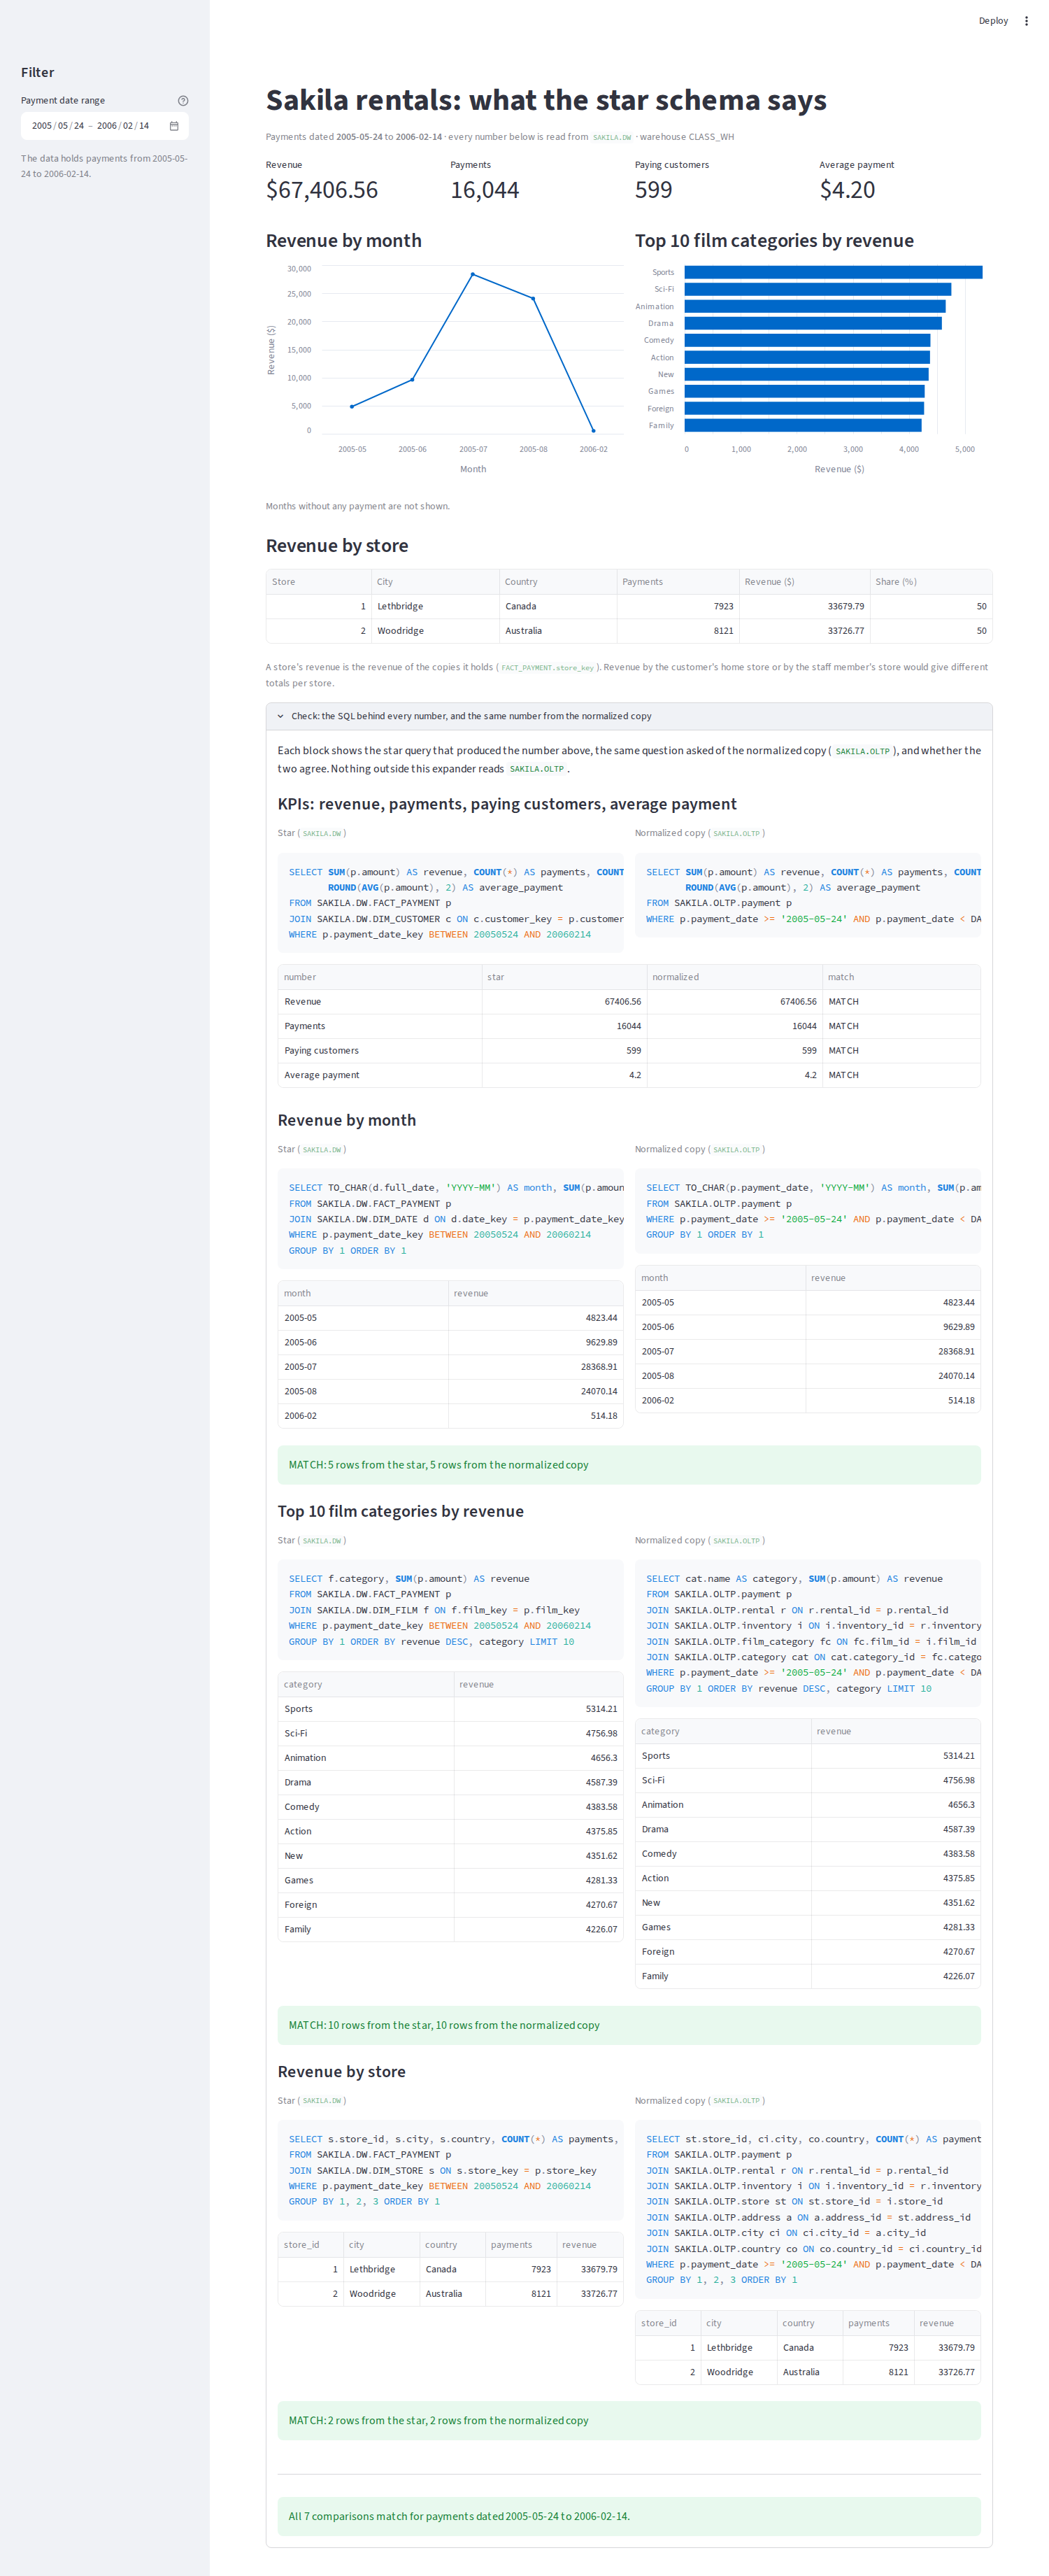

In [15]:
from IPython.display import Image, display
display(Image(filename="docs/images/dashboard_unfiltered.png", width=900))

**Filtered** — payments from 2005-06-01 to 2005-07-15, set by typing into the date widget: every KPI, both charts, the store table and every block of the Check expander change, and all 7 comparisons still match.

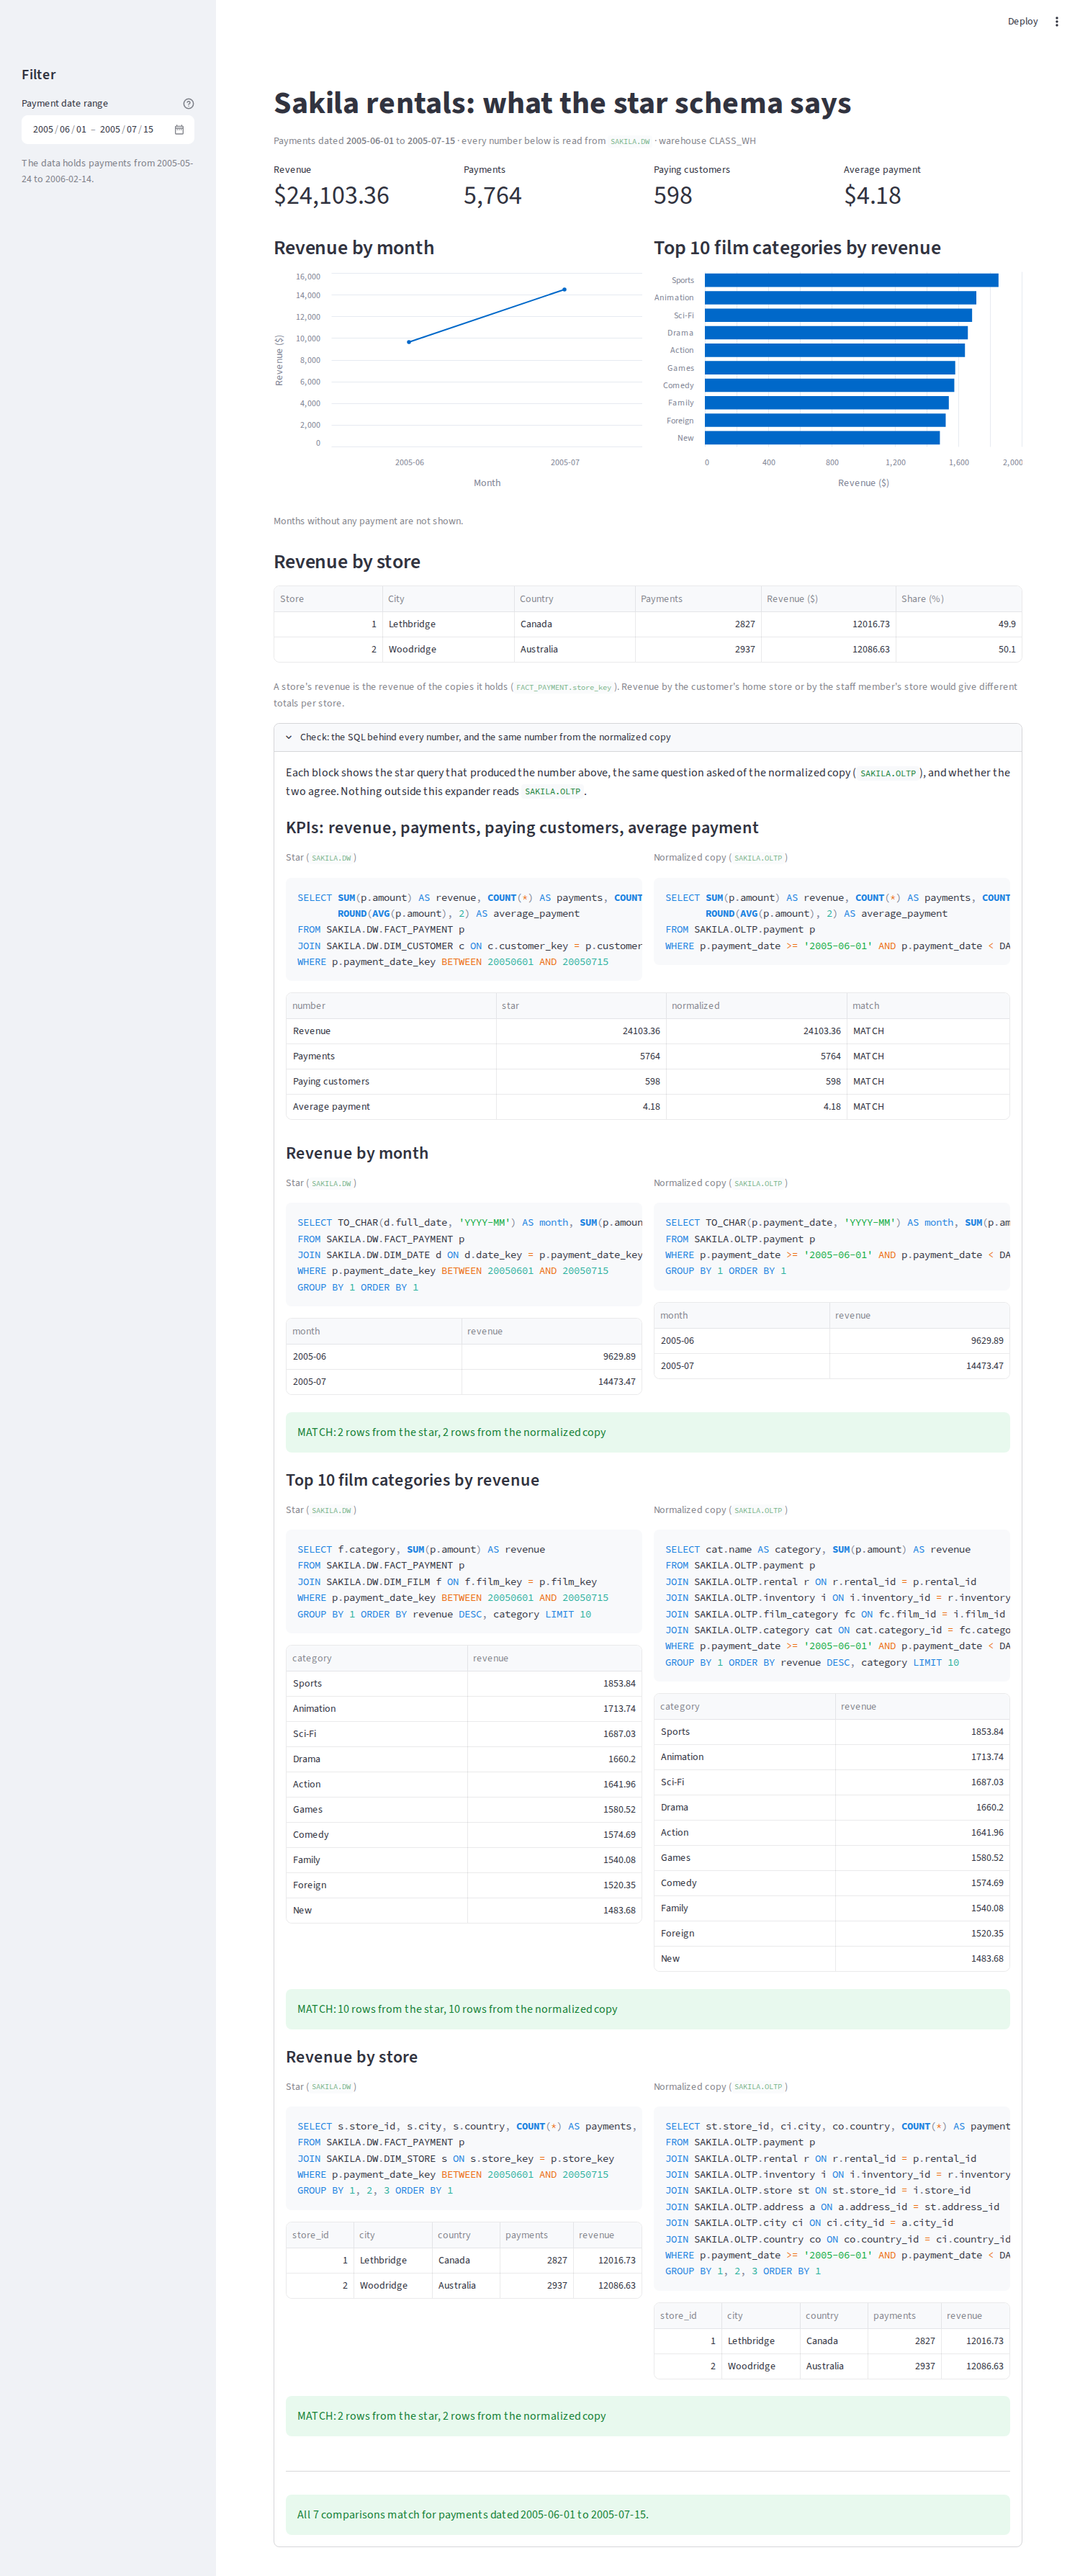

In [16]:
display(Image(filename="docs/images/dashboard_filtered.png", width=900))

---
# Reflection: why this grain, what broke, what would break first

Every claim below is tied to a number produced earlier in this notebook or measured while writing this part. Where a number is an extrapolation it says so. The Snowflake figures are queried live when the notebook runs; the memory figure for the exporter is measured on this machine with the same dump file that was imported into Cloud SQL. How each mistake was caught, and which ones were Claude's own, is recorded in AI verification (`docs/ai_verification.md`).

## 6.1 Why this grain? What does it make easy, and what impossible?

**The choice.** Two fact tables, each at the grain of the lowest-level event Sakila records, and each grain is written into the table's `COMMENT` in the DDL:
- `FACT_RENTAL`: one row per rental (`rental_id`): one copy rented by one customer on one date, handled by one staff member.
- `FACT_PAYMENT`: one row per payment (`payment_id`): one amount paid by one customer to one staff member on one date.

**Why two facts and not one.** Rentals and payments match one to one by count (16,044 each), which tempts a single fact: a rental row with an amount column. The data argues against it:
- In **8,078** payments the staff member who took the payment is not the one who handled the rental, and in **7,317** payments the amount is not the film's rental rate. The amount is an event of its own, not an attribute of the rental or the film.
- A rental is unfinished when it starts: the return arrives later (183 rentals are still out). `FACT_RENTAL` is therefore a row the MERGE updates in place, while a payment never changes once written.
- At event grain every measure is additive (`amount`, `rental_count`, `days_out`), and the totals reconcile to the normalized copy to the cent (67,406.56).
- Customer and film are looked up *as they were at the event* (Type 2), so a later change never rewrites old facts.

**What it makes easy.** Any sum, count or average over events, cut by any dimension: revenue by month, category, store, staff member or customer country; top categories; rentals and days out per film; customers by store. The business questions and the Dashboard app are exactly this, and every number they show reconciles with the normalized copy. It also makes history cheap: after a customer moved from Japan to Spain, the star still reported her earlier payments under Japan (3,470.75 for Japan against 3,352.07 in the normalized copy, which can only see where she lives now), and any single rental or payment can be traced to its row.

**What it makes impossible, or wrong.**

| The question | Why this grain cannot answer it | What I measured | What would fix it |
|---|---|---|---|
| Revenue by actor | Films and actors are many-to-many and the link table is not in the star | A plain join counts each payment once per actor: 367,559.07, which is 5.45 times the real 67,406.56 | A bridge table with a weighting factor, plus an "unknown actor" member (3 films have no actor: 199.60) |
| How many copies were on the shelf at a store on a given day | The fact records only the moments a copy leaves; a copy sitting on a shelf produces no row | 42 of 1,000 films and 1 of 4,581 copies were never rented, so they have no fact row at all | A snapshot fact: one row per copy per day |
| Revenue per rental day, or revenue by rental month, in one query | It needs both facts, which are different processes; `FACT_PAYMENT` has no rental date | Joining the two facts on `film_key` inflates revenue 19.3 times (see 6.2) | Aggregate each fact on its own and combine on a shared attribute; add `rental_date_key` to the payment fact |
| Anything below a payment: instalments, late fees, refunds, time of day | Each rental has exactly one payment, no amount is negative, and the date dimension stops at the day | Smallest amount is 0.00 (24 payments are zero) | A payment-line fact or a time-of-day dimension |
| "Revenue by store" as a single number | Three defensible meanings; the grain does not choose | Store 1: 36,997.53 (customer's home store), 33,482.50 (staff member's store), 33,679.79 (store holding the copy) | Decide and document; the star uses the copy's store. Staff and store are Type 1, so the staff member's store *as it was* is lost |
| How many customers | The dimension's grain is the version, not the person | After one move `COUNT(*)` gave 600 customers; the truth is 599 | `COUNT(DISTINCT customer_id)` or the `is_current` flag |

The cell below produces the data facts quoted above.

In [2]:
facts = snow("""
SELECT 'rentals' AS fact, COUNT(*) AS n FROM SAKILA.DW.FACT_RENTAL UNION ALL
SELECT 'payments', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT UNION ALL
SELECT 'payments taken by a different staff member than the one who handled the rental', COUNT(*) FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.FACT_RENTAL r ON r.rental_id = p.rental_id WHERE p.staff_key <> r.staff_key UNION ALL
SELECT 'payments whose amount differs from the film rental rate', COUNT(*) FROM SAKILA.OLTP.payment p JOIN SAKILA.OLTP.rental r ON r.rental_id = p.rental_id JOIN SAKILA.OLTP.inventory i ON i.inventory_id = r.inventory_id JOIN SAKILA.OLTP.film f ON f.film_id = i.film_id WHERE p.amount <> f.rental_rate UNION ALL
SELECT 'payments whose customer differs from the rental customer', COUNT(*) FROM SAKILA.OLTP.payment p JOIN SAKILA.OLTP.rental r ON r.rental_id = p.rental_id WHERE p.customer_id <> r.customer_id UNION ALL
SELECT 'rentals not yet returned', COUNT_IF(return_date_key = -1) FROM SAKILA.DW.FACT_RENTAL UNION ALL
SELECT 'films in the catalogue', COUNT(*) FROM SAKILA.OLTP.film UNION ALL
SELECT 'films never rented (no fact row at all)', COUNT(*) FROM SAKILA.OLTP.film f WHERE NOT EXISTS (SELECT 1 FROM SAKILA.OLTP.inventory i JOIN SAKILA.OLTP.rental r ON r.inventory_id = i.inventory_id WHERE i.film_id = f.film_id) UNION ALL
SELECT 'physical copies', COUNT(*) FROM SAKILA.OLTP.inventory UNION ALL
SELECT 'copies never rented', COUNT(*) FROM SAKILA.OLTP.inventory i WHERE NOT EXISTS (SELECT 1 FROM SAKILA.OLTP.rental r WHERE r.inventory_id = i.inventory_id) UNION ALL
SELECT 'negative payment amounts', COUNT_IF(amount < 0) FROM SAKILA.OLTP.payment UNION ALL
SELECT 'zero payment amounts', COUNT_IF(amount = 0) FROM SAKILA.OLTP.payment""")
facts["n"] = facts.n.astype(int)
display(facts.style.hide(axis="index").format({"n": "{:,}"}))
assert facts.set_index("fact").n["payments whose customer differs from the rental customer"] == 0

fact,n
rentals,"16,044"
payments,"16,044"
payments taken by a different staff member than the one who handled the rental,"8,078"
payments whose amount differs from the film rental rate,"7,317"
payments whose customer differs from the rental customer,0
rentals not yet returned,183
films in the catalogue,"1,000"
films never rented (no fact row at all),42
physical copies,"4,581"
copies never rented,1


## 6.2 What broke?

The question names three kinds of failure. Here is what happened to each, then the smaller things that also went wrong.

**A type conversion: it broke, twice.**
- *What:* the first run of the DDL failed with "Default value data type does not match data type for column LAST_UPDATE".
- *Why:* MySQL's `TIMESTAMP` and `DATETIME` became `TIMESTAMP_NTZ(0)`, but `CURRENT_TIMESTAMP()` returns a `TIMESTAMP_LTZ` and `SYSDATE()` a `TIMESTAMP_NTZ(9)`, and Snowflake accepted neither as the default.
- *How I knew:* Snowflake refused the very first `CREATE TABLE`. I tested both candidates on throw-away tables; `CURRENT_TIMESTAMP()::TIMESTAMP_NTZ(0)` worked and is now used for all 15 defaults.
- *The second one was caught before loading:* 6 of the 603 address points have impossible coordinates (address 63 has a longitude of 766,456,911). MySQL accepts them because the column is a planar `GEOMETRY`; Snowflake's `GEOGRAPHY` would have rejected them. A range assertion in my export script stopped the run, and the column became `GEOMETRY`.

**A MERGE that duplicated rows: it did not, and here is how I know.**
- *The risk was real:* Snowflake does not enforce primary or unique keys, the Type 2 MERGE stages every changed row twice (once to close the old version, once, with a NULL key, to insert the new one), and the fact MERGEs pick a version with a range join, so a bug or an overlapping interval would insert a second row silently.
- *The evidence:* re-running the unchanged `sql/05` inserted and updated **0** rows every time (runs 2, 4 and 5 in the logs, and again when I re-verified); the only run that inserted anything was the one that extended the calendar, by exactly the 8,766 days I meant to add. The live cell below shows 0 duplicate keys in both facts, exactly one current version per customer and film, and no overlapping intervals. The rolled-back demos showed exactly one new version per change, and an UPDATE, not an INSERT, when a rental came back.

**A join that multiplied totals: it broke in analysis, on purpose, to measure it.**
- *What:* joining the two facts on `film_key` without aggregating first gives revenue of 1,303,261.27 against the true 67,406.56 (19.3 times) and 311,350 rentals against 16,044. The same mechanism gave the 5.45 times on actors, and `COUNT(*)` on a Type 2 dimension gave 600 customers for 599.
- *Why:* every rental of a film pairs with every payment for that film, and a Type 2 dimension has one row per version.
- *How I knew:* each total is reconciled against `SUM(amount)` and the row counts of the normalized copy (67,406.56 and 16,044), which is what exposed it. The model carries the lesson: the DDL says not to join the facts on `rental_id`, and `sql/06` asserts the totals.

**Other things that broke (mine), and how each was caught**

| What | How it was caught |
|---|---|
| A typo in the foreign-key check (`store.manager_staff_id` compared with a column `store` does not have) | Snowflake's "invalid identifier" error on the first run |
| A wrong claim that payments differ from their rental in "customer or staff" (it is staff only) | The review check in AI verification: 0 payments differ in customer, 8,078 in staff |
| An expectation that dropping a redundant date filter would scan fewer bytes | The before and after plans were identical and read the same bytes: Snowflake had already removed the filter (the date key's minimum and maximum equal the filter's bounds) |
| A timing gap of about 100 ms that looked like an improvement | Swapping the order of the runs made it vanish (91 against 90 ms), and the same query run six times varied by 21 ms |
| The headless dictionary run documented the wrong schema (`CLASSICMODELS.DW`) | Reading its output, and the tool log, which showed its first query |
| The first Streamlit server listened on all network interfaces | The start-up message printed an external address; I restarted it bound to localhost only |

The cell below re-measures the join trap and the integrity checks live.

In [3]:
import re
trap = snow("""SELECT ROUND(SUM(p.amount), 2) AS sum_amount_after_join, (SELECT ROUND(SUM(amount), 2) FROM SAKILA.DW.FACT_PAYMENT) AS true_sum_amount,
       ROUND(SUM(p.amount) / (SELECT SUM(amount) FROM SAKILA.DW.FACT_PAYMENT), 1) AS inflation_factor,
       SUM(r.rental_count) AS sum_rental_count_after_join, (SELECT SUM(rental_count) FROM SAKILA.DW.FACT_RENTAL) AS true_rentals
FROM SAKILA.DW.FACT_PAYMENT p JOIN SAKILA.DW.FACT_RENTAL r ON r.film_key = p.film_key""")
print("A join that multiplies totals: both facts joined on film_key without aggregating first")
display(trap.style.hide(axis="index"))
assert float(trap.inflation_factor[0]) > 19

integrity = snow("""SELECT (SELECT COUNT(*) - COUNT(DISTINCT rental_id) FROM SAKILA.DW.FACT_RENTAL) AS fact_rental_duplicate_keys,
       (SELECT COUNT(*) - COUNT(DISTINCT payment_id) FROM SAKILA.DW.FACT_PAYMENT) AS fact_payment_duplicate_keys,
       (SELECT COUNT(*) FROM (SELECT customer_id FROM SAKILA.DW.DIM_CUSTOMER GROUP BY 1 HAVING COUNT_IF(is_current) <> 1)) AS customers_without_one_current_version,
       (SELECT COUNT(*) FROM (SELECT film_id FROM SAKILA.DW.DIM_FILM GROUP BY 1 HAVING COUNT_IF(is_current) <> 1)) AS films_without_one_current_version,
       (SELECT COUNT(*) FROM SAKILA.DW.DIM_CUSTOMER a JOIN SAKILA.DW.DIM_CUSTOMER b ON a.customer_id = b.customer_id AND a.customer_key < b.customer_key AND a.valid_from < b.valid_to AND b.valid_from < a.valid_to) AS overlapping_customer_versions,
       (SELECT COUNT(*) FROM SAKILA.DW.DIM_FILM a JOIN SAKILA.DW.DIM_FILM b ON a.film_id = b.film_id AND a.film_key < b.film_key AND a.valid_from < b.valid_to AND b.valid_from < a.valid_to) AS overlapping_film_versions""")
print("A MERGE that duplicated rows: the checks that would have shown it (all must be 0)")
display(integrity.style.hide(axis="index"))
assert (integrity.iloc[0].astype(int) == 0).all()

def merge_counts(path):
    lines, out = open(path, encoding="utf-8").read().splitlines(), []
    for i, l in enumerate(lines):
        if l.startswith("| number of rows inserted"):
            vals = [int(x) for x in re.findall(r"\d+", lines[i + 2])]
            out.append(f"{vals[0]} / {vals[1] if len(vals) > 1 else 0}")
    return out
runs = {"run 1: first load": "evidence/dw_load_log_run1.txt", "run 2: re-run": "evidence/dw_load_log_run2.txt", "run 3: calendar extended": "evidence/dw_load_log_run3.txt",
        "run 4: re-run": "evidence/dw_load_log_run4.txt", "run 5: re-run": "evidence/dw_load_log_run5.txt"}
names = ["DIM_DATE", "DIM_STORE", "DIM_STAFF", "DIM_CUSTOMER", "DIM_FILM", "FACT_RENTAL", "FACT_PAYMENT"]
print("Rows inserted / updated by each MERGE, run by run (from the saved logs)")
display(pd.DataFrame({k: merge_counts(v) for k, v in runs.items()}, index=names))

A join that multiplies totals: both facts joined on film_key without aggregating first


sum_amount_after_join,true_sum_amount,inflation_factor,sum_rental_count_after_join,true_rentals
1303261.27,67406.56,19.3,311350,16044


A MERGE that duplicated rows: the checks that would have shown it (all must be 0)


fact_rental_duplicate_keys,fact_payment_duplicate_keys,customers_without_one_current_version,films_without_one_current_version,overlapping_customer_versions,overlapping_film_versions
0,0,0,0,0,0


Rows inserted / updated by each MERGE, run by run (from the saved logs)


,run 1: first load,run 2: re-run,run 3: calendar extended,run 4: re-run,run 5: re-run
DIM_DATE,731 / 0,0 / 0,8766 / 0,0 / 0,0 / 0
DIM_STORE,2 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_STAFF,2 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_CUSTOMER,599 / 0,0 / 0,0 / 0,0 / 0,0 / 0
DIM_FILM,1000 / 0,0 / 0,0 / 0,0 / 0,0 / 0
FACT_RENTAL,16044 / 0,0 / 0,0 / 0,0 / 0,0 / 0
FACT_PAYMENT,16044 / 0,0 / 0,0 / 0,0 / 0,0 / 0


## 6.3 What would break first at scale?

**Assumption.** Every table a thousand times larger: about 16 million rentals and payments, 600,000 customers and a million films. I did not build a larger copy, so every "at 1,000 times" figure below is a straight-line extrapolation from today's size, and says so. For the Snowflake parts I extrapolate data *volume* (bytes read), because timings at this size are mostly fixed overhead.

**Answer: the load fails soonest, and within it my Python exporter, which stops being usable at roughly a hundred times today's size. The MERGE loads and the app slow down but keep working. The star is the last thing to worry about.**

| Part | Measured today | At 1,000 times (extrapolated) | What breaks |
|---|---|---|---|
| **Load, step 1: the Python exporter** | About 1.1 s and 41 MB of memory for a 3.35 MB dump (13 times the file) | A 3.35 GB dump and about 40 GB of memory | It reads the whole dump into one string and keeps every row in lists. On a 4 GB machine it runs out at about 100 times |
| **Load, step 2: the MERGEs** | A re-run that changes nothing takes 0.7–0.9 s per MERGE and reads 117–377 KB, *more* than the first load that inserted everything (52–288 KB) | Each MERGE reads 0.1–0.4 GB | They are full refreshes: each run reads and compares all of the source and all of the target, so cost grows with total history, not with the rows that changed |
| **App** | One page render sent 8 queries: the 4 hidden Check queries took 4,867 ms (69% of the render) and read 735 KB, against 2,201 ms and 464 KB for the 4 star queries | About 0.7 GB read for the Check queries and 0.5 GB for the page, per render | The Check queries run on every render, even with the expander closed, and each new filter value is a new query. Latency and warehouse load, not a crash |
| **Star** | Whole star 0.62 MB; `FACT_RENTAL` 15 bytes per row compressed | 0.62 GB in total, `FACT_RENTAL` about 236 MB | Nothing soon. Date filters keep pruning only if rows keep arriving in date order. Unenforced keys get harder to audit |

**Why the exporter first, and why not the others.** The exporter is the only part whose cost grows with *everything* and whose limit is a hard wall (memory), not a slower query. The Snowflake parts handle sub-gigabyte scans comfortably on an X-Small warehouse; I would expect seconds rather than hours for the MERGEs and the page, but I have not tested it. What I can show is *why* they would degrade first, if anything: the MERGEs redo all the work every run, and the app does 69% of its render in queries nobody asked to see.

**What I would change first.**
- *Exporter:* stream it, parsing and writing one INSERT statement at a time instead of holding the file; better still, export from Cloud SQL straight to CSV in a bucket and `COPY INTO` from there.
- *MERGEs:* make them incremental: a Snowflake stream on each source table, or a high-water mark, so each run touches only new and changed rows. Run the batch on a larger warehouse and let `AUTO_SUSPEND = 60` suspend it afterwards.
- *App:* run the Check only on request (a button), and serve the page from small monthly and category aggregates instead of the fact table.
- *Star:* cluster the facts by `payment_date_key` and `rental_ts` once they are big enough to have many micro-partitions.

**What I did not test.** No larger copy was built. A realistic next step is a 100-times synthetic copy in a throw-away schema, to measure where the MERGE and the Check queries actually bend; I held back because that would create objects.

The cell below produces the measurements quoted in the table.

In [4]:
import os, shutil, subprocess, sys, tempfile
merge = snow("""
SELECT SPLIT_PART(SPLIT_PART(query_text, 'MERGE INTO ', 2), ' ', 1) AS target,
       CASE WHEN rows_inserted >= 500 THEN 'first load' WHEN rows_inserted = 0 THEN 're-run (no change)' ELSE 'demo' END AS kind,
       COUNT(*) AS runs, ROUND(MEDIAN(total_elapsed_time)) AS elapsed_ms, ROUND(MEDIAN(execution_time)) AS exec_ms,
       ROUND(MEDIAN(bytes_scanned)) AS bytes_read, ROUND(MEDIAN(bytes_scanned) * 1000 / 1e9, 2) AS gb_at_1000x
FROM SNOWFLAKE.ACCOUNT_USAGE.QUERY_HISTORY
WHERE query_type = 'MERGE' AND start_time >= DATEADD('day', -4, CURRENT_TIMESTAMP()) AND execution_status = 'SUCCESS'
  AND query_text ILIKE 'MERGE INTO %' AND query_text ILIKE '%SAKILA.OLTP%'
GROUP BY ALL HAVING target IN ('DIM_CUSTOMER', 'DIM_FILM', 'FACT_RENTAL', 'FACT_PAYMENT') AND kind <> 'demo' ORDER BY target, kind""")
print("The MERGEs: a first load against a re-run that changes nothing (medians; X-Small warehouse)")
display(merge.style.hide(axis="index"))
assert (merge.runs.astype(int) >= 1).all() and len(merge) == 8

sizes = snow("""SELECT table_schema AS schema, ROUND(SUM(bytes) / 1e6, 2) AS mb_now, ROUND(SUM(bytes) * 1000 / 1e9, 2) AS gb_at_1000x, SUM(row_count) AS rows_now
FROM SAKILA.INFORMATION_SCHEMA.TABLES WHERE table_schema IN ('OLTP', 'DW') GROUP BY 1 ORDER BY 1""")
print("Size of the star (DW) and of the normalized copy (OLTP)")
display(sizes.style.hide(axis="index"))

app = snow("""
SELECT IFF(q.query_text ILIKE '%SAKILA.OLTP.payment p%', 'Check expander (normalized copy)', 'page (star)') AS part, COUNT(*) AS queries,
       SUM(q.total_elapsed_time) AS elapsed_ms, SUM(q.compilation_time) AS compile_ms, SUM(q.execution_time) AS exec_ms, SUM(q.bytes_scanned) AS bytes_read
FROM SNOWFLAKE.ACCOUNT_USAGE.QUERY_HISTORY q JOIN SNOWFLAKE.ACCOUNT_USAGE.SESSIONS s ON s.session_id = q.session_id AND s.client_application_id = 'PythonConnector 4.8.0'
WHERE q.start_time BETWEEN '2026-10-25 17:01:27'::TIMESTAMP_LTZ AND '2026-10-25 17:01:34'::TIMESTAMP_LTZ AND q.role_name = 'ACCOUNTADMIN'
  AND q.query_text ILIKE '%payment_date%' AND q.query_text NOT ILIKE '%ACCOUNT_USAGE%'
GROUP BY 1 ORDER BY 1""")
app["share_of_elapsed"] = (app.elapsed_ms.astype(int) / app.elapsed_ms.astype(int).sum()).map("{:.0%}".format)
print("One real render of the app in Snowflake (17:01:28 to 17:01:33 on 25 October): the page's own queries against the Check expander's")
display(app.style.hide(axis="index"))

# the exporter, measured in a fresh process so that earlier child processes cannot inflate the peak
dump = "sakila-db/sakila-data.sql"  # the public Sakila dump, unpacked next to the repo (see README)
script = "src/export_sakila_csv.py"
if os.path.exists(dump):
    outer = tempfile.mkdtemp()
    wrapper = ("import resource, subprocess, sys, time\n"
               "t0 = time.time()\n"
               "r = subprocess.run([sys.executable, '-I', sys.argv[1], sys.argv[2], sys.argv[3]], capture_output=True, text=True)\n"
               "print(r.returncode, time.time() - t0, resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss)\n")
    out = subprocess.run([sys.executable, "-c", wrapper, script, dump, os.path.join(outer, "csv")], capture_output=True, text=True).stdout.split()
    shutil.rmtree(outer)
    code_, secs, peak_kb = int(out[0]), float(out[1]), float(out[2])
    size = os.path.getsize(dump)
    assert code_ == 0
    print(f"The Python exporter, today's size: dump {size / 1e6:.2f} MB, {secs:.1f} s, peak memory {peak_kb / 1024:.0f} MB ({peak_kb * 1024 / size:.0f} times the file)")
    scale = pd.DataFrame({"times today's size": [1, 10, 30, 100, 1000]})
    f = scale.iloc[:, 0]
    scale["dump (MB)"] = size * f / 1e6
    scale["peak memory (GB), extrapolated"] = peak_kb * f / 1024 / 1024
    scale["time (s), extrapolated"] = secs * f
    display(scale.style.hide(axis="index").format({"dump (MB)": "{:,.0f}", "peak memory (GB), extrapolated": "{:,.2f}", "time (s), extrapolated": "{:,.0f}"}))
else:
    print("The dump file is not on this machine, so the exporter was not re-measured here; measured earlier: 3.35 MB dump, 1.2 s, 41 MB peak.")

The MERGEs: a first load against a re-run that changes nothing (medians; X-Small warehouse)


target,kind,runs,elapsed_ms,exec_ms,bytes_read,gb_at_1000x
DIM_CUSTOMER,first load,1,1056,354,60416,0.06
DIM_CUSTOMER,re-run (no change),8,717,180,116992,0.12
DIM_FILM,first load,1,1213,473,51712,0.05
DIM_FILM,re-run (no change),8,746,208,119552,0.12
FACT_PAYMENT,first load,1,2380,359,288288,0.29
FACT_PAYMENT,re-run (no change),9,842,164,377344,0.38
FACT_RENTAL,first load,1,1424,401,229920,0.23
FACT_RENTAL,re-run (no change),9,879,221,340680,0.34


Size of the star (DW) and of the normalized copy (OLTP)


schema,mb_now,gb_at_1000x,rows_now
DW,0.62,0.62,43188
OLTP,0.58,0.58,47268


One real render of the app in Snowflake (17:01:28 to 17:01:33 on 25 October): the page's own queries against the Check expander's


part,queries,elapsed_ms,compile_ms,exec_ms,bytes_read,share_of_elapsed
Check expander (normalized copy),4,4867,4178,689,735280,69%
page (star),4,2201,1388,700,463888,31%


The Python exporter, today's size: dump 3.35 MB, 1.1 s, peak memory 41 MB (13 times the file)


times today's size,dump (MB),"peak memory (GB), extrapolated","time (s), extrapolated"
1,3,0.04,1
10,34,0.40,11
30,101,1.19,32
100,335,3.97,106
1000,"3,352",39.72,"1,064"


---
# Notes and where everything is
- **Role note:** the upload and the loads were run with `--role SYSADMIN` through the `claude` connection after write access was enabled for it. Every cell in this notebook is a SELECT (the Dashboard cells only display files and saved output); the scripts that change the source (`sql/07`, `sql/08` section 3.2) do it inside a transaction that ends in `ROLLBACK` and are shown as saved logs.
- **Not migrated** (only the tables were in scope): 7 views, 6 stored routines, 5 triggers, secondary indexes, the FULLTEXT index on `film_text`, `ON DELETE`/`ON UPDATE` actions. Foreign keys are recorded in Snowflake but not enforced, which is why every part proves them with orphan counts.
- **The Cloud SQL step** (stopping or deleting the instance, with a screenshot) is not part of this notebook.
- The next cell checks that every deliverable and log named here exists and is not empty.

In [17]:
expected = (["src/export_sakila_csv.py", "evidence/export_log.txt", "data/source_counts.csv", "data/source_control_totals.csv",
             "sql/00_source_counts_mysql.sql", "evidence/load_log.txt", "evidence/dw_checks_log.txt", "evidence/scd2_demo_log.txt", "evidence/business_questions_log.txt",
             "docs/migration.md", "docs/dimensional_model.md", "docs/business_questions.md", "docs/dashboard.md", "docs/prompt_log.md",
             "app/streamlit_app.py", "docs/images/dashboard_unfiltered.png", "docs/images/dashboard_filtered.png", "app/take_screenshots.py",
             "app/verify_streamlit_app.py", "evidence/dashboard_verify_log.txt"]
            + [f"evidence/dw_load_log_run{i}.txt" for i in range(1, 6)]
            + [f"sql/{n}" for n in ("01_oltp_ddl.sql", "02_oltp_load_reconcile.sql", "03_read_only_grants.sql", "04_dw_ddl.sql",
                                    "05_dw_load_merge.sql", "06_dw_checks.sql", "07_scd2_demo.sql", "08_business_questions.sql")]
            + [f"data/csv/{t}.csv" for t in src.tbl])
files = pd.DataFrame({"file": expected, "bytes": [os.path.getsize(p) if os.path.exists(p) else None for p in expected]})
missing = files[files.bytes.isna() | (files.bytes == 0)]
display(files.style.hide(axis="index").format({"bytes": "{:,.0f}"}))
assert missing.empty, missing
print(f"{len(files)} deliverable files and logs present, none empty")

file,bytes
src/export_sakila_csv.py,"12,009"
evidence/export_log.txt,"1,745"
data/source_counts.csv,215
data/source_control_totals.csv,739
sql/00_source_counts_mysql.sql,"3,427"
evidence/load_log.txt,"35,697"
evidence/dw_checks_log.txt,"21,025"
evidence/scd2_demo_log.txt,"58,175"
evidence/business_questions_log.txt,"32,498"
docs/migration.md,"9,842"


49 deliverable files and logs present, none empty


The before and after Query Profile screenshots from Snowsight are left out of the public repo because they show account and login details. The numbers they illustrate (bytes scanned, partitions, operator times) are recorded in `docs/ai_verification.md` and `evidence/ai_checks/`.